# Week 3 - Matplotlib & Seaborn

**Completed Python assignment: Parts A-E**

Course: CDB601220. All supplied observations are **synthetic**. Charts demonstrate visual/statistical failure modes, not real patient or policy findings.

The notebook includes the complete code for each required part, executed results and figures. Extract the ZIP before running. The optional five-classmate bonus has no real participant timings and is not presented as completed. Rename the ZIP with your roll number for LMS submission.

In [1]:
from pathlib import Path
import sys
BASE = Path.cwd()
if not (BASE / 'data' / 'vitals_10k.csv').exists():
    BASE = BASE / 'W3_Assignment'
assert (BASE / 'data' / 'vitals_10k.csv').exists(), 'Run in the extracted assignment folder.'
sys.path.insert(0, str(BASE))
from IPython.display import display, Image, Markdown
from common import ROOT, OUT
print('Input folder:', ROOT / 'data')
print('All data: synthetic CDB601220 Week 3 course files.')

Input folder: /workspace/scratch/506841d334a6/W3_Assignment/data
All data: synthetic CDB601220 Week 3 course files.


## Reusable figure and data helpers

All figures use the object-oriented Matplotlib API. The helper saves at 300 dpi before display; exported images are explicitly displayed below. The code below documents `common.py`, which is imported by all required scripts. `vizlib.py` is the unmodified supplied toolkit.

In [2]:
print((BASE / 'common.py').read_text())

from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from vizlib import PALETTE, style_defaults, save_fig
ROOT=Path(__file__).resolve().parent
OUT=ROOT/'figures'; OUT.mkdir(exist_ok=True)
SOURCE='Source: synthetic CDB601220 Week 3 course data; not real-world evidence.'
C=PALETTE['series']
style_defaults()
def read(name): return pd.read_csv(ROOT/'data'/f'{name}.csv')
def finish(fig,name,note=''):
    for a in fig.axes:
        for side in ['top','right']: a.spines[side].set_visible(False)
    fig.tight_layout()
    from io import BytesIO
    fig.text(.01,-.035,SOURCE+'\n'+note,fontsize=7,color=PALETTE['ink_soft'],ha='left',va='top')
    buffer=BytesIO()
    fig.savefig(buffer,format='png',dpi=300,bbox_inches='tight',facecolor='white')
    path=OUT/f'{name}.png'
    tmp=path.with_suffix('.tmp')
    tmp.write_bytes(buffer.getvalue())
    tmp.replace(path)
    pl

## Part A - Nine reconstructions and nine redesigns

For each case: reproduce the analyst recipe, check its numbers, state the invited conclusion, reject a tempting decoy, identify the mechanism with evidence, and actually plot a redesign. Cases 4 and 5 require tables as their reconstructions. The misleading dual-axis reconstruction is included solely because case 7 explicitly asks for it.

**Case 9 discrepancy:** the supplied data and default Scott Gaussian KDE produce approximately **1.565%**, not the headline 4.4%, above 100%. The calculation is preserved transparently; no readings exceed 100%.

In [3]:
from common import *
from scipy.stats import gaussian_kde
DIAGNOSES=[]
def record(k,title,conclusion,decoy,mechanism,redesign):
    DIAGNOSES.append(dict(case=k,title=title,conclusion=conclusion,decoy=decoy,mechanism=mechanism,redesign=redesign))
def main():
    DIAGNOSES.clear()
    d=read('case01_helmet_rickshaw');g=d.groupby('helmet_grade')[['trips','head_injuries']].sum();rates=g.head_injuries/g.trips*1000
    assert np.allclose(rates.loc[['Standard','Premium']],[2.15,5.4])
    fig,ax=plt.subplots(figsize=(7,4));ax.bar(rates.index,rates,color=C[:2]);ax.set(ylim=(0,6),ylabel='Head injuries / 1,000 trips',title='Aggregate rates make Premium helmets look worse');finish(fig,'A01_original','n=1,000 riders; trip-weighted rates; no rows removed; zero baseline.')
    s=d.groupby(['road_type','helmet_grade'])[['trips','head_injuries']].sum();r=(s.head_injuries/s.trips*1000).unstack()
    fig,ax=plt.subplots(figsize=(8,4));r.plot.bar(ax=ax,color=C[:2],rot=0);ax.set(ylabel='Head injuries / 1,000 trips',ylim=(0,9),title='Premium has a lower injury rate in every road type');finish(fig,'A01_redesign','All riders retained; road-specific trip denominators; zero baseline.')
    weights=d.groupby('road_type').trips.sum()/d.trips.sum();standardized=r.mul(weights,axis=0).sum()
    record(1,'Helmet grades and road exposure','The aggregate chart invites a claim that Premium certification is less safe.','A truncated baseline cannot explain this: the bars start at zero. Speed alone is not the mechanism: within-road mean speeds differ only about 1-2 km/h, and Premium rates remain lower within every road type.',f"Simpson's paradox from road-type composition: 85% of Premium trips but only 3.33% of Standard trips are motorway trips. Motorway rates are 6 vs 8, arterial 2.2 vs 3, lanes 1 vs 1.395 (Premium vs Standard). Common road weights give {standardized.to_dict()} injuries/1,000.",'Compare trip-weighted rates within road type, with shared zero baseline; no causal helmet-effect estimate is claimed.')
    d=read('case02_chai_quizzes');x=d.cups_doodh_patti_sold;y=d.quiz_failures;r=x.corr(y);assert round(r,2)==.98
    fig,ax=plt.subplots(figsize=(7,4));ax.scatter(x,y,color=C[0]);xx=np.linspace(x.min(),x.max(),100);ax.plot(xx,np.polyval(np.polyfit(x,y,1),xx),color=C[1]);ax.set(xlabel='Chai cups sold / month',ylabel='Quiz failures / month',title=f'Chai and failure counts rise together: r={r:.3f}');finish(fig,'A02_original','n=24 months; ordinary least squares; all rows retained.')
    d['cups_per_student']=x/d.students_enrolled;d['failure_pct']=100*y/d.students_enrolled
    fig,ax=plt.subplots(figsize=(7,4))
    for exam,g in d.groupby('is_exam_month'):ax.scatter(g.cups_per_student,g.failure_pct,marker=['o','^'][exam],color=C[exam],label=['Teaching month','Exam month'][exam])
    ax.legend();ax.set(xlabel='Cups / enrolled student / month',ylabel='Quiz failures / enrolled students (%)',title=f'Per-student association is much weaker: r={d.cups_per_student.corr(d.failure_pct):.3f}');finish(fig,'A02_redesign','Denominator: students_enrolled; no rows removed; markers also identify exam status.')
    record(2,'Counts share an enrolment denominator','The published chart suggests chai consumption predicts failure.','Exam timing is a plausible first objection, but it cannot explain the dominant count trend: enrolment correlates 0.997 with cups and 0.977 with failures; exam status correlates only 0.035 with enrolment.',f'Population-size confounding: raw r={r:.3f}, per-student r={d.cups_per_student.corr(d.failure_pct):.3f}. Exam-month mean failure rates are 3.862% vs 3.415% in teaching months, so a residual association should not be erased or called zero.','Use per-student monthly rates and separate exam months by colour and shape; these are failure events, not a proven individual causal effect.')
    d=read('case03_aqi_monitors');d['day']=(pd.to_datetime(d.date)-pd.Timestamp('2026-01-01')).dt.days+1;daily=d.groupby('day').aqi.mean();b=d.loc[d.day<=60,'aqi'].mean();a=d.loc[d.day>60,'aqi'].mean()
    fig,ax=plt.subplots(figsize=(8,4));ax.plot(daily.index,daily,color=C[0]);ax.axvline(61,color=C[1],linestyle='--');ax.hlines([b,a],[1,61],[60,120],color=C[1]);ax.set(ylim=(0,350),xlabel='Day since 1 January 2026',ylabel='AQI (index)',title=f'Available-monitor mean falls {(1-a/b)*100:.1f}%');finish(fig,'A03_original',f'2,640 station-day rows; {d.aqi.isna().sum()} offline blanks skipped by mean, not imputed as zero.')
    complete=d.groupby('station_id').aqi.count();ids=complete[complete==120].index;balanced=d[d.station_id.isin(ids)];q=balanced.groupby('day').aqi.mean();bb=balanced.loc[balanced.day<=60,'aqi'].mean();aa=balanced.loc[balanced.day>60,'aqi'].mean()
    fig,ax=plt.subplots(figsize=(9,4));ax.plot(daily.index,daily,label='Changing reporting network',color=C[1],linestyle='--');ax.plot(q.index,q,label=f'Fixed {len(ids)}-station panel',color=C[0]);ax.axvline(61,color='gray',linestyle=':');ax.legend();ax.set(ylim=(0,350),xlabel='Day since 1 January 2026',ylabel='AQI (index)',title='The fixed-station AQI trend does not improve');finish(fig,'A03_redesign',f'Balanced sensitivity panel retains {len(balanced)} rows; excludes {len(d)-len(balanced)} rows from incomplete stations. Raw series remains visible.')
    record(3,'Missing monitors change the average','The chart invites attributing a 32% AQI improvement to the action plan.','The baseline is zero, so truncation is ruled out. A citywide seasonal improvement is not supported by the continuously reporting panel.',f'Informative missingness / changing network composition: 6 industrial and 3 arterial stations stop reporting; 540 AQI blanks, reporting stations fall 22 to 13. Available means {b:.2f} to {a:.2f}; balanced means {bb:.2f} to {aa:.2f}, change {(aa/bb-1)*100:+.2f}%.','Show raw and fixed-station trends together; do not fill missing high-pollution stations with zeros or assert full-city improvement.')
    for case,file,group,x,y in [(4,'case04_quartet_depts','department','study_hours_per_week','final_score_out_of_20'),(5,'case05_same_stats_shapes','shape_name','hours_on_platform','assessment_score')]:
        d=read(file);t=summaries(d,group,x,y);t.to_csv(ROOT/'outputs'/f'A{case:02d}_summary.csv');table_plot(t,'Matching summaries hide different geometries',f'A{case:02d}_original')
        groups=list(d.groupby(group));fig,axes=plt.subplots(1,len(groups),figsize=(3.2*len(groups),3.6),sharex=True,sharey=True)
        for ax,(label,g) in zip(axes,groups):
            ax.scatter(g[x],g[y],s=16,alpha=.75,color=C[0]);xx=np.linspace(d[x].min(),d[x].max(),100);ax.plot(xx,np.polyval(np.polyfit(g[x],g[y],1),xx),color=C[1],linestyle='--');ax.set(title=label,xlabel='Study hours / week' if case==4 else 'Platform hours')
        axes[0].set_ylabel('Final score / 20' if case==4 else 'Assessment score');finish(fig,f'A{case:02d}_redesign','All rows retained; common limits; dashed OLS lines; population SD in summary tables.')
        if case==4:
            g=d[d.department=='Architecture'];i=g[x].idxmax()
            record(4,'Equal statistics conceal the quartet','Equal summaries invite equal funding and identical department models.','Small n alone is not the explanation: all departments have the same n=11, means approximately 18/14.5 and r approximately .816, yet very different geometry.','Insufficient summaries: one department is roughly linear, one curved, one driven by a score outlier, and Architecture has only two distinct x values (10 at one x, one high-leverage point). Removing that x-extreme leaves constant x, so Pearson r is undefined, not evidence of a stable slope.','Plot all four departments on common axes; show fitted lines to reveal where identical fits misrepresent the observations.')
        else:
            record(5,'Moment matching preserves different shapes','Equal means, SDs and correlations invite treating five cohorts as interchangeable.','Not a small-sample artifact: each cohort has n=180 and deliberately matched moments. Population rather than sample SD is the convention behind the 12/15 self-check.','Non-identifiability from first/second moments: all five groups have mean 48/63, SD 12/15 and r=.420 to rounding, while scatter geometry differs. Covariance is about 75.6 and slope .525 for all; neither constrains clusters, curves or gaps.','Common-scale scatter small multiples expose the shapes without changing any row. Cohort names label the designed shapes, not automatically their final geometry after moment matching.')
    d=read('case06_sensor_matrix');cols=d.select_dtypes('number').columns.tolist();m=d[cols].corr();assert m.shape==(20,20)
    fig,ax=plt.subplots(figsize=(13,11));sns.heatmap(m,cmap='Reds',annot=True,fmt='.2f',ax=ax,annot_kws={'fontsize':6});ax.set_title('One extreme patient makes creatinine track HbA1c');finish(fig,'A06_original','Analyst recipe intentionally uses automatic colour limits, Reds and both triangles; n=180.')
    keep=[c for c in cols if not c.startswith('probe_') and c not in ['map_mmhg','deep_sleep_min','floors_climbed']];mm=d[keep].corr()
    fig,axes=plt.subplots(1,3,figsize=(18,5),gridspec_kw={'width_ratios':[1.7,1,1]});sns.heatmap(mm,mask=np.triu(np.ones_like(mm,dtype=bool)),cmap='RdBu_r',vmin=-1,vmax=1,center=0,annot=True,fmt='.2f',annot_kws={'fontsize':6},ax=axes[0]);axes[0].set_title('Signed scale fixes drawing, not inference')
    i=d.creatinine.idxmax();axes[1].scatter(d.creatinine,d.hba1c,color=C[0],s=18);axes[1].annotate('Influential observation',xy=(d.loc[i,'creatinine'],d.loc[i,'hba1c']),xytext=(350,12),arrowprops={'arrowstyle':'->'});axes[1].set(title='All 180: r=.765',xlabel='Creatinine (umol/L)',ylabel='HbA1c (%)')
    z=d.drop(i);axes[2].scatter(z.creatinine,z.hba1c,color=C[0],s=18);axes[2].set(title=f'Sensitivity: 179, r={z.creatinine.corr(z.hba1c):.3f}',xlabel='Creatinine (umol/L)',ylabel='HbA1c (%)');finish(fig,'A06_redesign','Raw heatmap retains 180 rows. Sensitivity excludes exactly row index 0 (1050 umol/L, 15.8%); this is influence analysis, not an asserted device fault. Derived/redundant channels and six uncalibrated probes omitted from redesigned matrix.')
    within={k:round(float(g.resting_hr.corr(g.vo2max)),3) for k,g in d.groupby('hr_device_model')}
    record(6,'An influential point and redundant channels','The heatmap invites a new physiological link between creatinine and HbA1c.','The positive association is not mainly site confounding: the row at index 0 drives it even within Site C. An extreme value is not automatically erroneous and is retained in the primary analysis.',f'Outlier influence: r={d.creatinine.corr(d.hba1c):.3f}, versus {z.creatinine.corr(z.hba1c):.4f} without the 1050/15.8 observation. Other strong pairs include arithmetic/redundant channels (systolic-MAP .962). Resting-HR/VO2max has pooled r=.772 but within-device r={within}, showing device/site mixing; probes have no calibrated interpretation. With 20 variables there are 190 distinct pairwise tests, requiring exploratory caution.','A signed -1..1 diverging lower-triangle matrix repairs sign/scale/duplication. It cannot repair leverage, confounding or multiplicity: add raw and leave-one-out scatter, with exclusions explicit; omit uncalibrated and redundant channels from interpretation.')
    d=read('case07_dual_axis_series');fig,ax=plt.subplots(figsize=(8,4));other=ax.twinx();ax.plot(d.month,d.revenue_pkr_m,color=C[0],marker='o');other.plot(d.month,d.cost_pkr_m,color=C[1],marker='^');ax.set(ylim=(50,80),ylabel='Revenue (PKR million)',title='Independent axes manufacture a loss until May');other.set(ylim=(40,56),ylabel='Cost (PKR million)');finish(fig,'A07_original','Required reconstruction is the sole dual-axis exception: left 50-80, right 40-56. It is labelled misleading; never used as the redesign.')
    d['profit']=d.revenue_pkr_m-d.cost_pkr_m;fig,ax=plt.subplots(figsize=(8,4));ax.plot(d.month,d.revenue_pkr_m,color=C[0],marker='o',label='Revenue');ax.plot(d.month,d.cost_pkr_m,color=C[1],marker='^',label='Cost');ax.set(ylim=(0,85),ylabel='PKR million',title='Revenue exceeds cost in all six months');ax.legend();finish(fig,'A07_redesign','Common unit and common zero baseline; monthly profit 8, 12, 14, 17, 20, 25 PKR million.')
    revenue_pos=(d.revenue_pkr_m-50)/30;cost_pos=(d.cost_pkr_m-40)/16;assert (cost_pos>revenue_pos).tolist()==[True,True,True,True,False,False]
    record(7,'Independent axes manufacture a crossing','The line positions invite saying the business lost money through April.','Not different currencies or arithmetic errors: both columns are PKR millions; actual profits are positive in every row.',f'Incommensurable normalized positions: January revenue height (52-50)/30=.0667; cost (44-40)/16=.25. Cost is drawn higher even though 44<52. Actual profit grows from 8 to 25 million.','Put cost and revenue on one common axis with colour plus different marker shapes.')
    d=read('vitals_10k');fig,axes=plt.subplots(1,3,figsize=(12,3.7))
    for ax,bins in zip(axes,[3,45,400]):ax.hist(d.systolic,bins=bins,range=(92,199),color=C[0]);ax.set(title=f'{bins} bins; n=10,000',xlabel='Systolic BP (mmHg)',ylabel='Records')
    finish(fig,'A08_original','All three use identical 10,000 values and full 92-199 mmHg range; bin counts 3/45/400.')
    fig,ax=plt.subplots(figsize=(8,4));ax.hist(d.systolic,bins=np.arange(90,206,5),color=C[0],edgecolor='white');ax.set(title='A stable two-mode pattern appears at 5 mmHg bin width',xlabel='Systolic BP (mmHg)',ylabel='Records');finish(fig,'A08_redesign','Edges 90..205 step 5; n=10,000; no values excluded. Histogram reveals subpopulations but does not identify their cause.')
    record(8,'Binning changes the estimator, not the sample','The three panels invite three incompatible distribution stories.','Sample-size changes and exclusions are ruled out: n=10,000 with identical min=92 and max=199 in every panel.','Bias/variance and quantization: width 35.67 mmHg (3 bins) merges modes; width .2675 (400 bins) is below the 1 mmHg resolution and generates artificial empty bins. Width 2.378 (45 bins) exposes the mixture with more detail.','Use 5 mmHg equal-width bins, compare all three alternatives, and retain all observations; report two modes rather than claim normality.')
    kde=gaussian_kde(d.spo2,bw_method='scott');tail=kde.integrate_box_1d(100,np.inf);fig,ax=plt.subplots(figsize=(8,4));grid=np.linspace(d.spo2.min()-3*kde.factor*d.spo2.std(),108,512);ax.plot(grid,kde(grid),color=C[0]);ax.axvline(100,color=C[1],linestyle='--');ax.set(xlim=(78,108),xlabel='SpO2 (%)',ylabel='Density / percentage point',title=f'Gaussian KDE invents {tail*100:.2f}% probability above 100%');finish(fig,'A09_original','Scott bandwidth; bw_adjust=1; Gaussian kernel; grid=512; explicit support extension to 108; integral above 100 computed over [100,infinity).')
    fig,ax=plt.subplots(figsize=(8,4));counts=d.spo2.value_counts().sort_index();ax.bar(counts.index,counts/len(d),width=.85,color=C[0]);ax.set(xlim=(80.5,100.5),xlabel='SpO2 (%)',ylabel='Observed probability',title='Observed oxygen saturations stop at the 100% ceiling');finish(fig,'A09_redesign','Discrete empirical probability mass, width .85 percentage point; no smoothing, no exclusions; sum=1.')
    record(9,'Kernel smoothing crosses a physical boundary','The curve invites believing some patients have saturation above 100%.','No impossible source measurements: observed max is exactly 100, with zero rows above it.',f'Boundary bias from unbounded Gaussian kernels: Scott KDE bandwidth {kde.factor*d.spo2.std(ddof=1):.4f} percentage point; integrated mass above 100 is {tail*100:.3f}%. The supplied 4.4% headline does not match this dataset under the specified default Scott bandwidth; the computed result is reported rather than fabricated. Simply setting cut=0 or clip=(0,100) hides the tail but does not correct the estimator or restore its integral.','Plot empirical discrete probabilities on the bounded integer support; a truncated display of an ordinary Gaussian KDE is not a boundary correction.')
    import json
    (ROOT/'outputs'/'partA_diagnoses.json').write_text(json.dumps(DIAGNOSES,indent=2))
    for row in DIAGNOSES:print('\nCASE',row['case'],row['title']);print('\n'.join(k.upper()+': '+row[k] for k in ['conclusion','decoy','mechanism','redesign']))
if __name__=='__main__':main()



CASE 1 Helmet grades and road exposure
CONCLUSION: The aggregate chart invites a claim that Premium certification is less safe.
DECOY: A truncated baseline cannot explain this: the bars start at zero. Speed alone is not the mechanism: within-road mean speeds differ only about 1-2 km/h, and Premium rates remain lower within every road type.
MECHANISM: Simpson's paradox from road-type composition: 85% of Premium trips but only 3.33% of Standard trips are motorway trips. Motorway rates are 6 vs 8, arterial 2.2 vs 3, lanes 1 vs 1.395 (Premium vs Standard). Common road weights give {'Premium': 3.1, 'Standard': 4.173947368421052} injuries/1,000.
REDESIGN: Compare trip-weighted rates within road type, with shared zero baseline; no causal helmet-effect estimate is claimed.

CASE 2 Counts share an enrolment denominator
CONCLUSION: The published chart suggests chai consumption predicts failure.
DECOY: Exam timing is a plausible first objection, but it cannot explain the dominant count trend: en

### Case 1: Helmet grades and road exposure

**Conclusion:** The aggregate chart invites a claim that Premium certification is less safe.

**Decoy:** A truncated baseline cannot explain this: the bars start at zero. Speed alone is not the mechanism: within-road mean speeds differ only about 1-2 km/h, and Premium rates remain lower within every road type.

**Mechanism:** Simpson's paradox from road-type composition: 85% of Premium trips but only 3.33% of Standard trips are motorway trips. Motorway rates are 6 vs 8, arterial 2.2 vs 3, lanes 1 vs 1.395 (Premium vs Standard). Common road weights give {'Premium': 3.1, 'Standard': 4.173947368421052} injuries/1,000.

**Redesign:** Compare trip-weighted rates within road type, with shared zero baseline; no causal helmet-effect estimate is claimed.

**Required reconstruction**

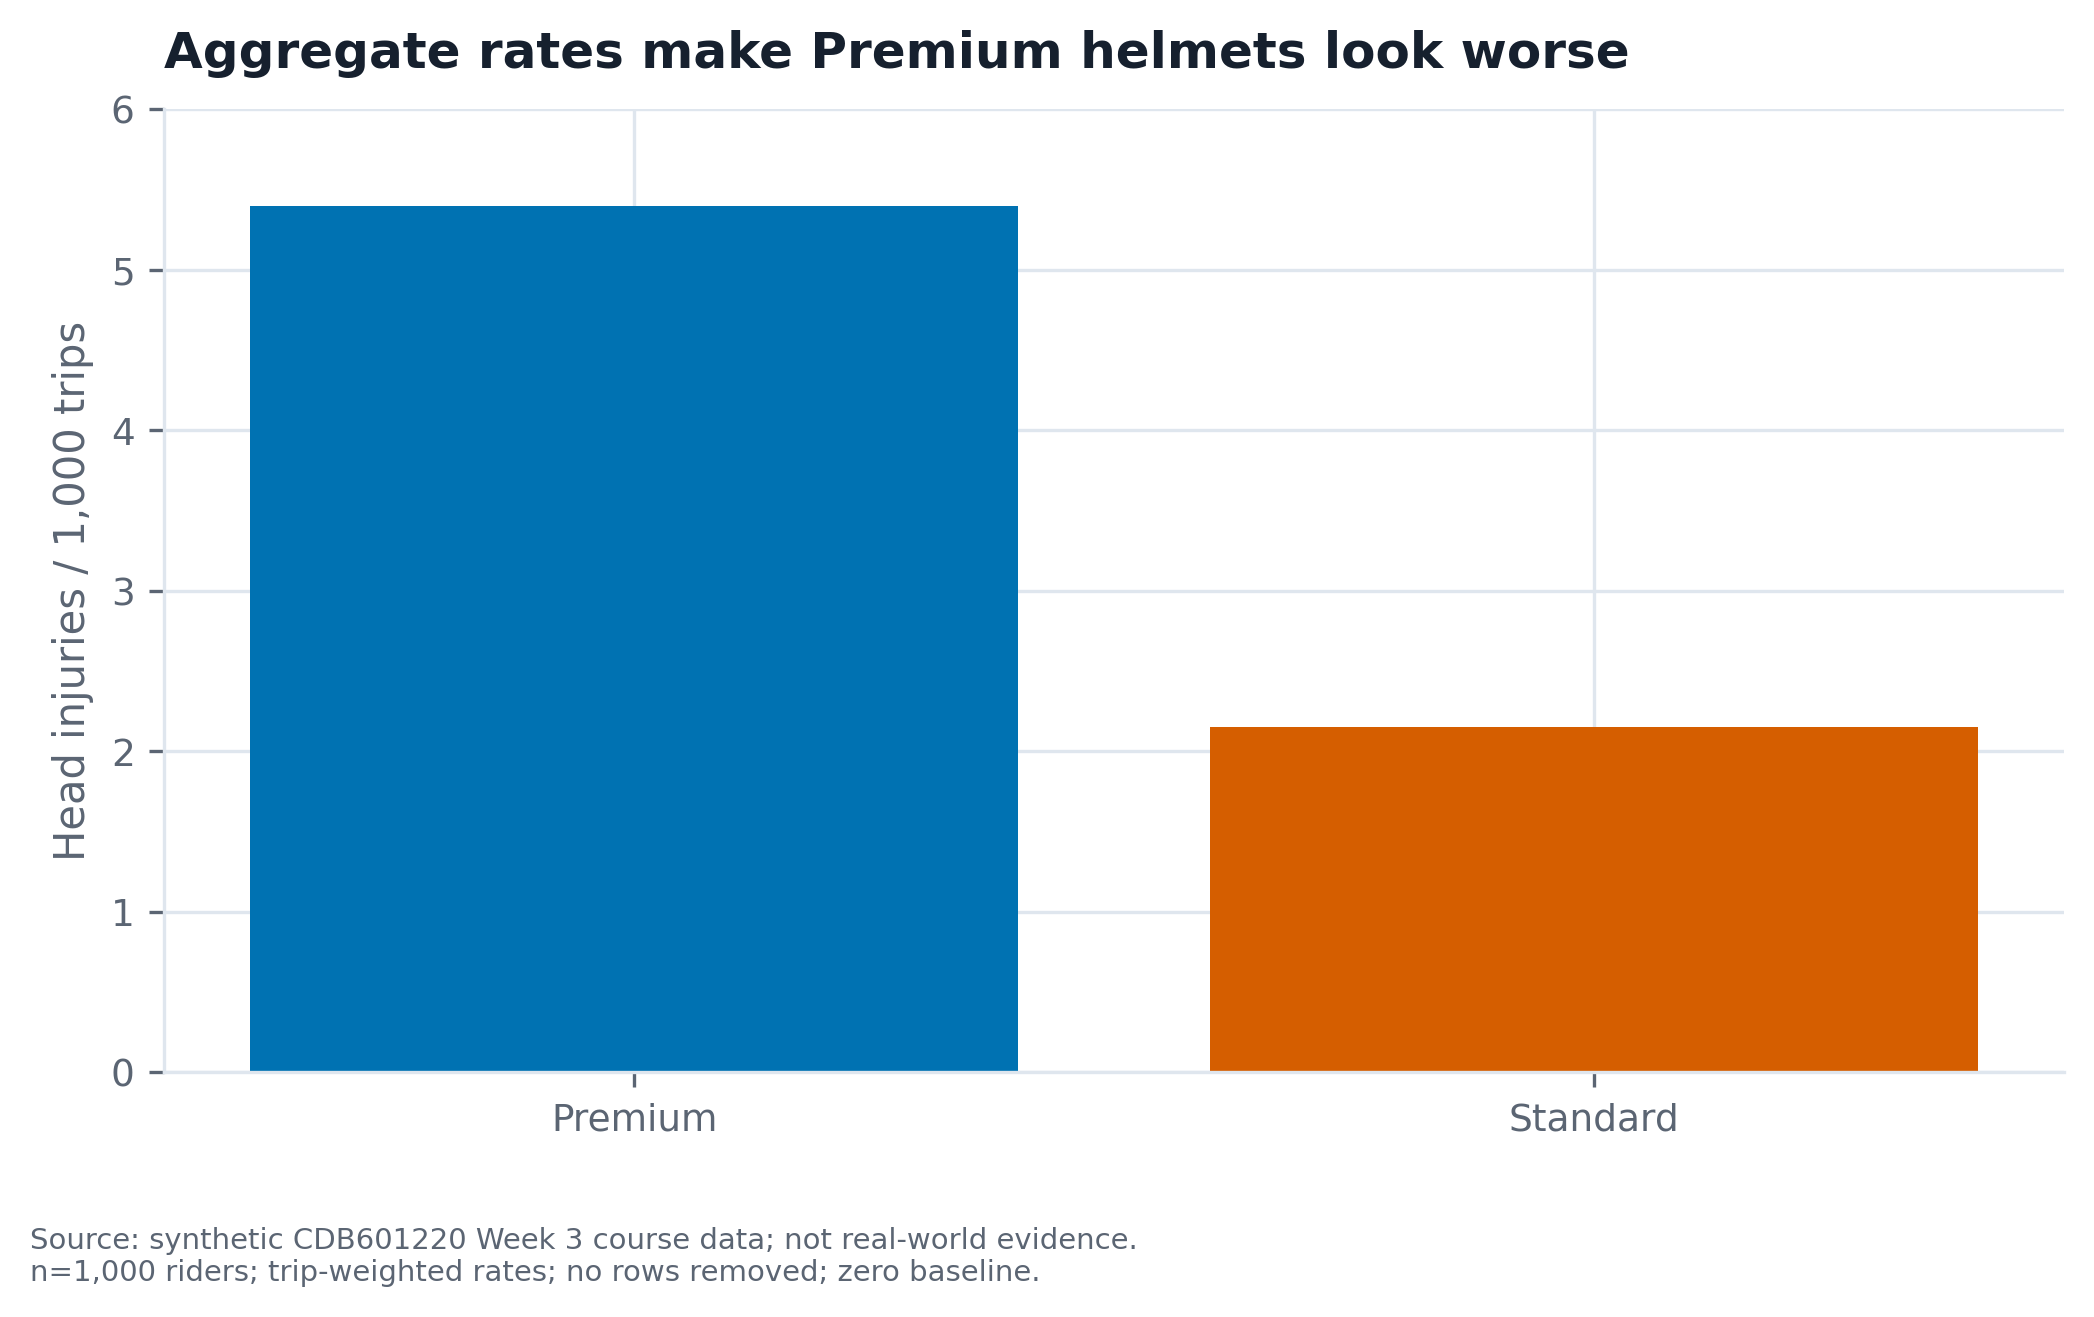

**Honest redesign**

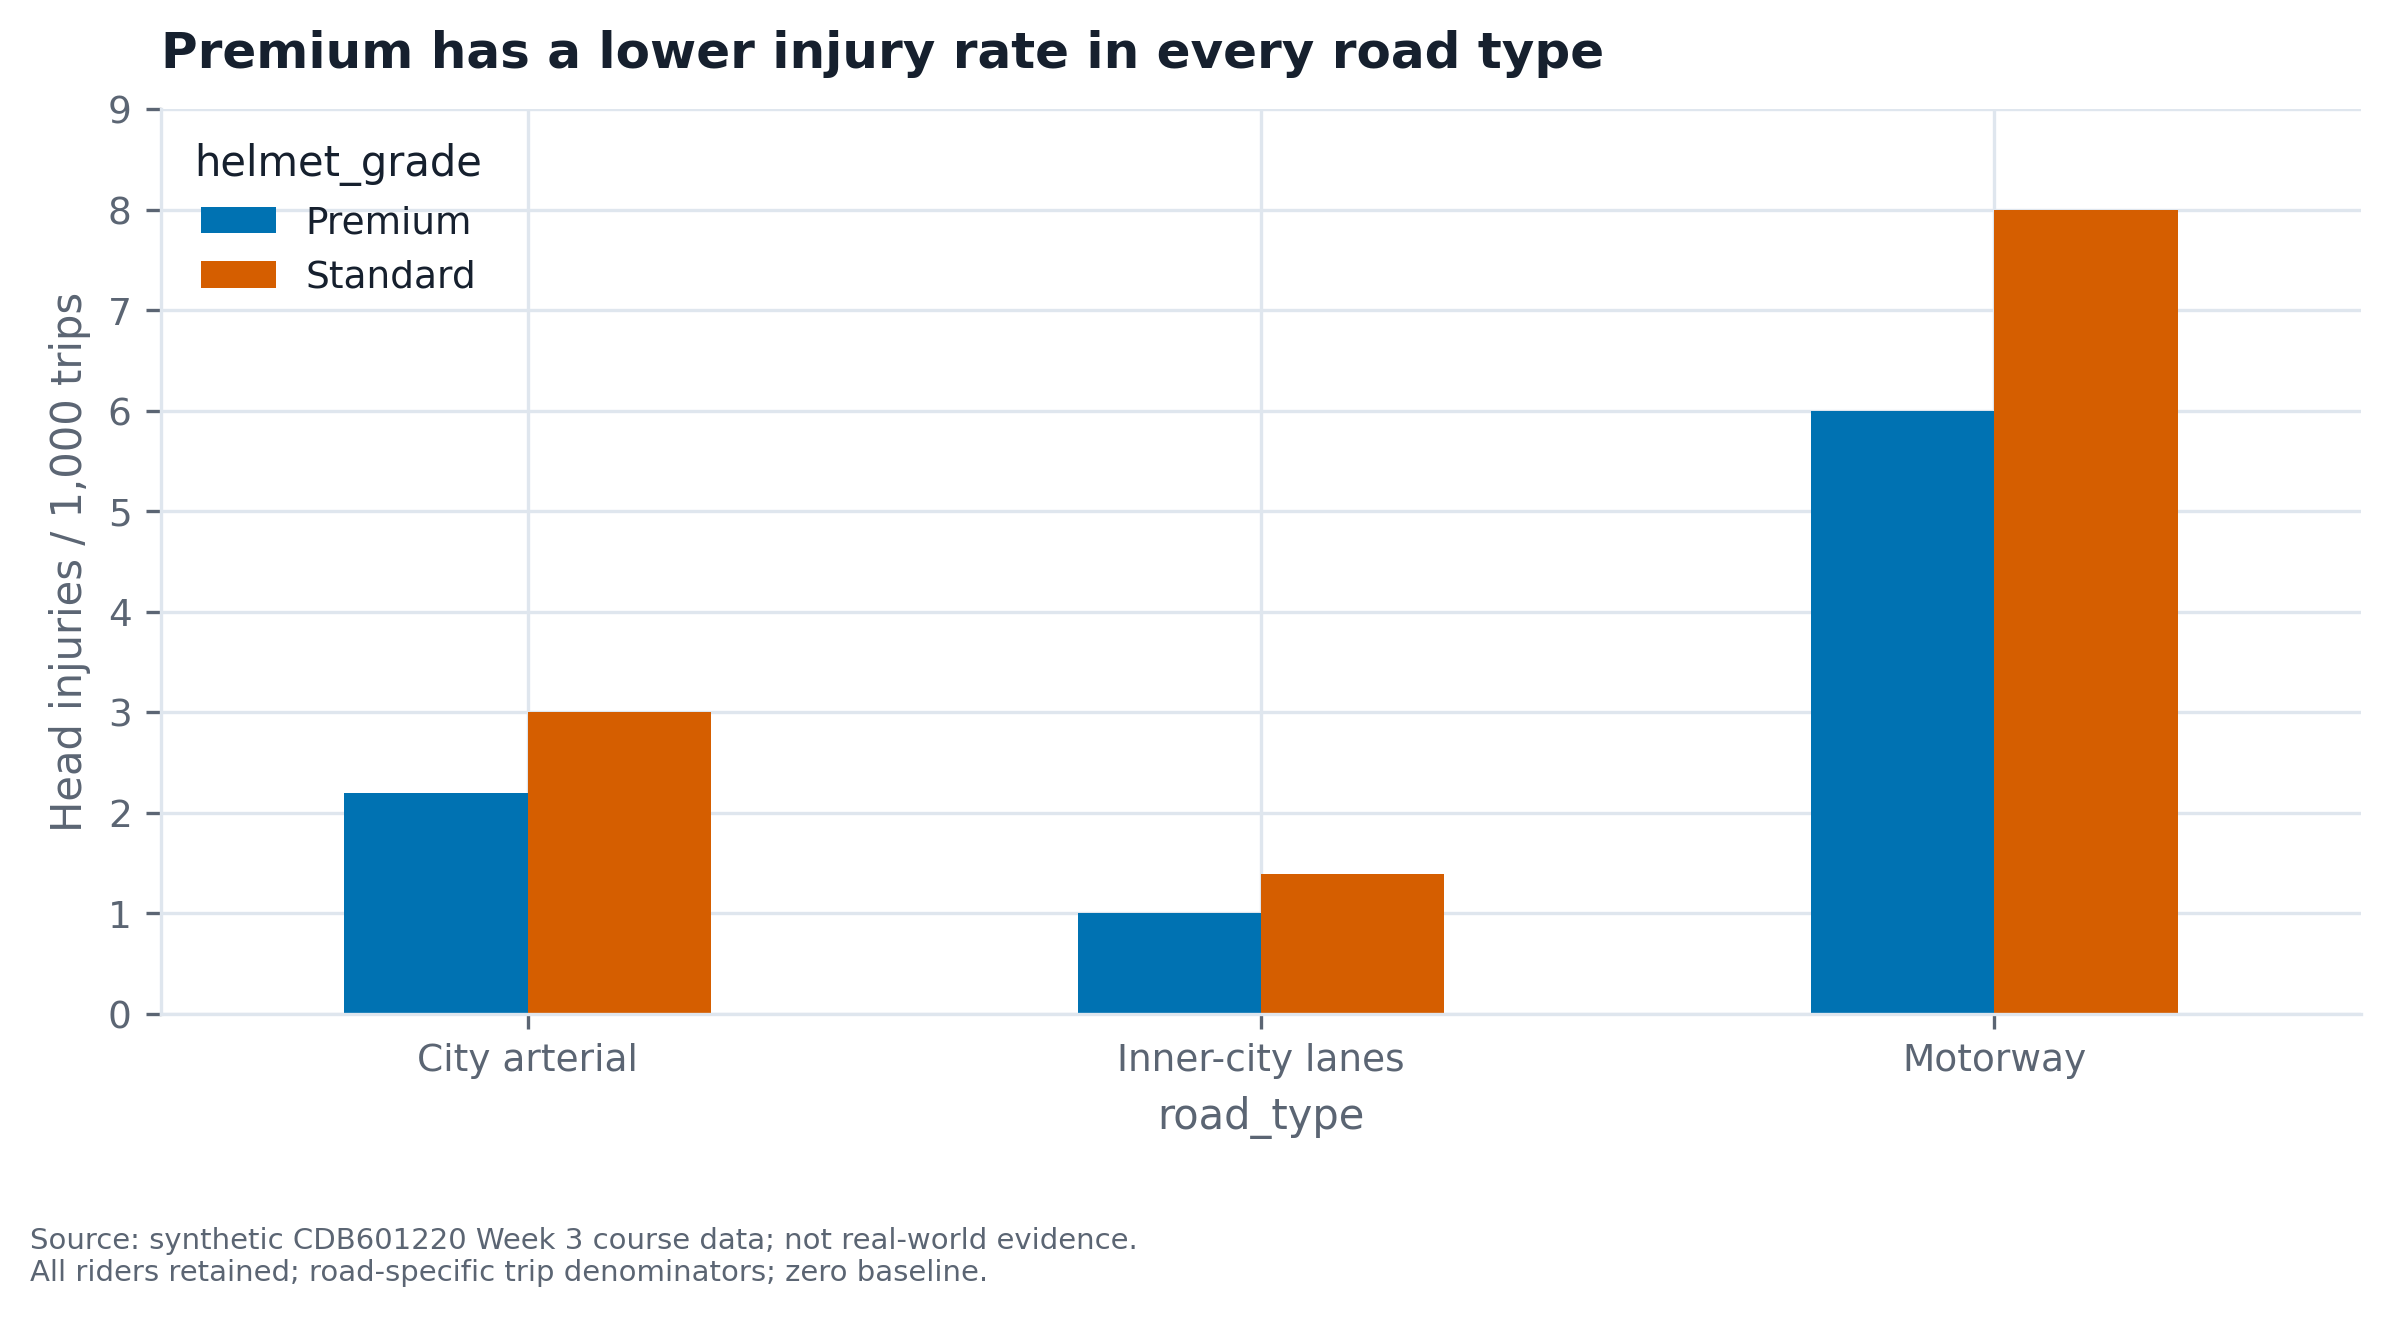

### Case 2: Counts share an enrolment denominator

**Conclusion:** The published chart suggests chai consumption predicts failure.

**Decoy:** Exam timing is a plausible first objection, but it cannot explain the dominant count trend: enrolment correlates 0.997 with cups and 0.977 with failures; exam status correlates only 0.035 with enrolment.

**Mechanism:** Population-size confounding: raw r=0.982, per-student r=0.293. Exam-month mean failure rates are 3.862% vs 3.415% in teaching months, so a residual association should not be erased or called zero.

**Redesign:** Use per-student monthly rates and separate exam months by colour and shape; these are failure events, not a proven individual causal effect.

**Required reconstruction**

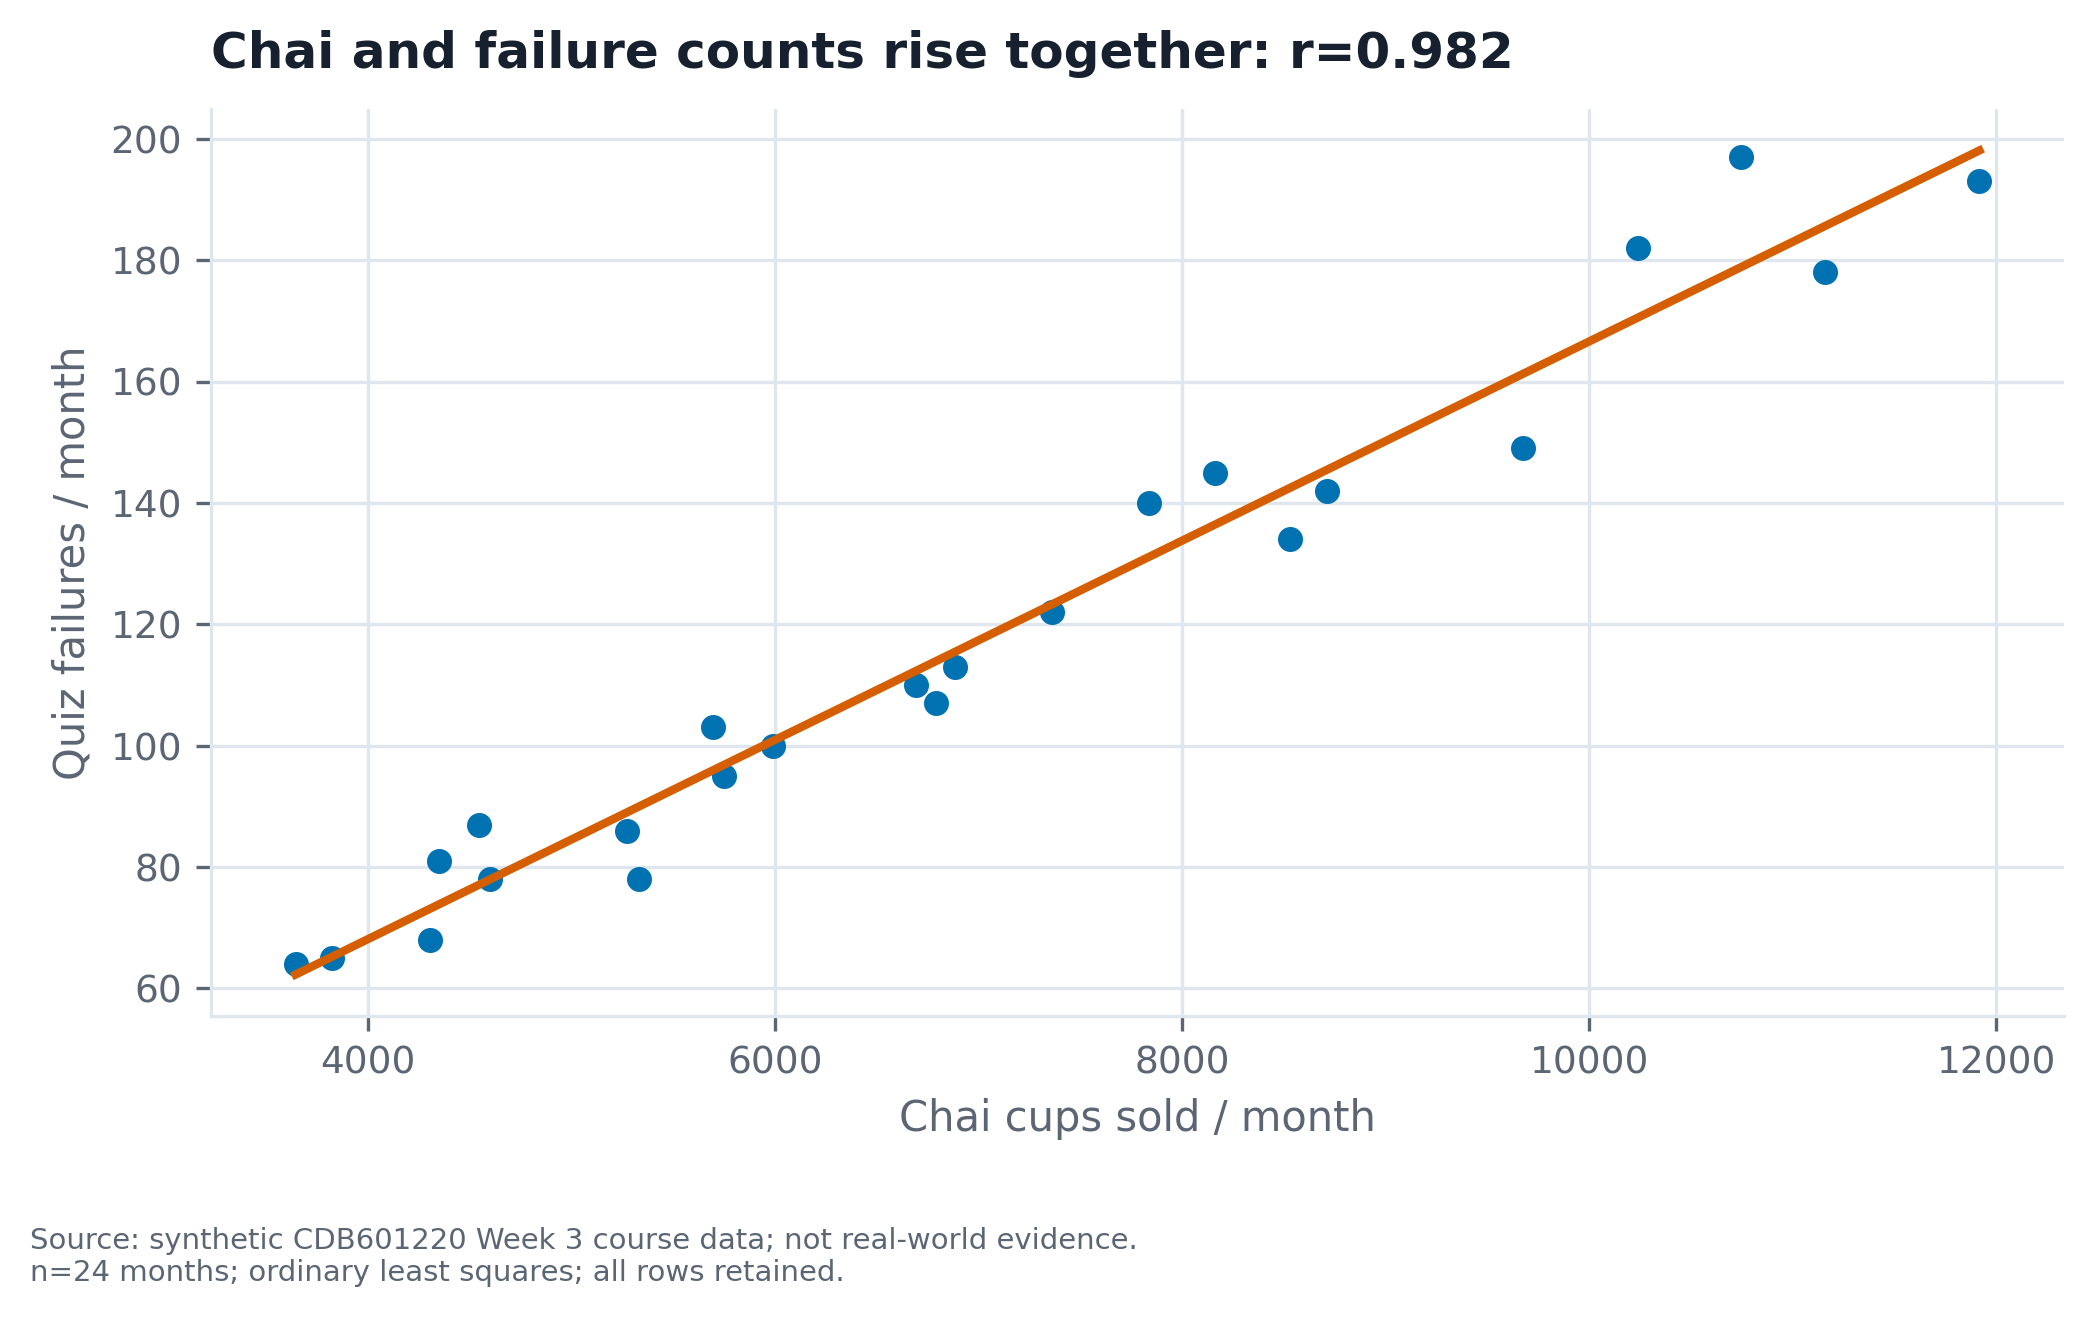

**Honest redesign**

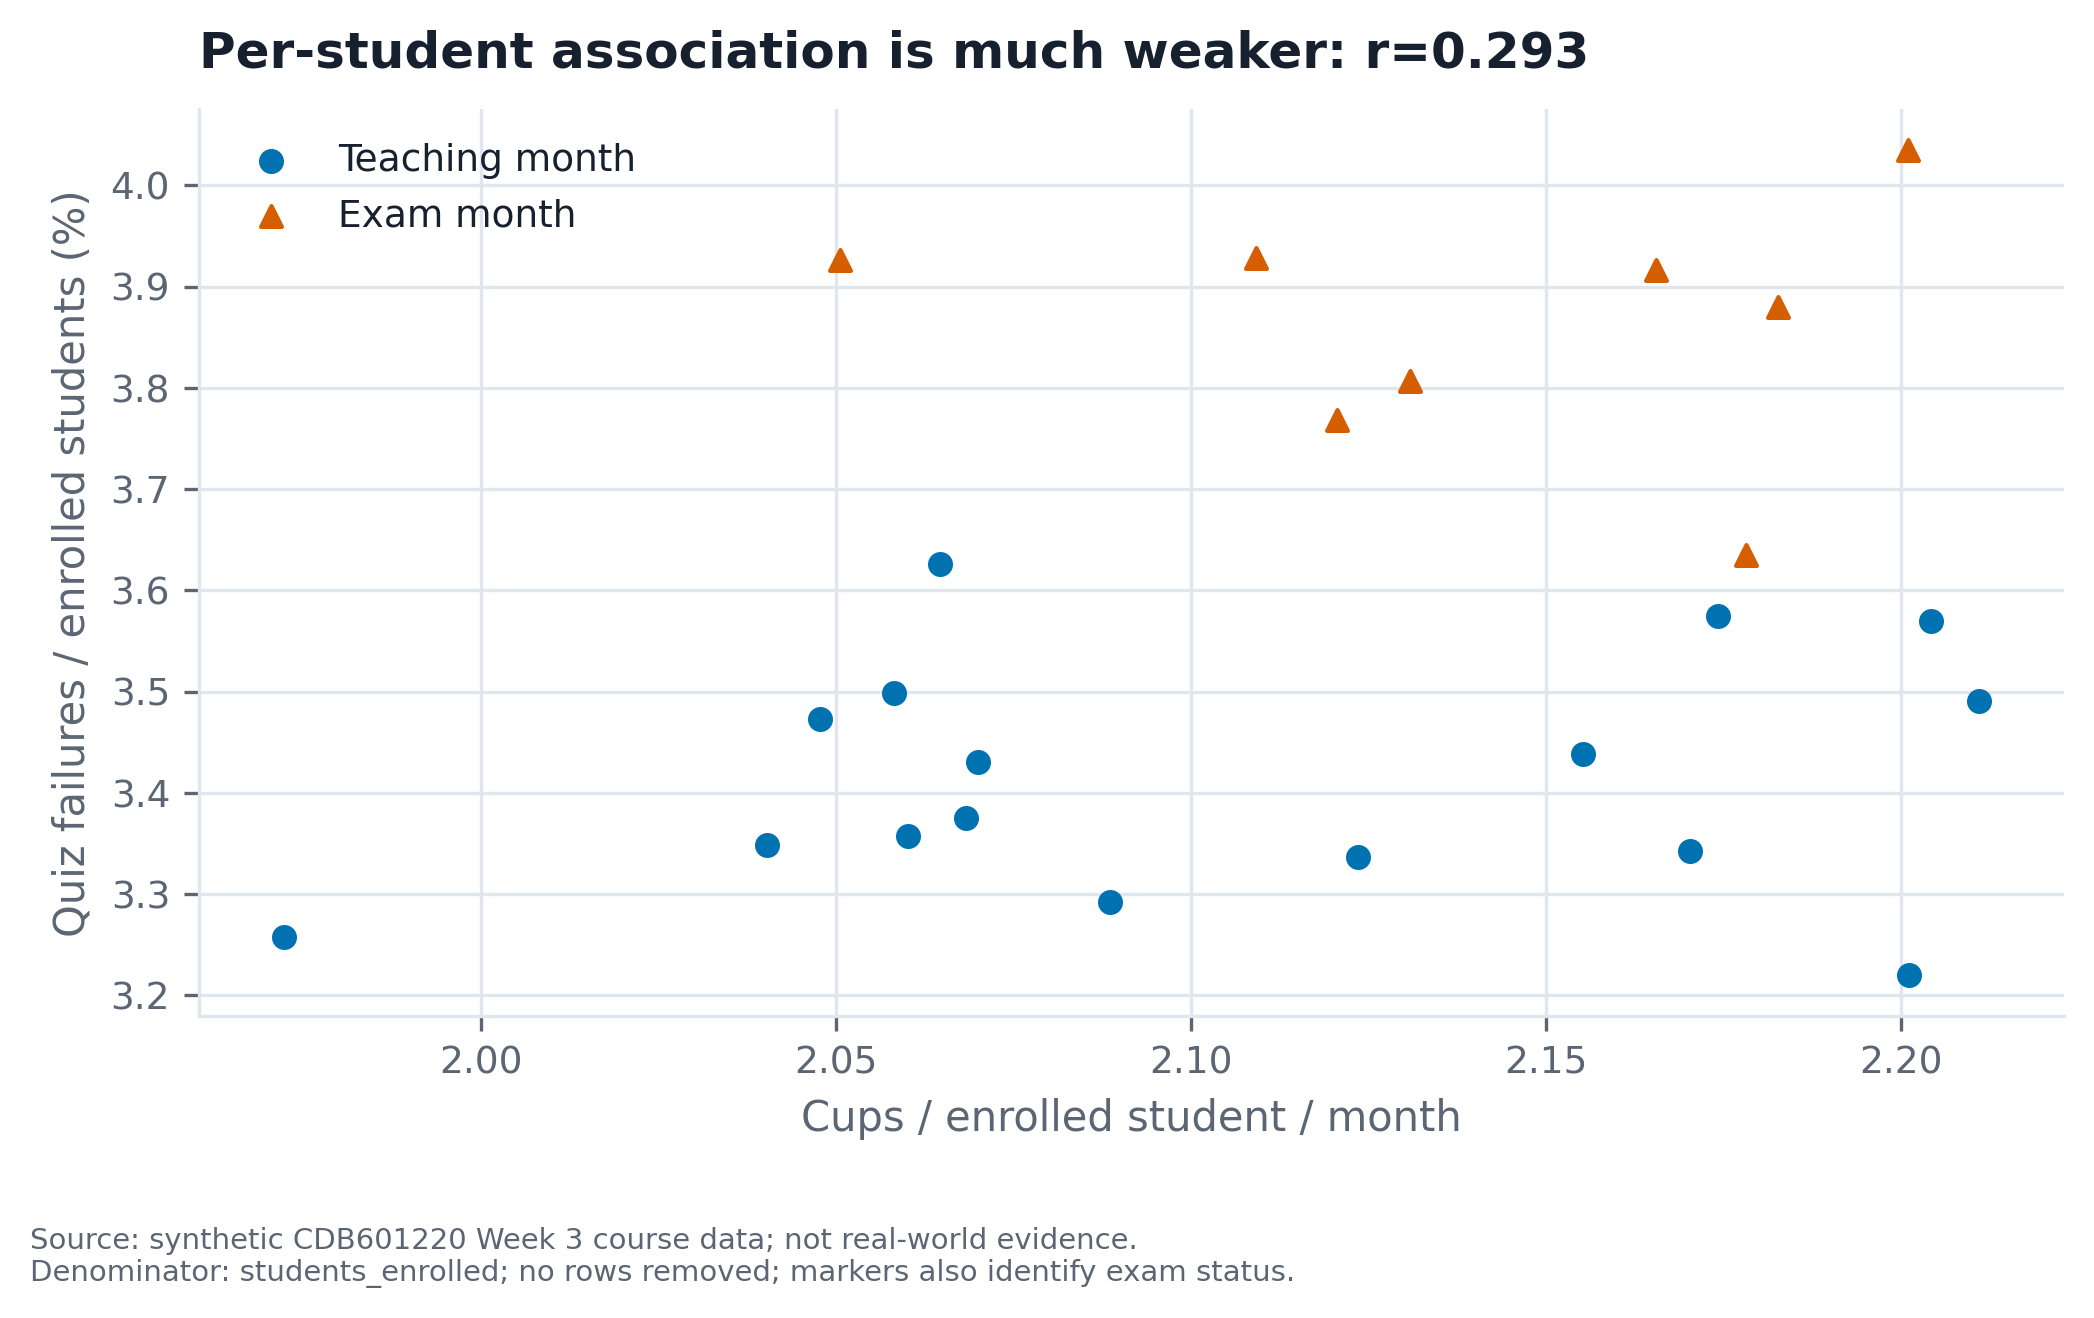

### Case 3: Missing monitors change the average

**Conclusion:** The chart invites attributing a 32% AQI improvement to the action plan.

**Decoy:** The baseline is zero, so truncation is ruled out. A citywide seasonal improvement is not supported by the continuously reporting panel.

**Mechanism:** Informative missingness / changing network composition: 6 industrial and 3 arterial stations stop reporting; 540 AQI blanks, reporting stations fall 22 to 13. Available means 202.09 to 137.21; balanced means 137.09 to 137.21, change +0.08%.

**Redesign:** Show raw and fixed-station trends together; do not fill missing high-pollution stations with zeros or assert full-city improvement.

**Required reconstruction**

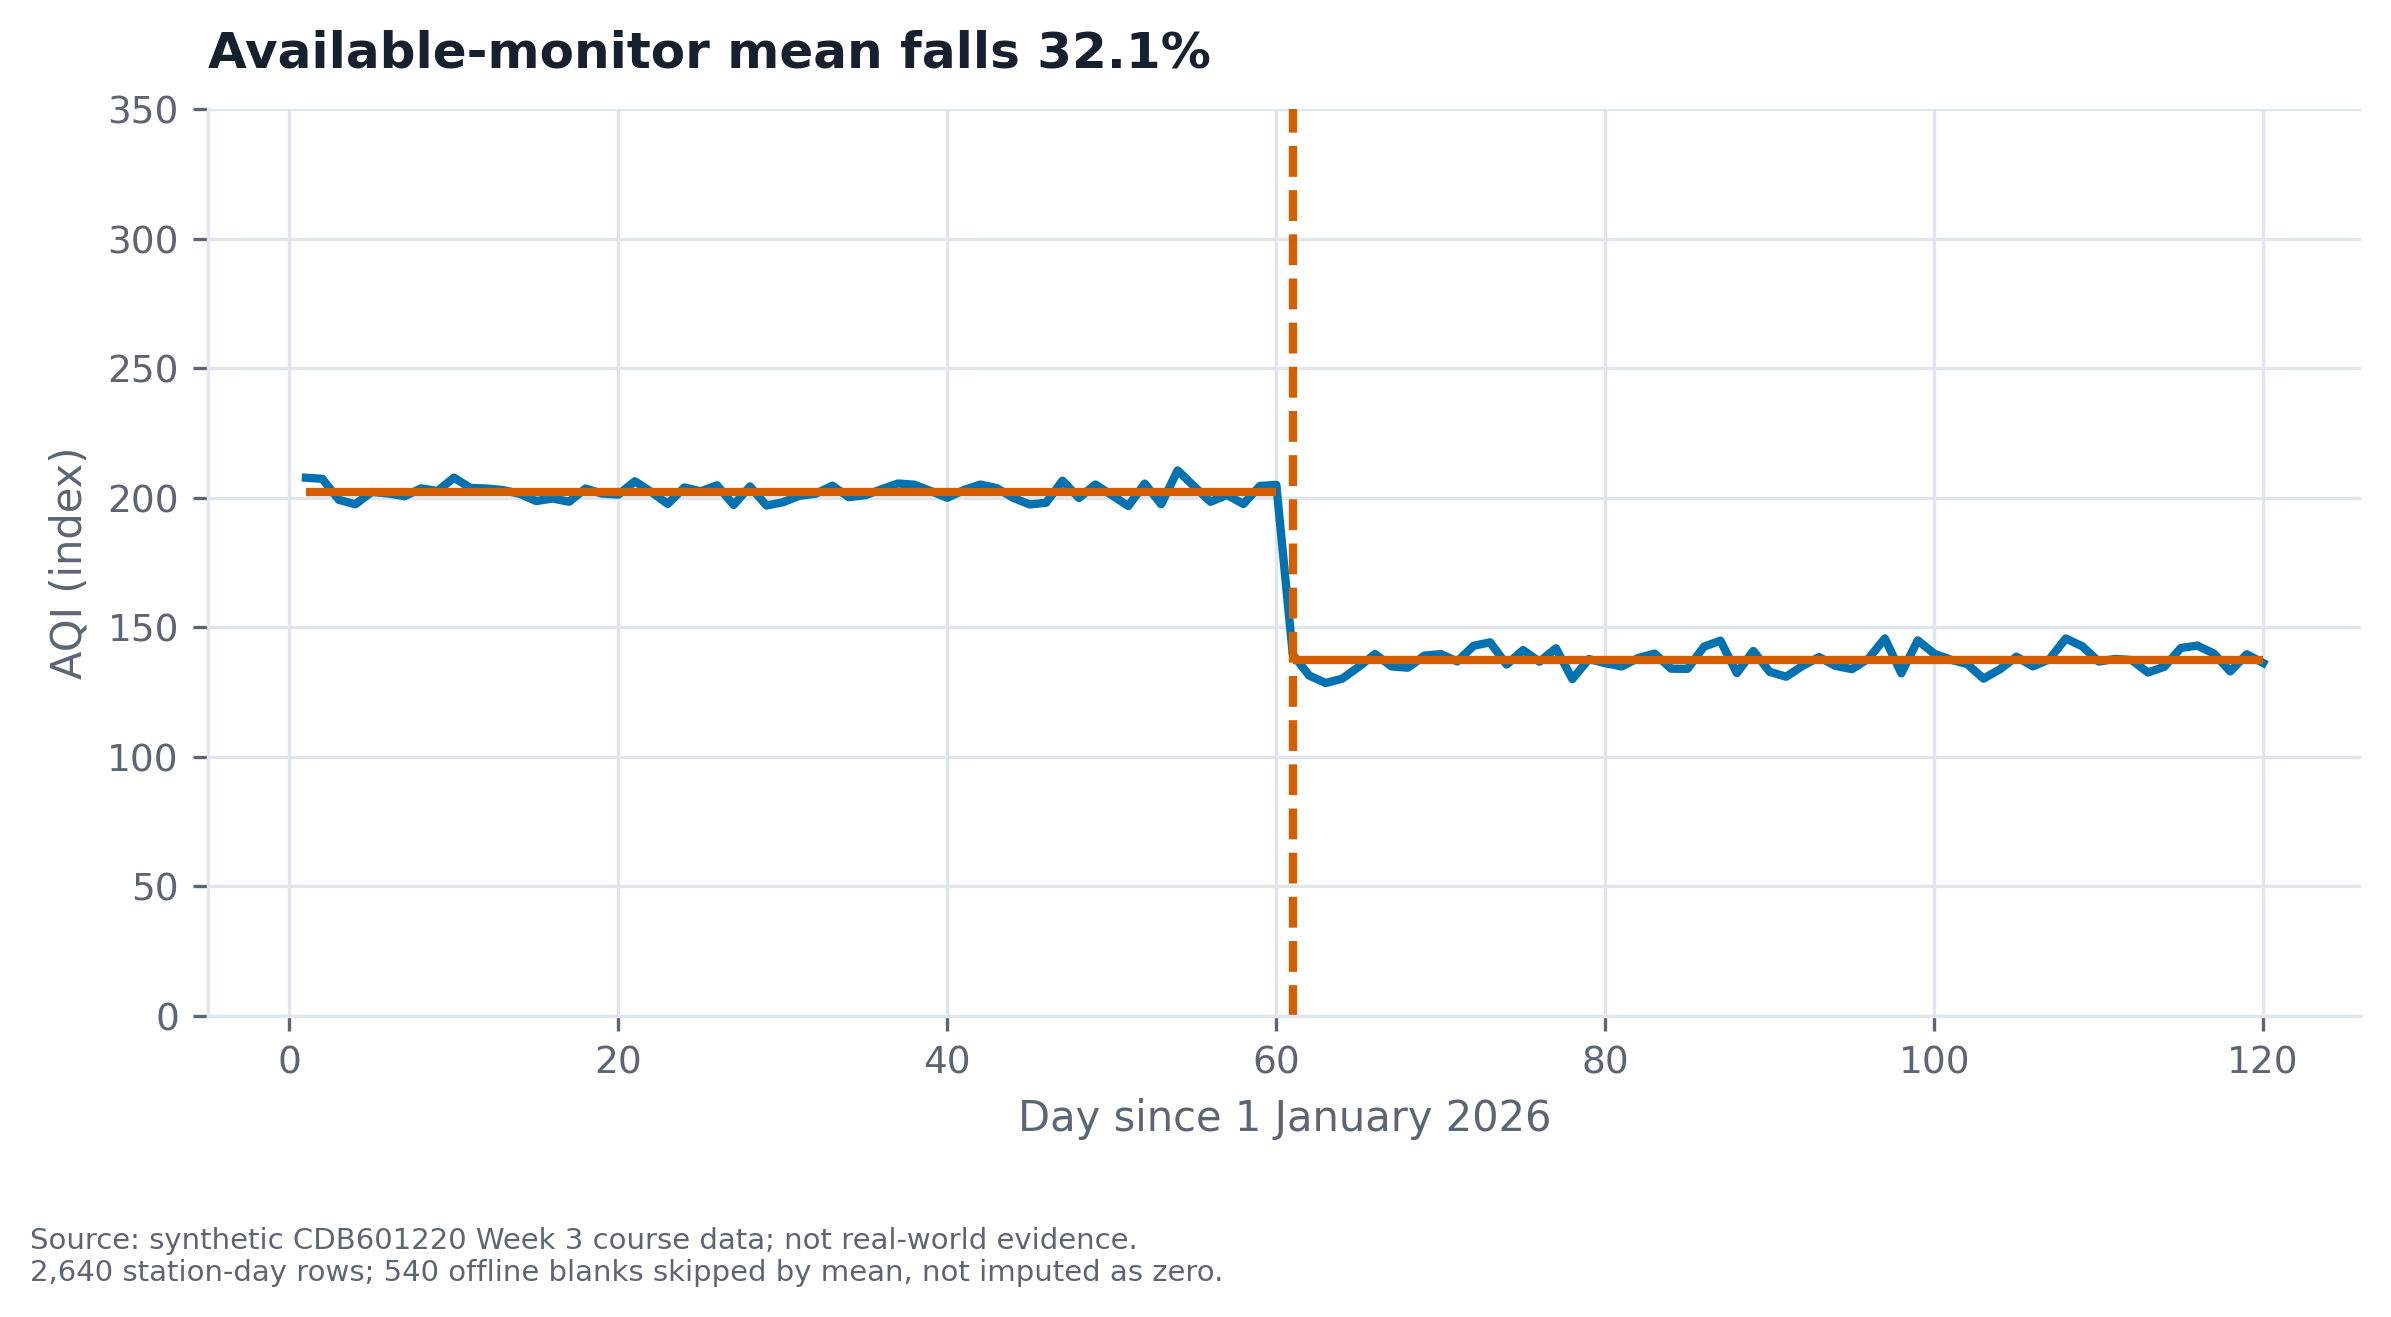

**Honest redesign**

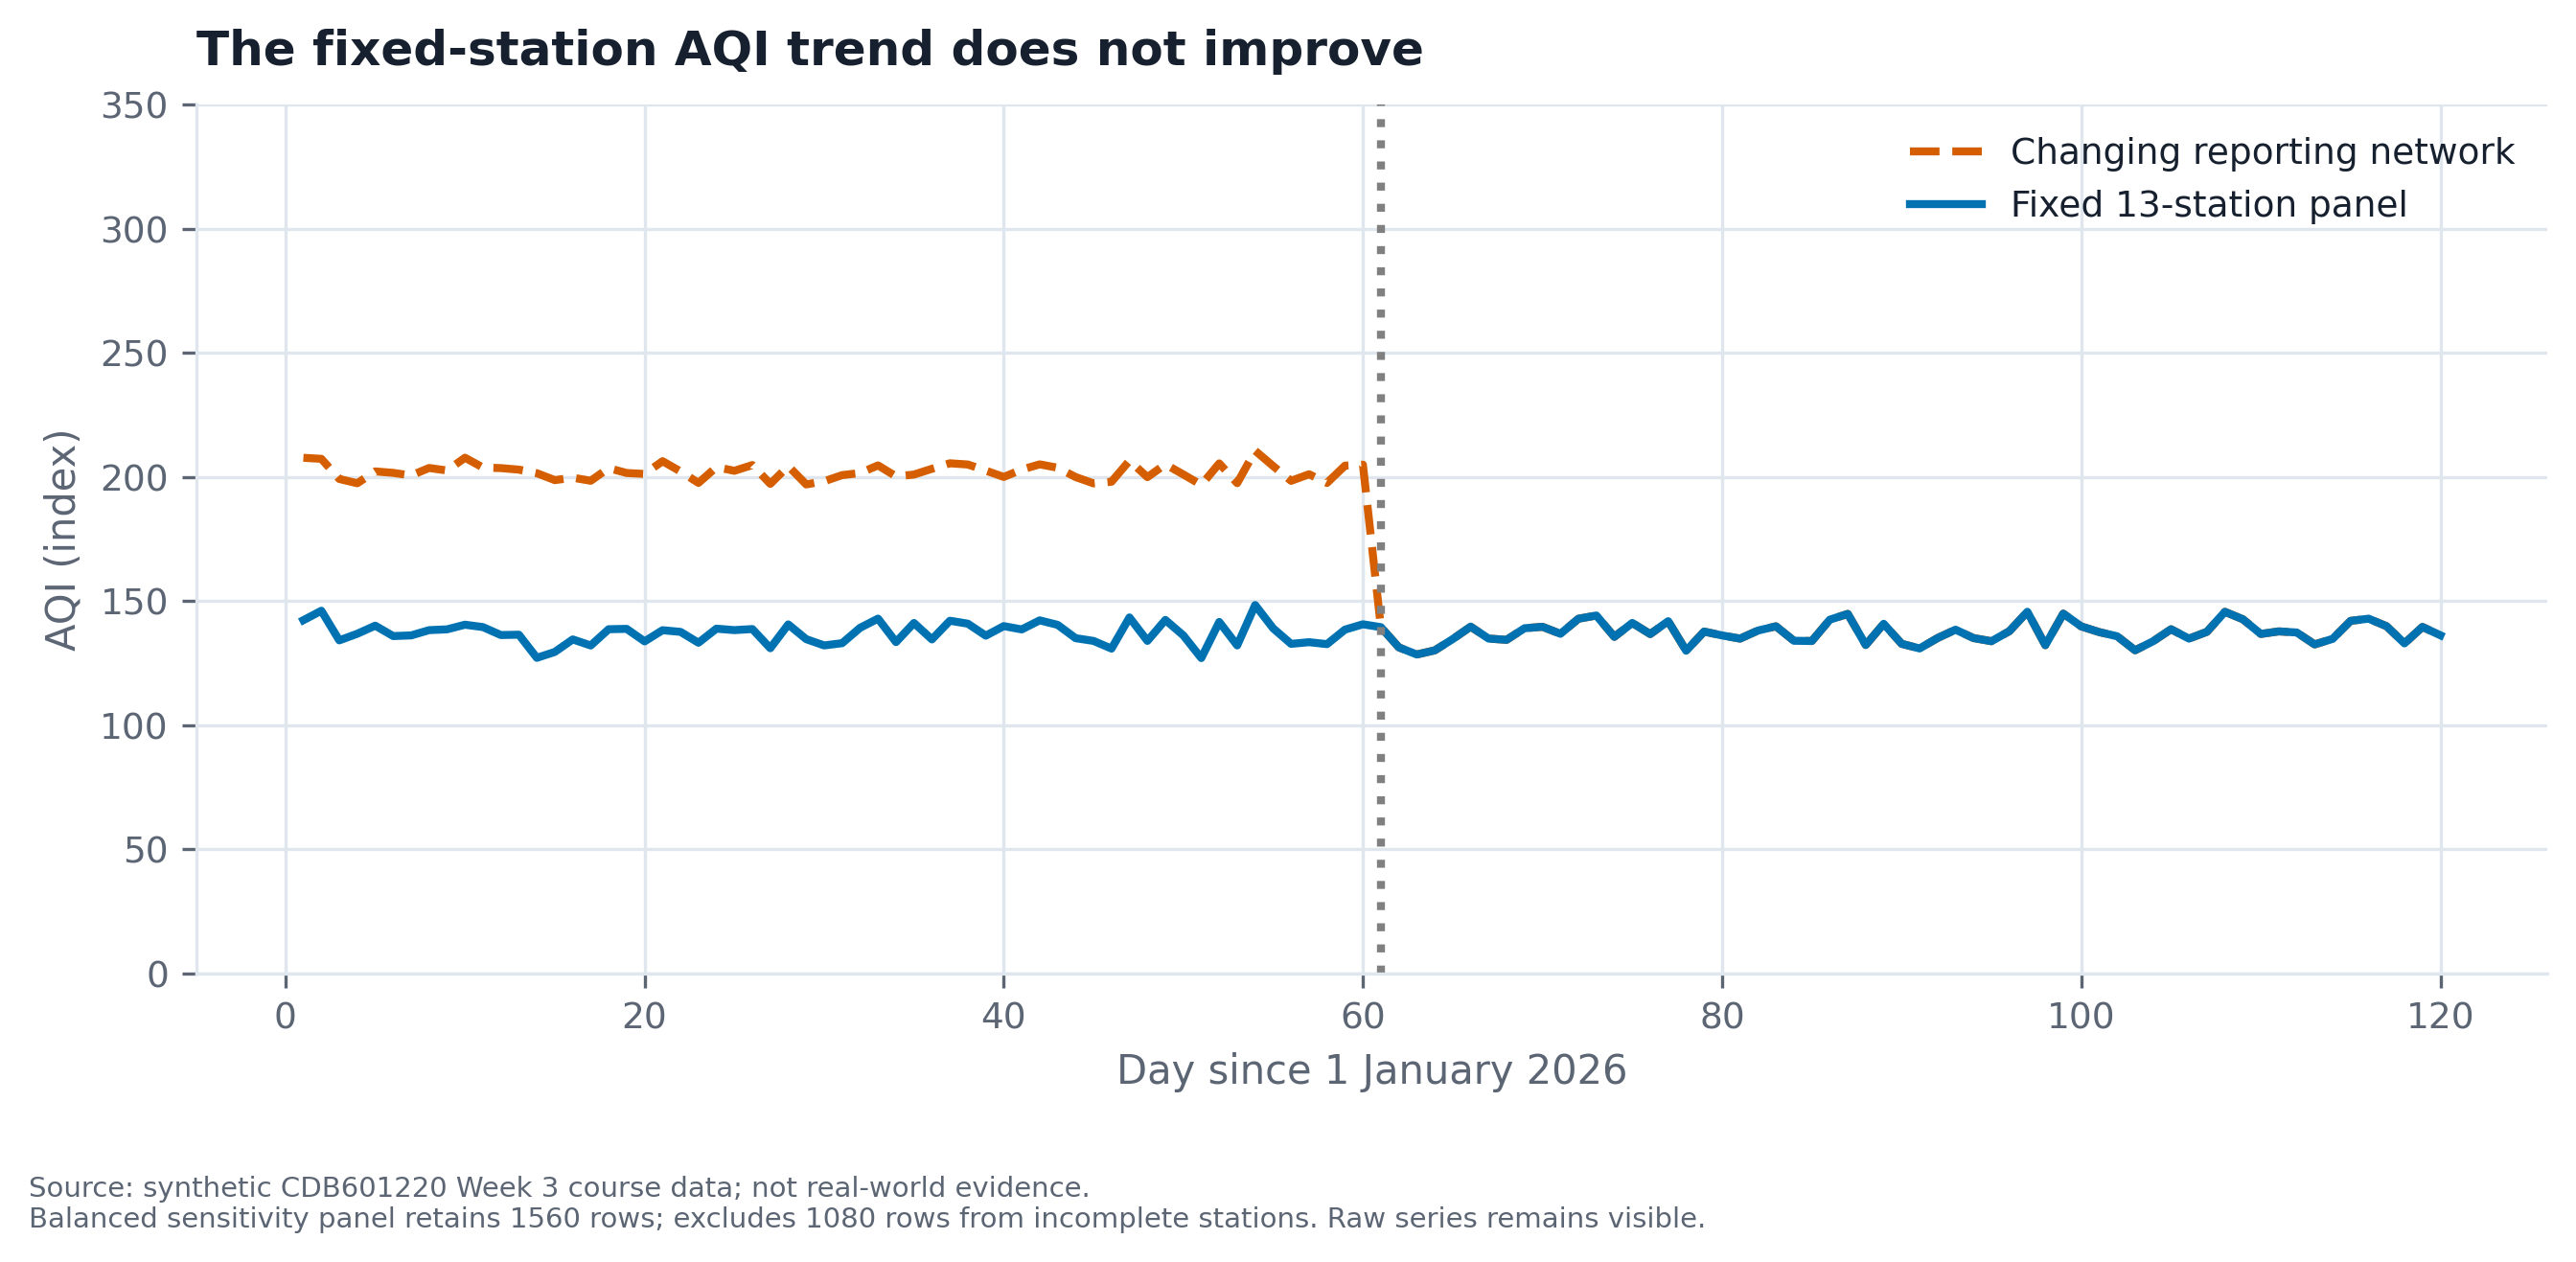

### Case 4: Equal statistics conceal the quartet

**Conclusion:** Equal summaries invite equal funding and identical department models.

**Decoy:** Small n alone is not the explanation: all departments have the same n=11, means approximately 18/14.5 and r approximately .816, yet very different geometry.

**Mechanism:** Insufficient summaries: one department is roughly linear, one curved, one driven by a score outlier, and Architecture has only two distinct x values (10 at one x, one high-leverage point). Removing that x-extreme leaves constant x, so Pearson r is undefined, not evidence of a stable slope.

**Redesign:** Plot all four departments on common axes; show fitted lines to reveal where identical fits misrepresent the observations.

**Required reconstruction**

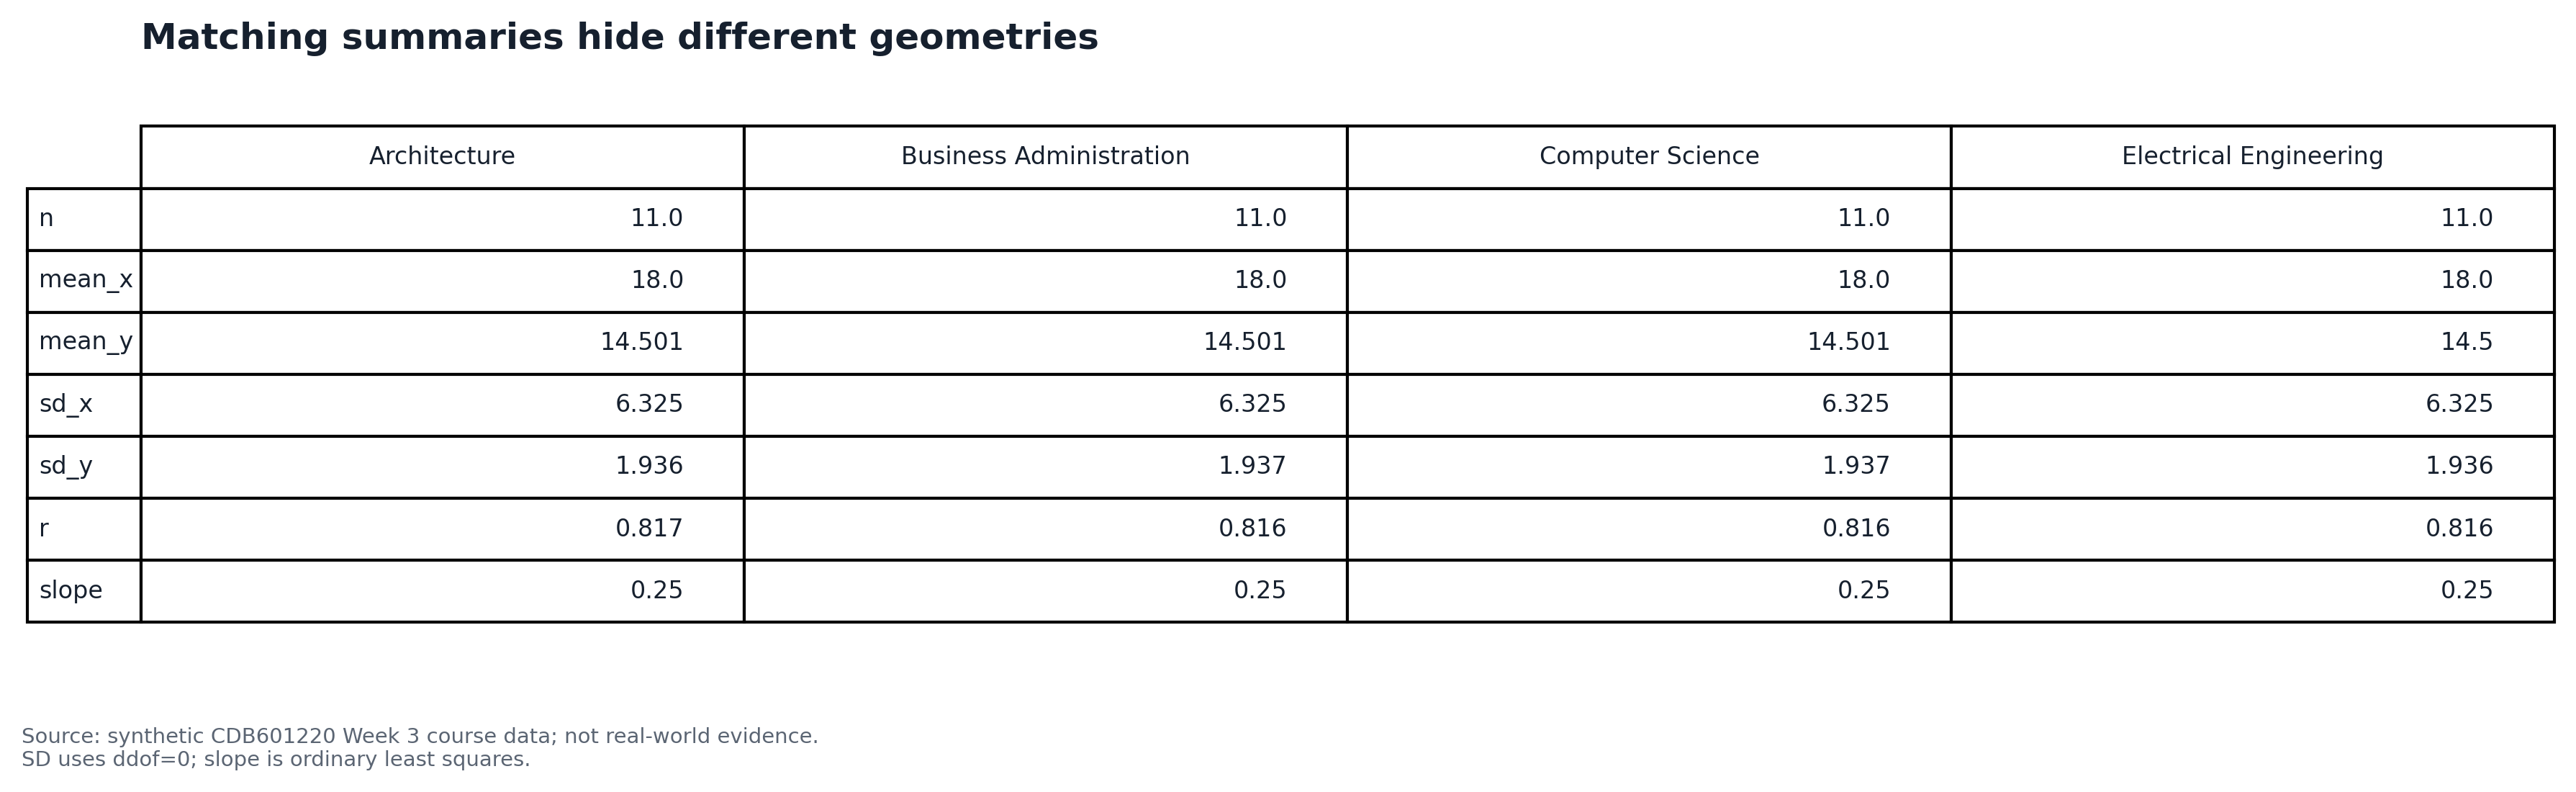

**Honest redesign**

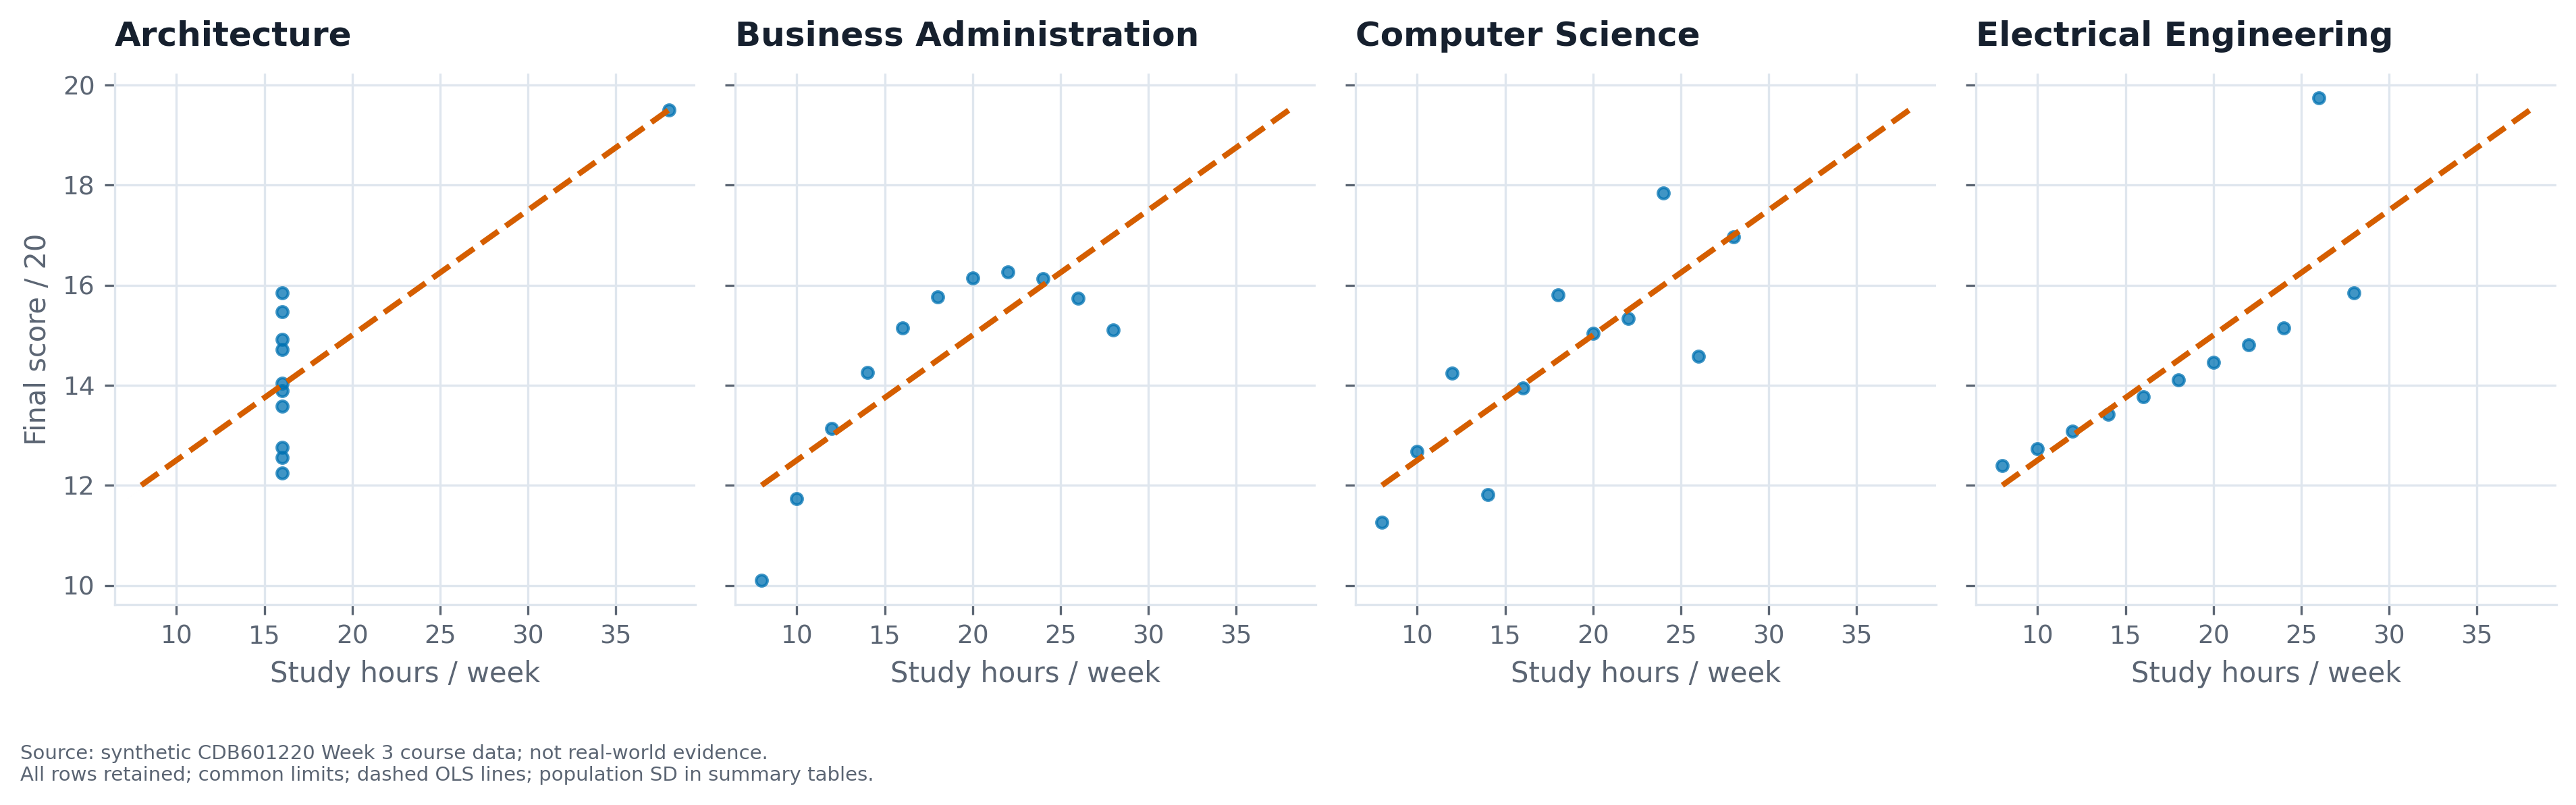

### Case 5: Moment matching preserves different shapes

**Conclusion:** Equal means, SDs and correlations invite treating five cohorts as interchangeable.

**Decoy:** Not a small-sample artifact: each cohort has n=180 and deliberately matched moments. Population rather than sample SD is the convention behind the 12/15 self-check.

**Mechanism:** Non-identifiability from first/second moments: all five groups have mean 48/63, SD 12/15 and r=.420 to rounding, while scatter geometry differs. Covariance is about 75.6 and slope .525 for all; neither constrains clusters, curves or gaps.

**Redesign:** Common-scale scatter small multiples expose the shapes without changing any row. Cohort names label the designed shapes, not automatically their final geometry after moment matching.

**Required reconstruction**

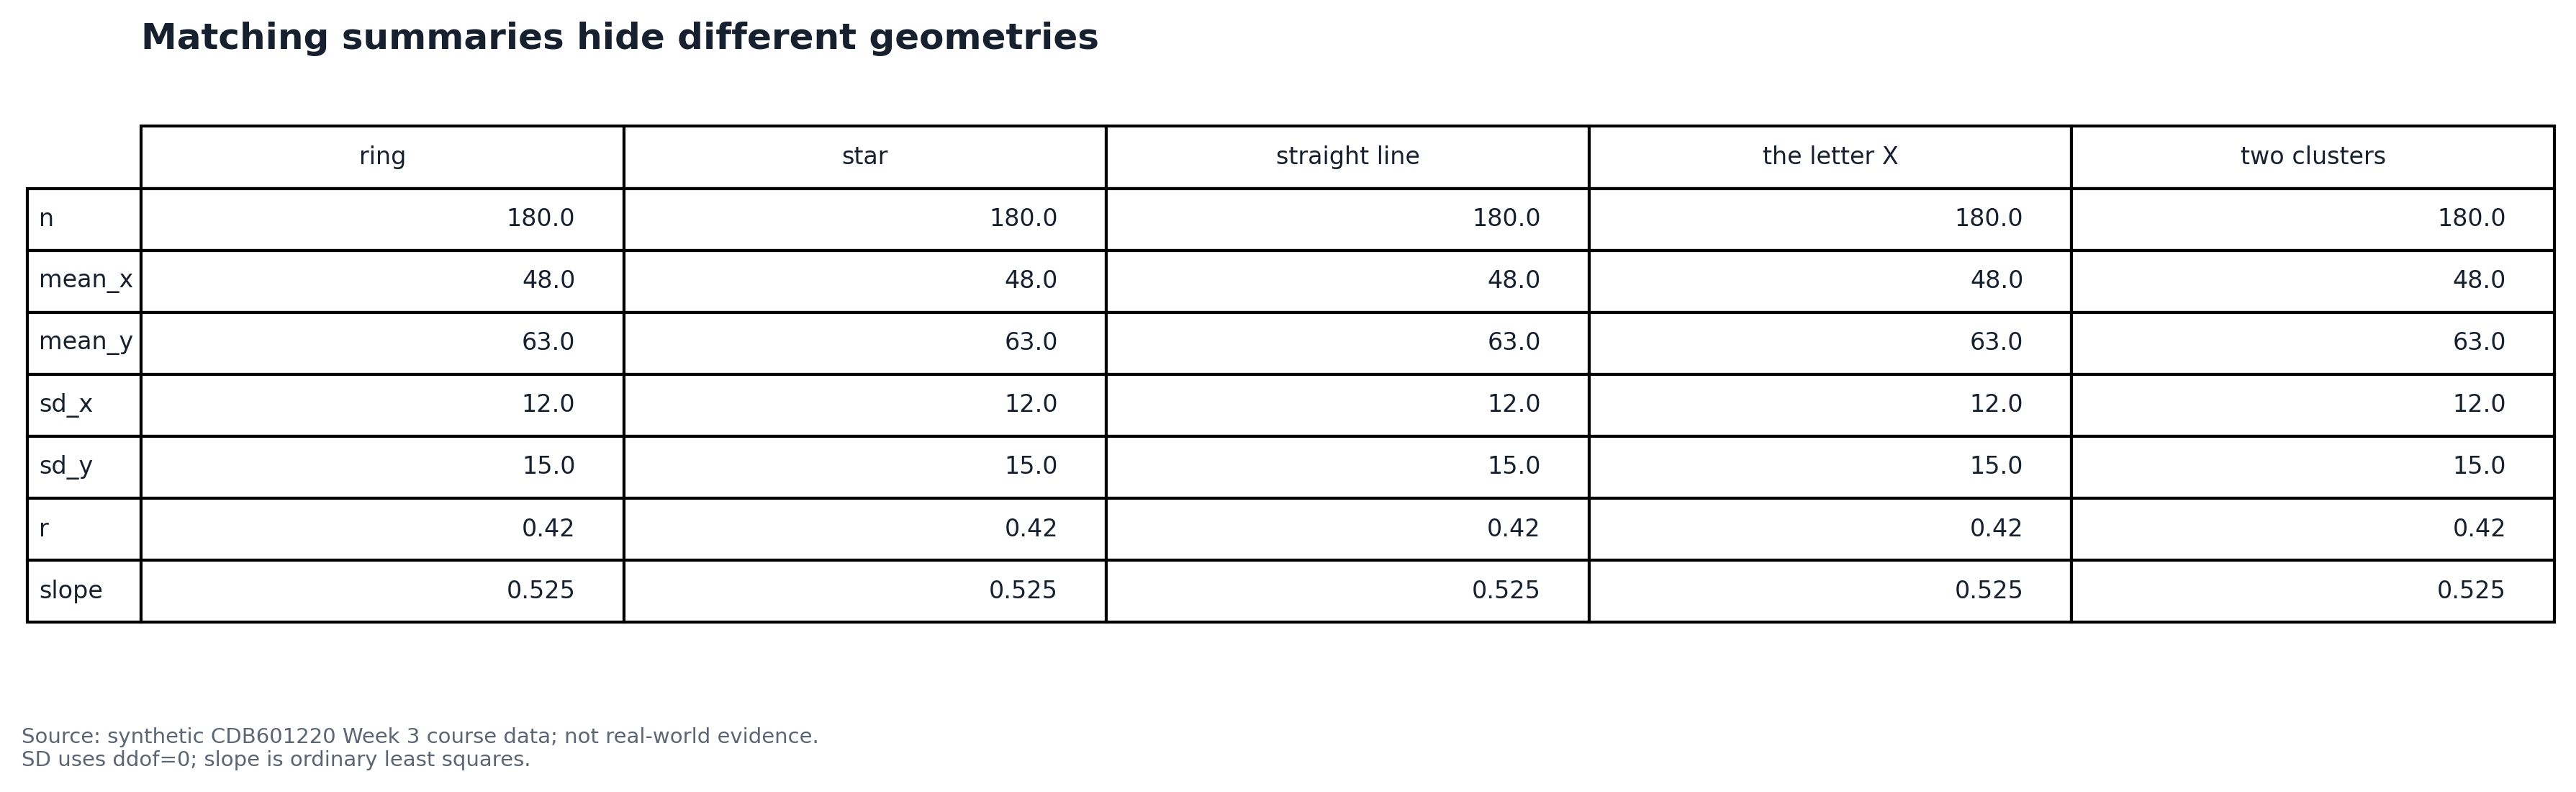

**Honest redesign**

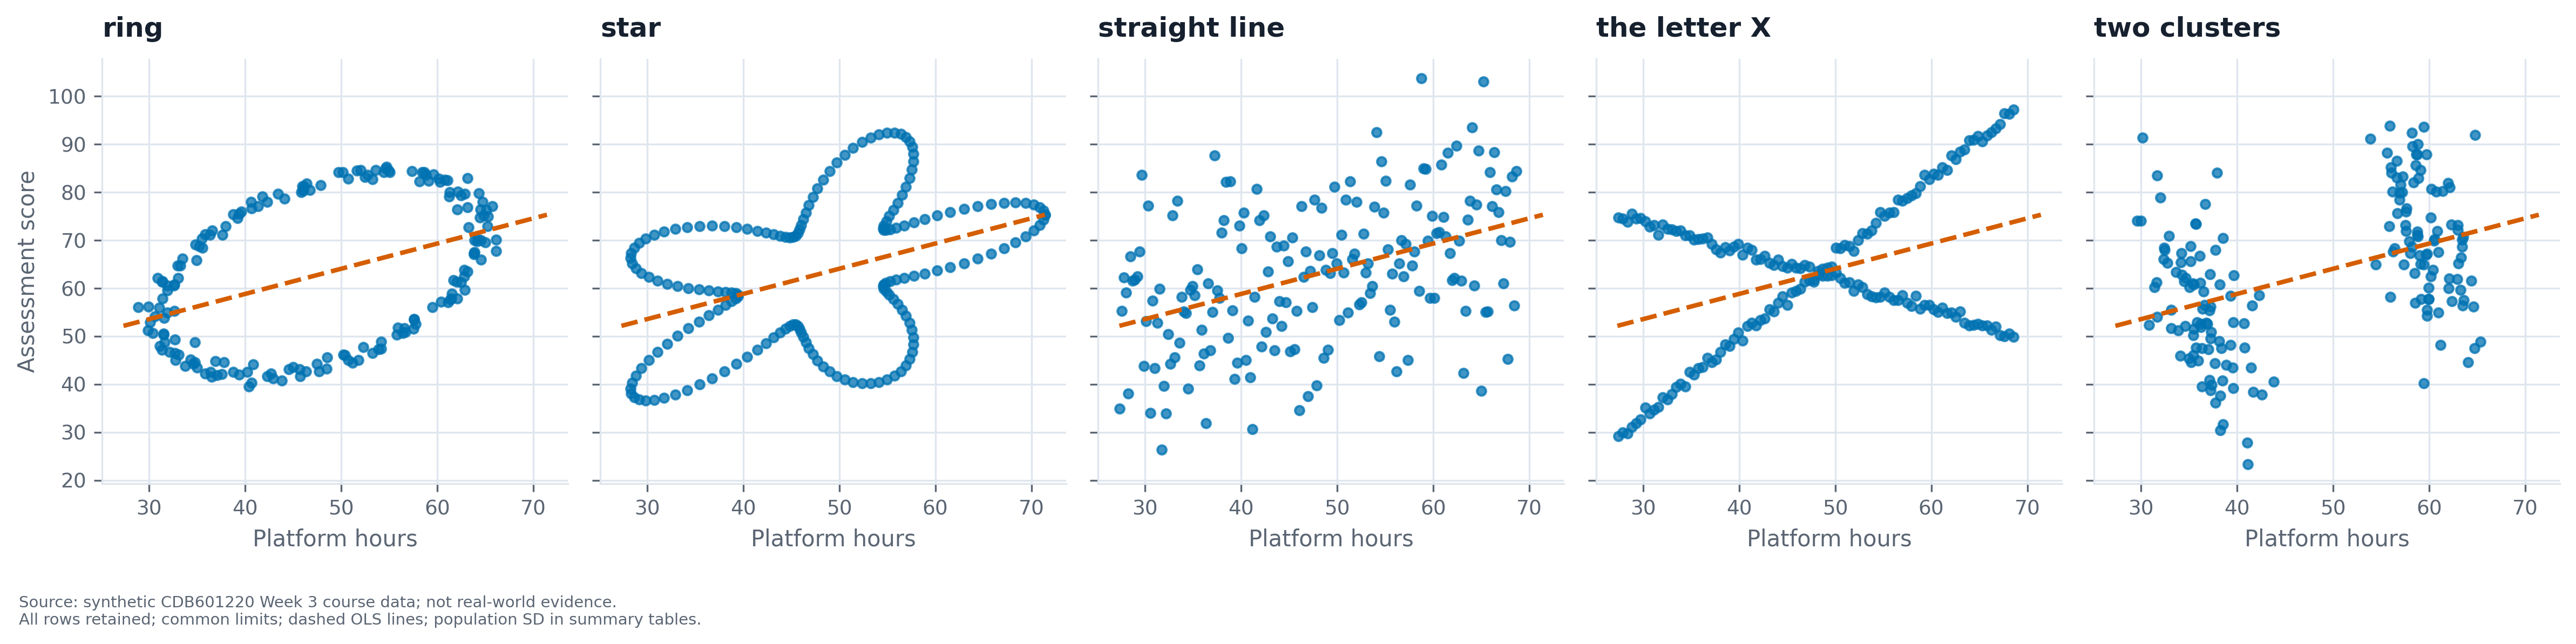

### Case 6: An influential point and redundant channels

**Conclusion:** The heatmap invites a new physiological link between creatinine and HbA1c.

**Decoy:** The positive association is not mainly site confounding: the row at index 0 drives it even within Site C. An extreme value is not automatically erroneous and is retained in the primary analysis.

**Mechanism:** Outlier influence: r=0.765, versus -0.0036 without the 1050/15.8 observation. Other strong pairs include arithmetic/redundant channels (systolic-MAP .962). Resting-HR/VO2max has pooled r=.772 but within-device r={'DX-100': -0.41, 'DX-200': -0.404, 'DX-300': -0.495, 'DX-400': -0.631}, showing device/site mixing; probes have no calibrated interpretation. With 20 variables there are 190 distinct pairwise tests, requiring exploratory caution.

**Redesign:** A signed -1..1 diverging lower-triangle matrix repairs sign/scale/duplication. It cannot repair leverage, confounding or multiplicity: add raw and leave-one-out scatter, with exclusions explicit; omit uncalibrated and redundant channels from interpretation.

**Required reconstruction**

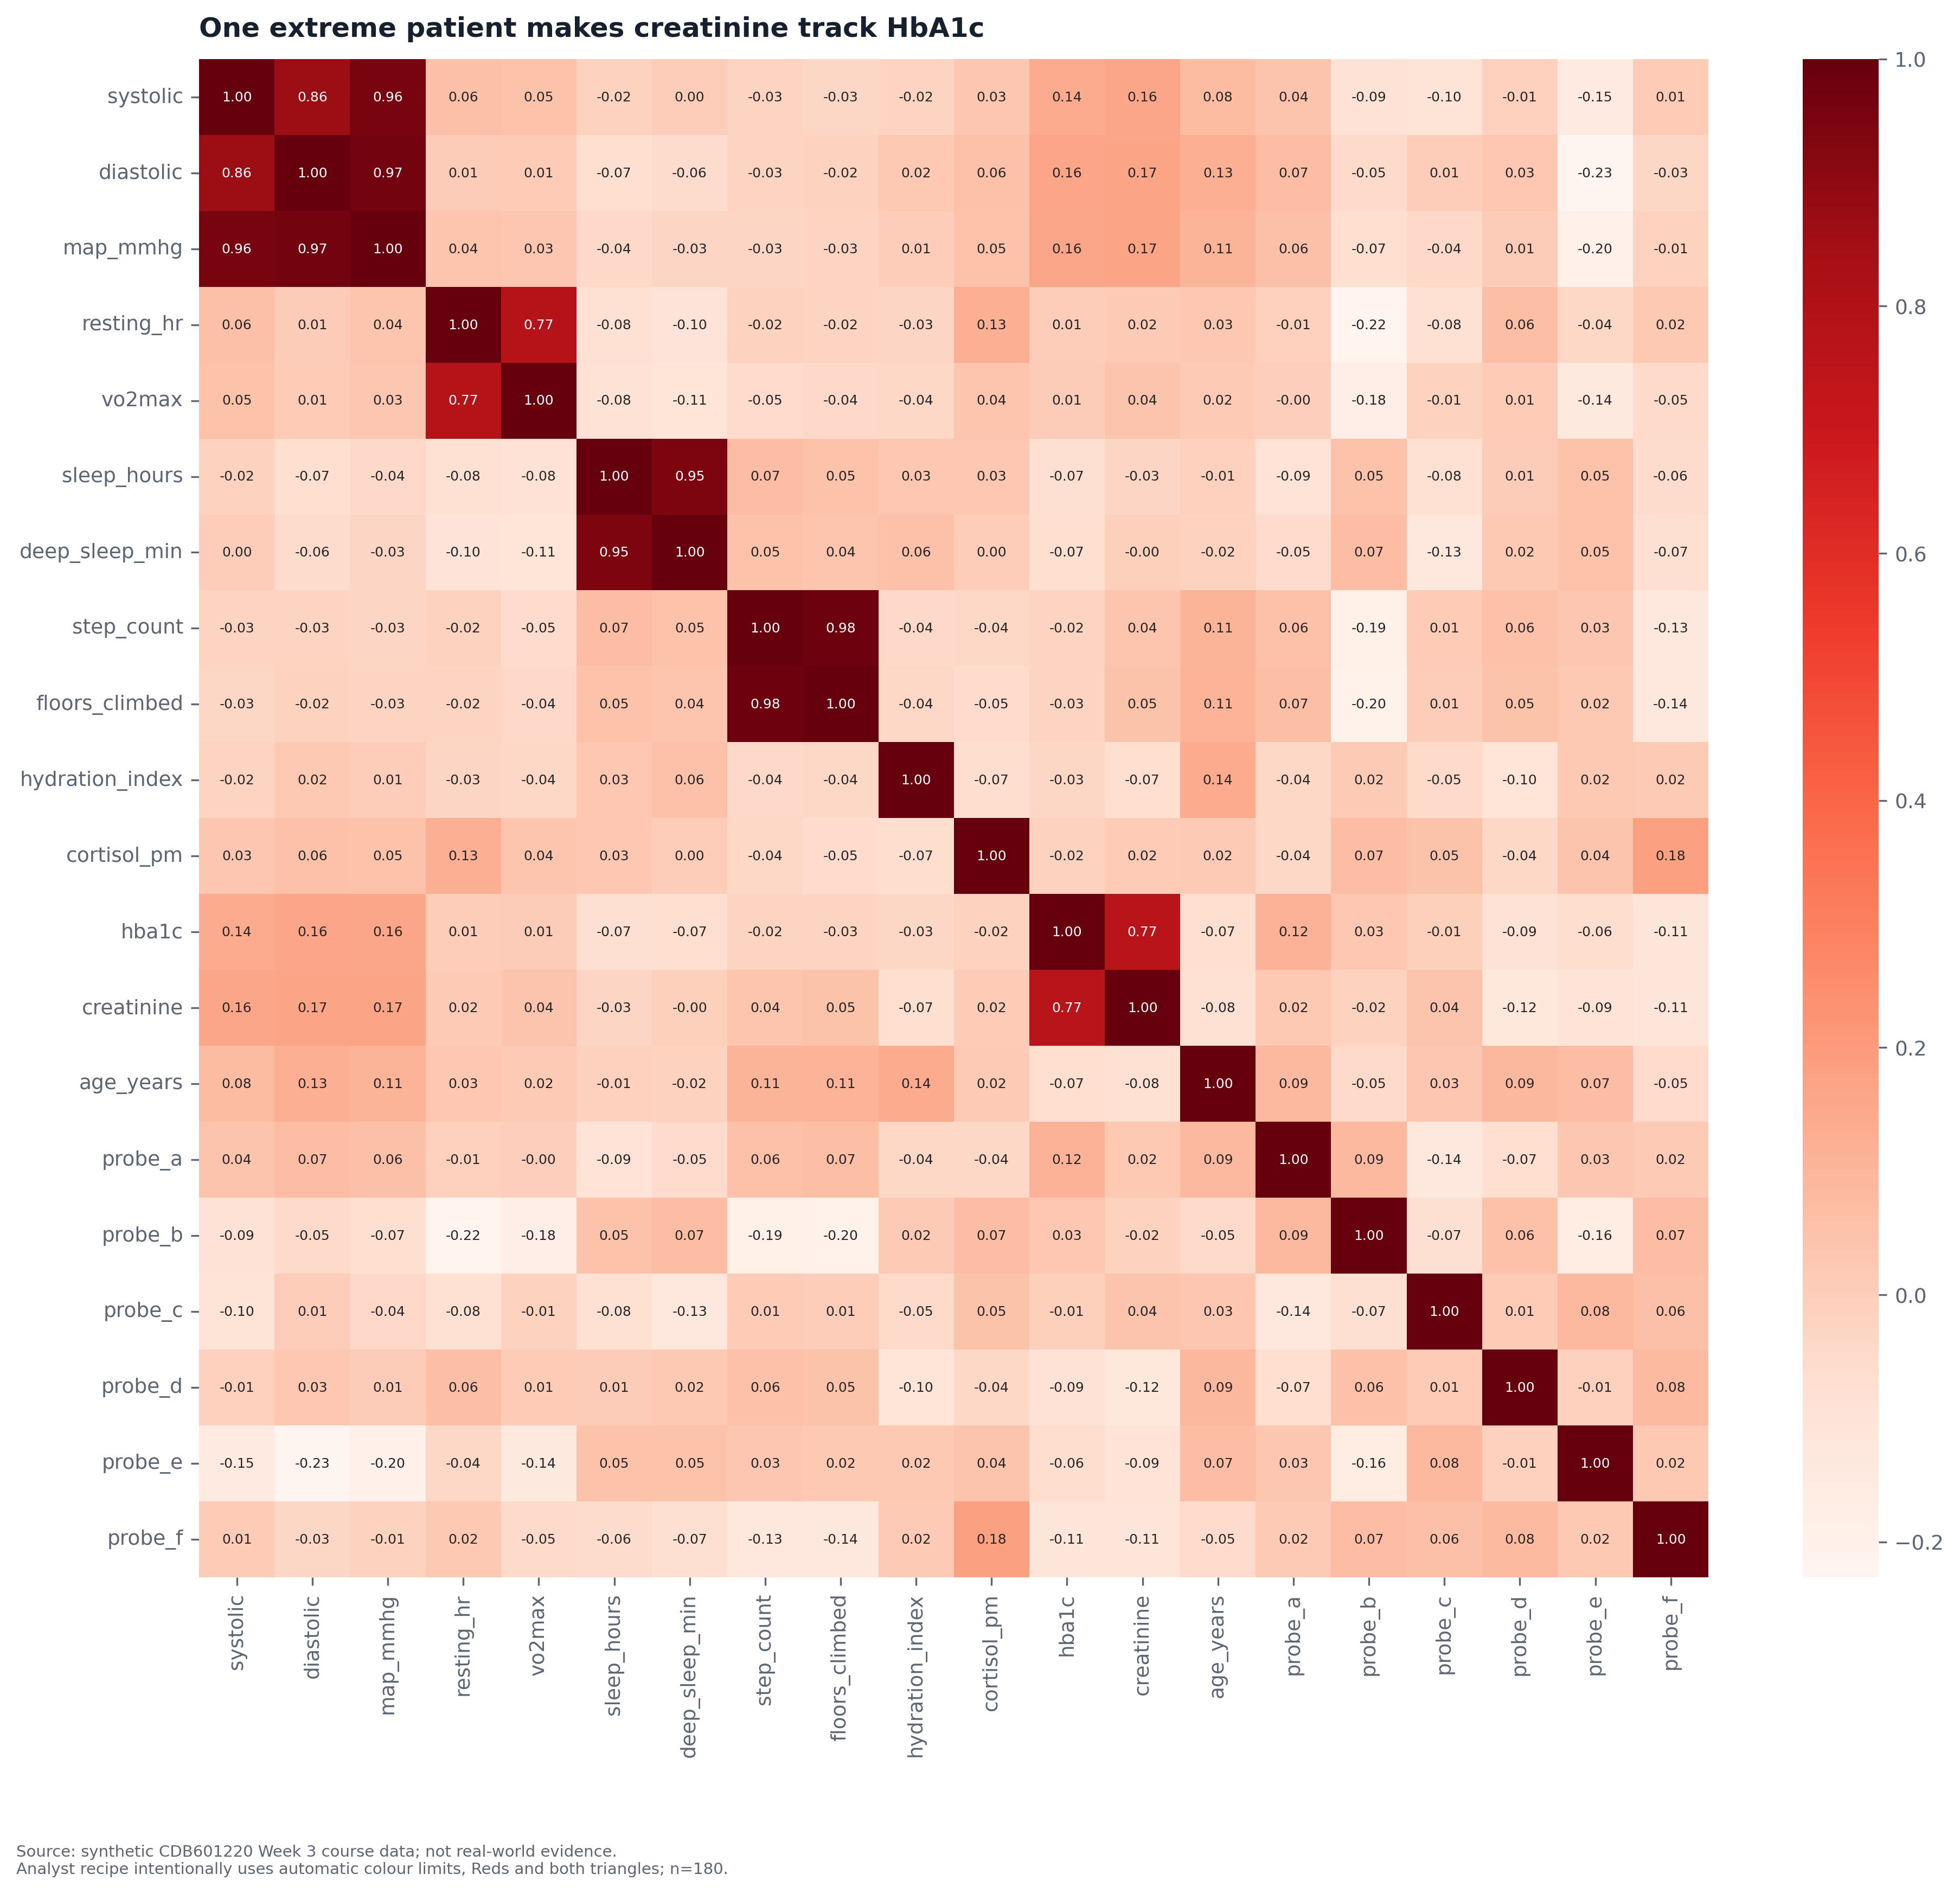

**Honest redesign**

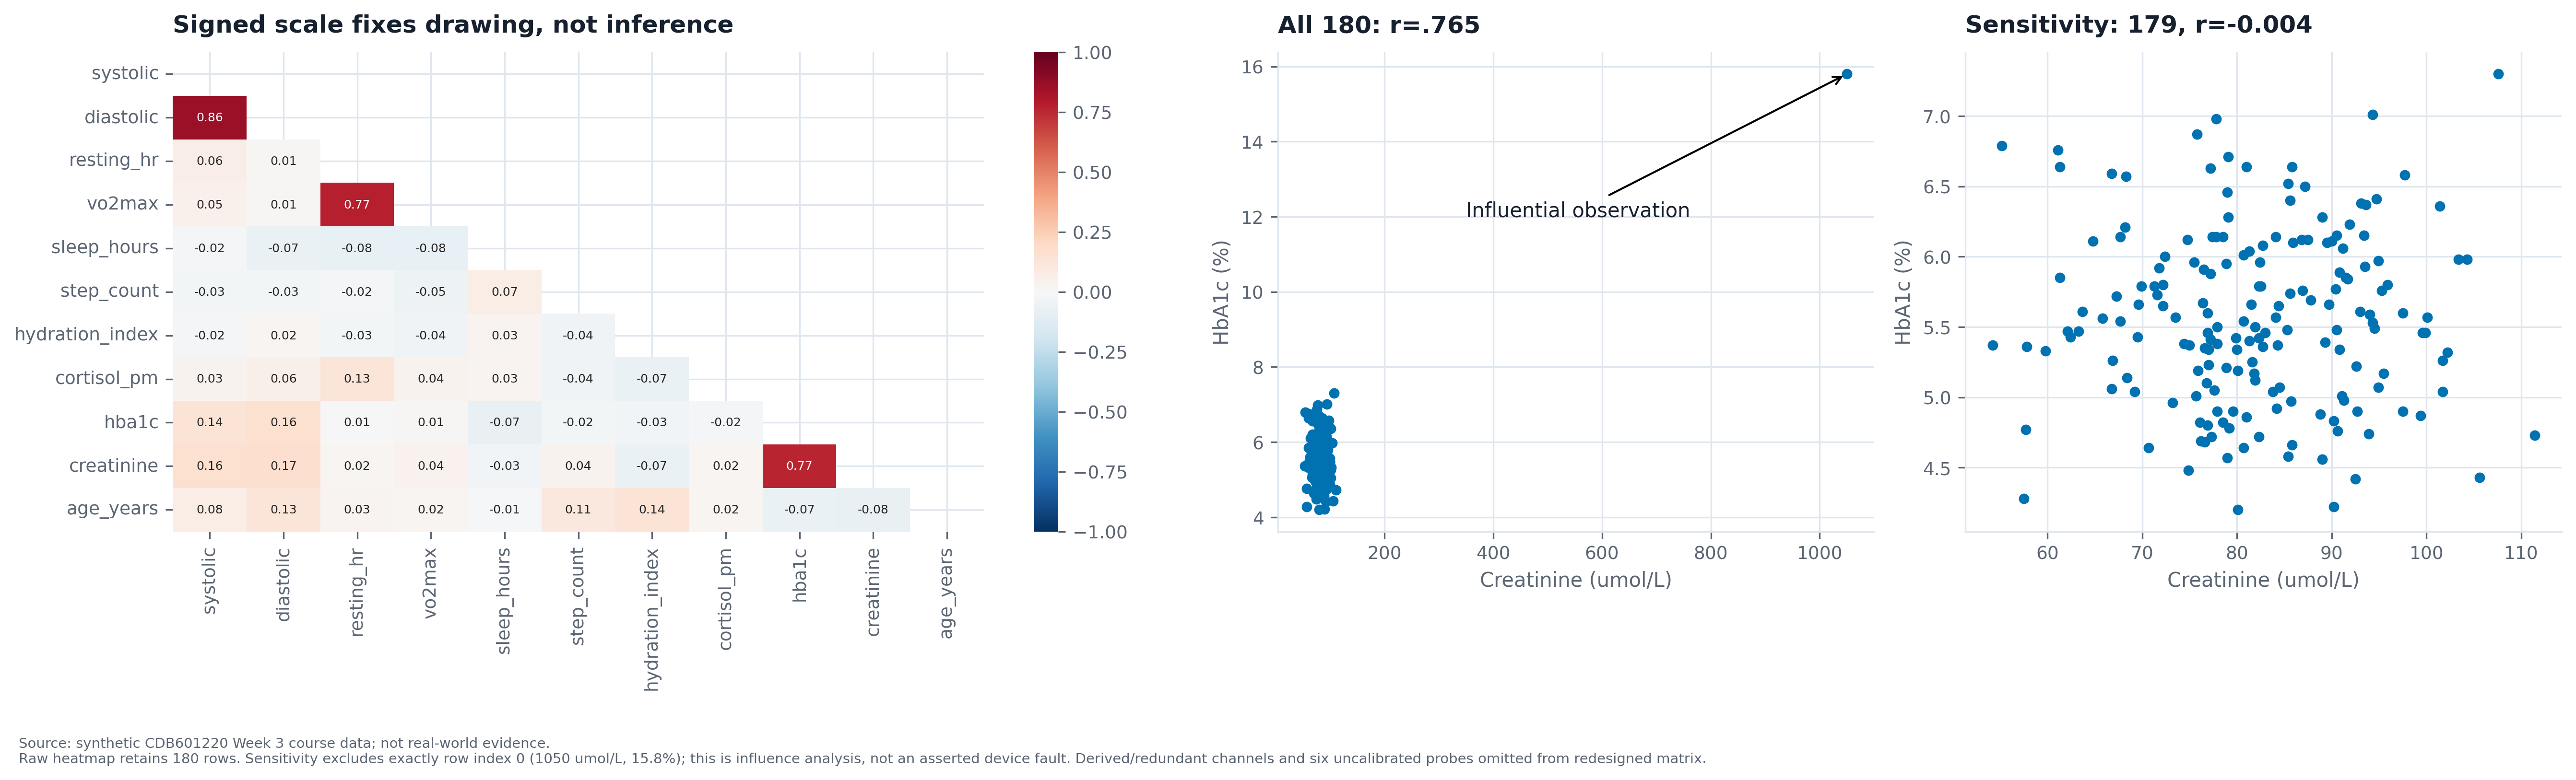

### Case 7: Independent axes manufacture a crossing

**Conclusion:** The line positions invite saying the business lost money through April.

**Decoy:** Not different currencies or arithmetic errors: both columns are PKR millions; actual profits are positive in every row.

**Mechanism:** Incommensurable normalized positions: January revenue height (52-50)/30=.0667; cost (44-40)/16=.25. Cost is drawn higher even though 44<52. Actual profit grows from 8 to 25 million.

**Redesign:** Put cost and revenue on one common axis with colour plus different marker shapes.

**Required reconstruction**

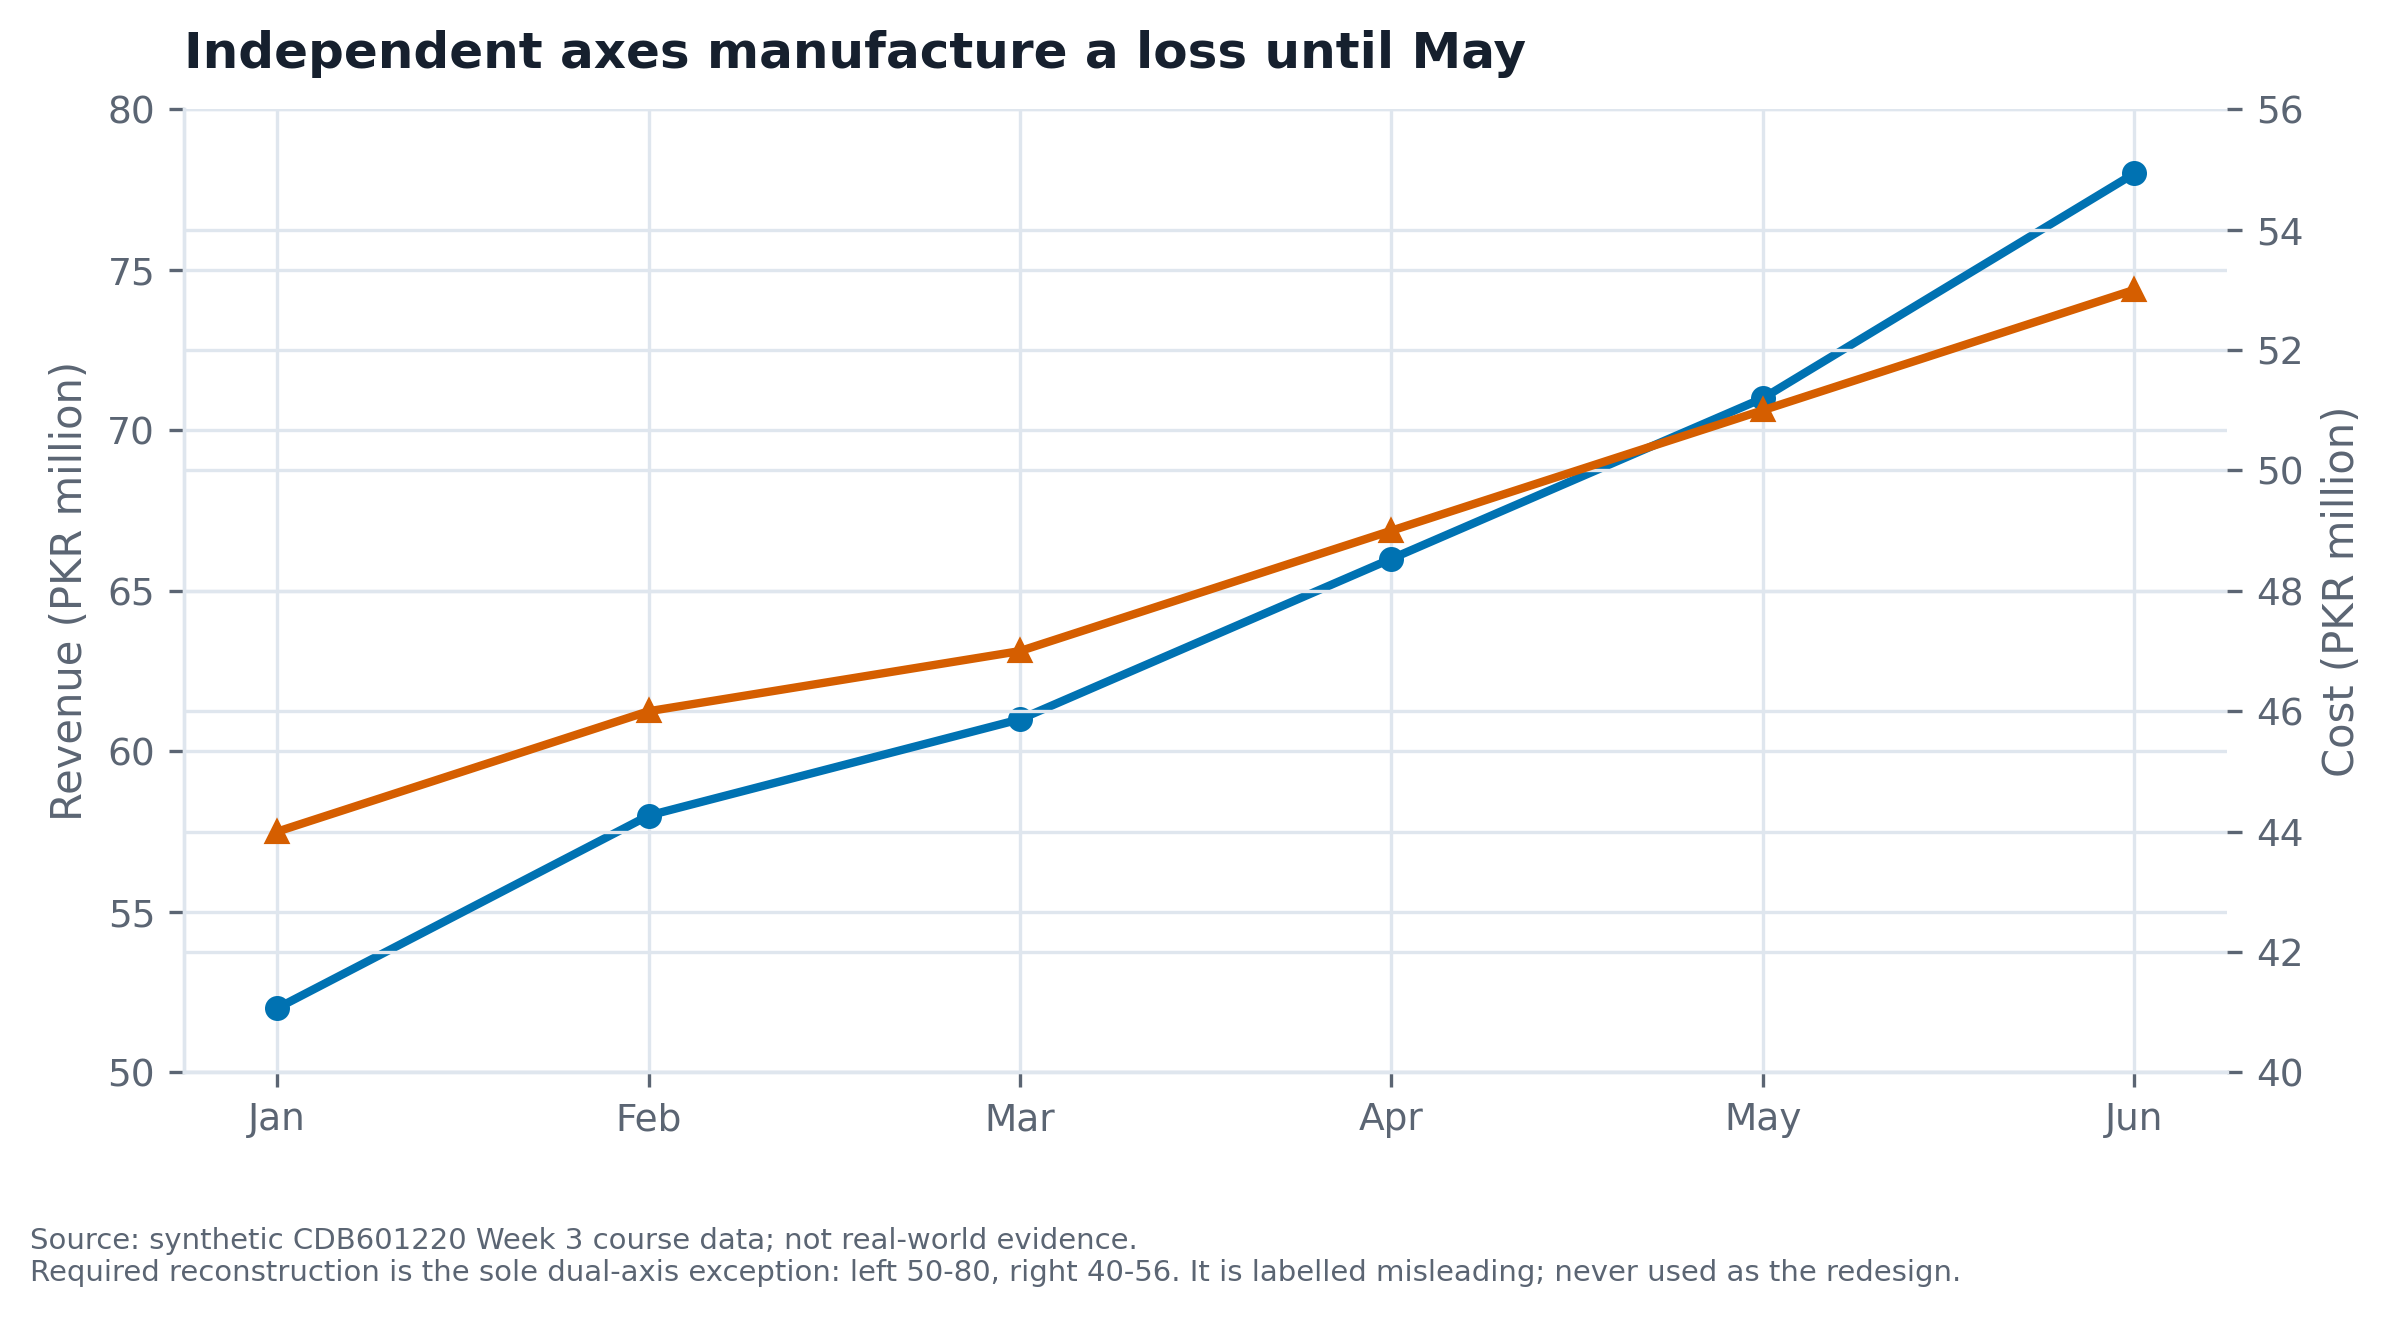

**Honest redesign**

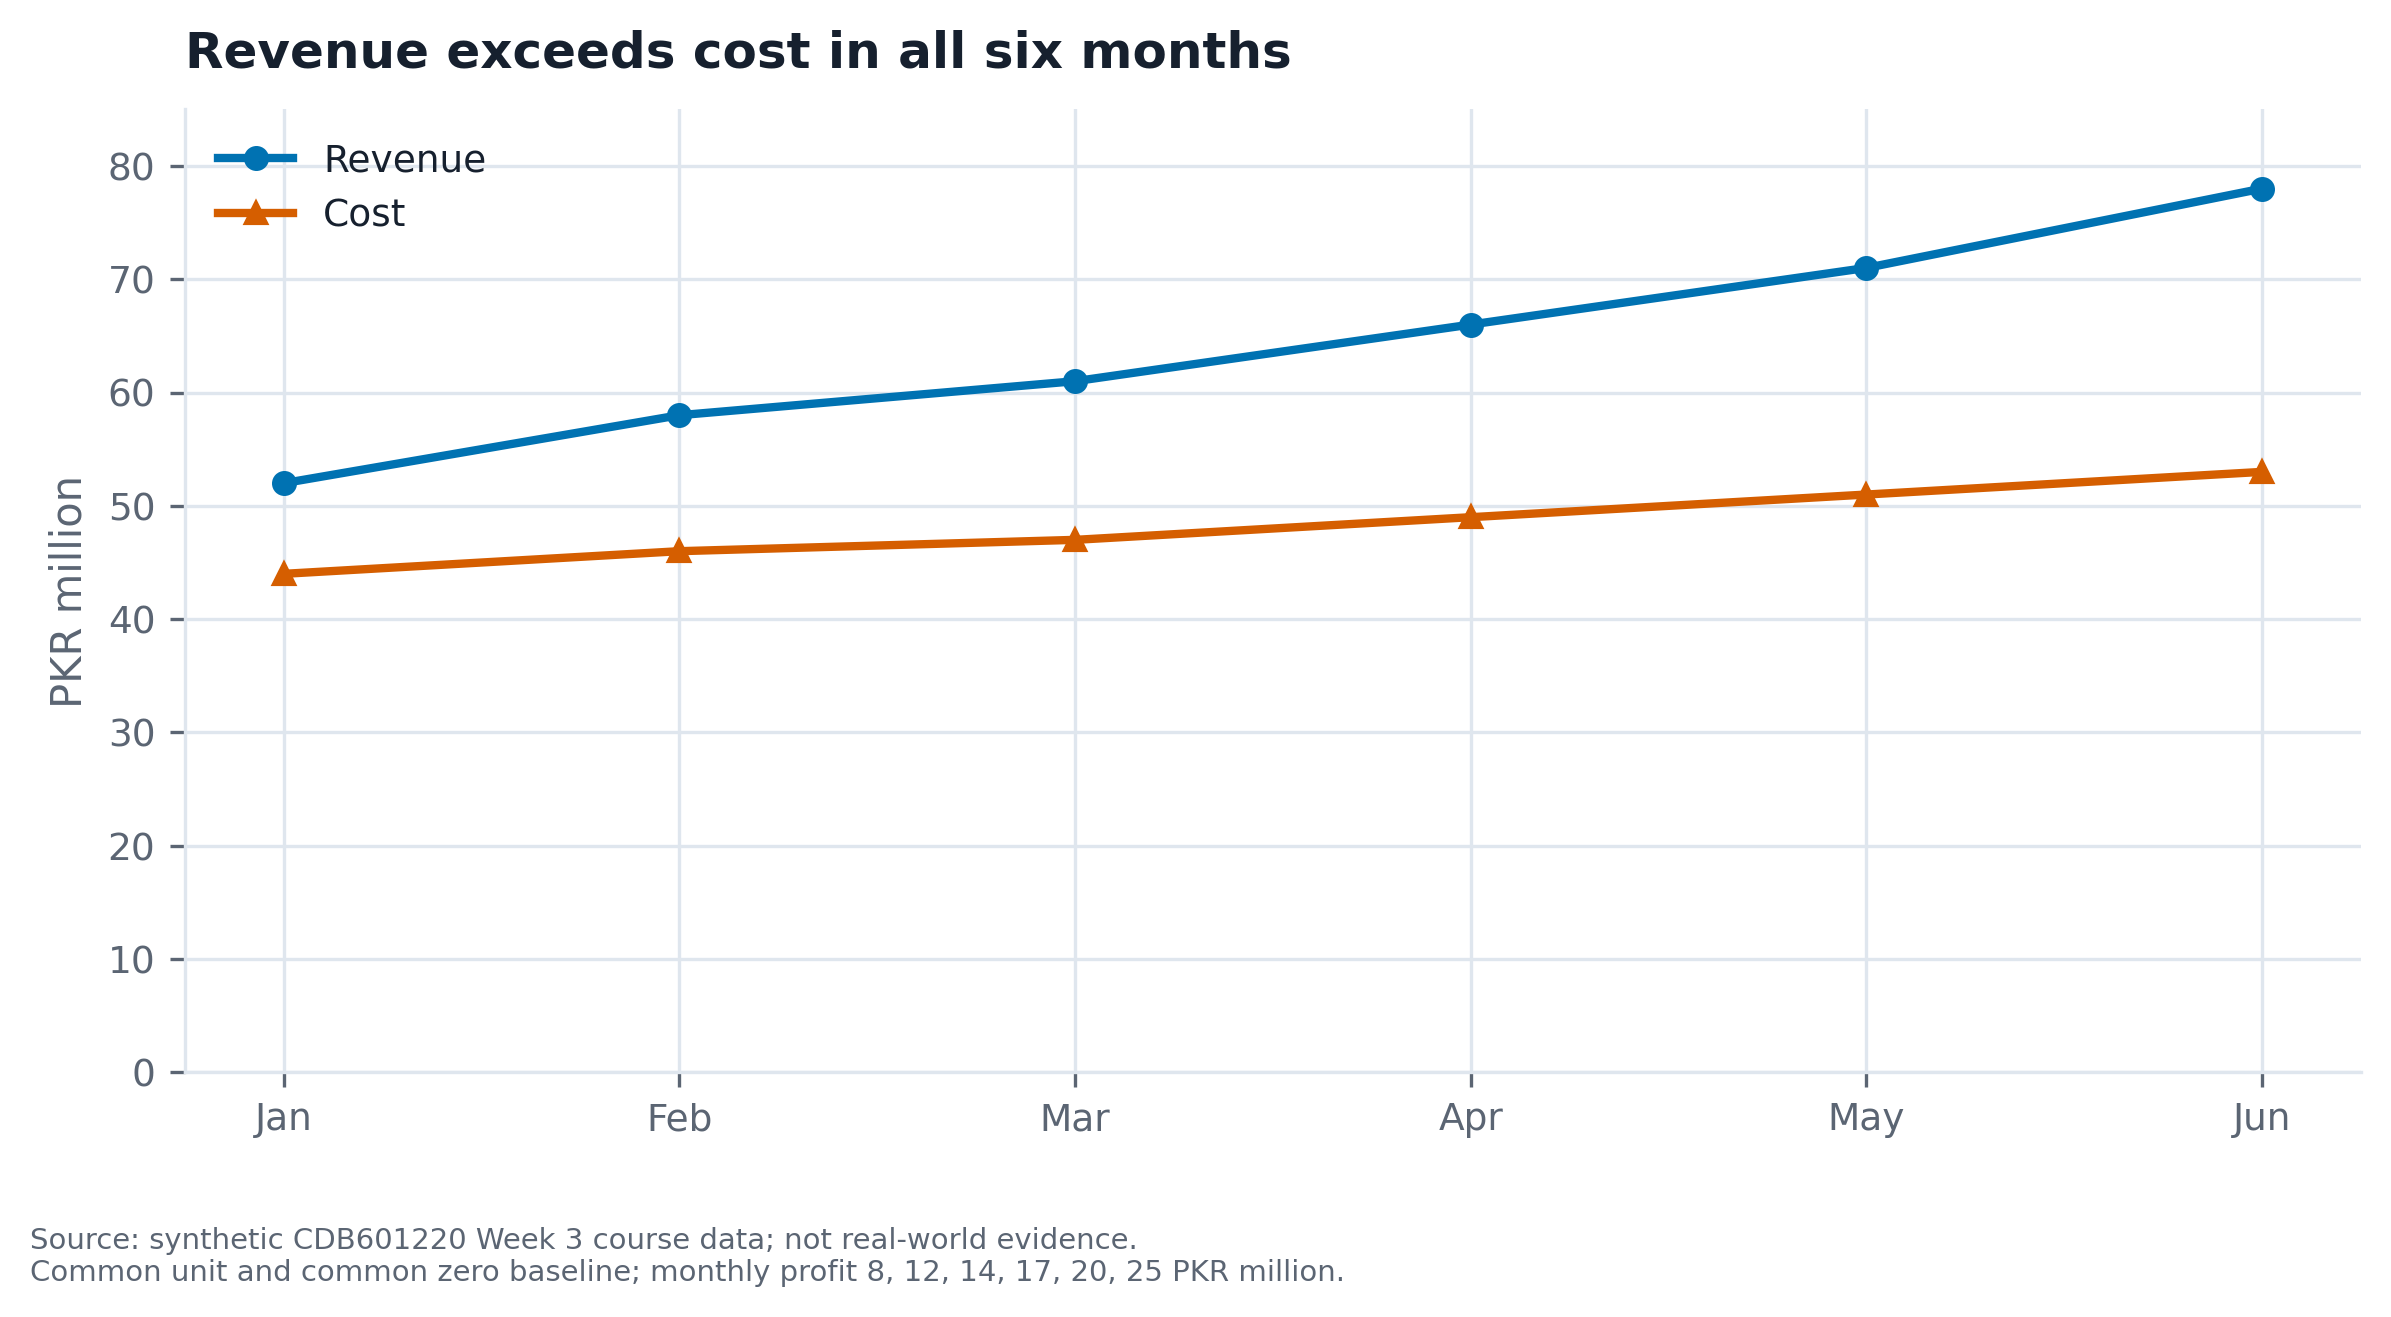

### Case 8: Binning changes the estimator, not the sample

**Conclusion:** The three panels invite three incompatible distribution stories.

**Decoy:** Sample-size changes and exclusions are ruled out: n=10,000 with identical min=92 and max=199 in every panel.

**Mechanism:** Bias/variance and quantization: width 35.67 mmHg (3 bins) merges modes; width .2675 (400 bins) is below the 1 mmHg resolution and generates artificial empty bins. Width 2.378 (45 bins) exposes the mixture with more detail.

**Redesign:** Use 5 mmHg equal-width bins, compare all three alternatives, and retain all observations; report two modes rather than claim normality.

**Required reconstruction**

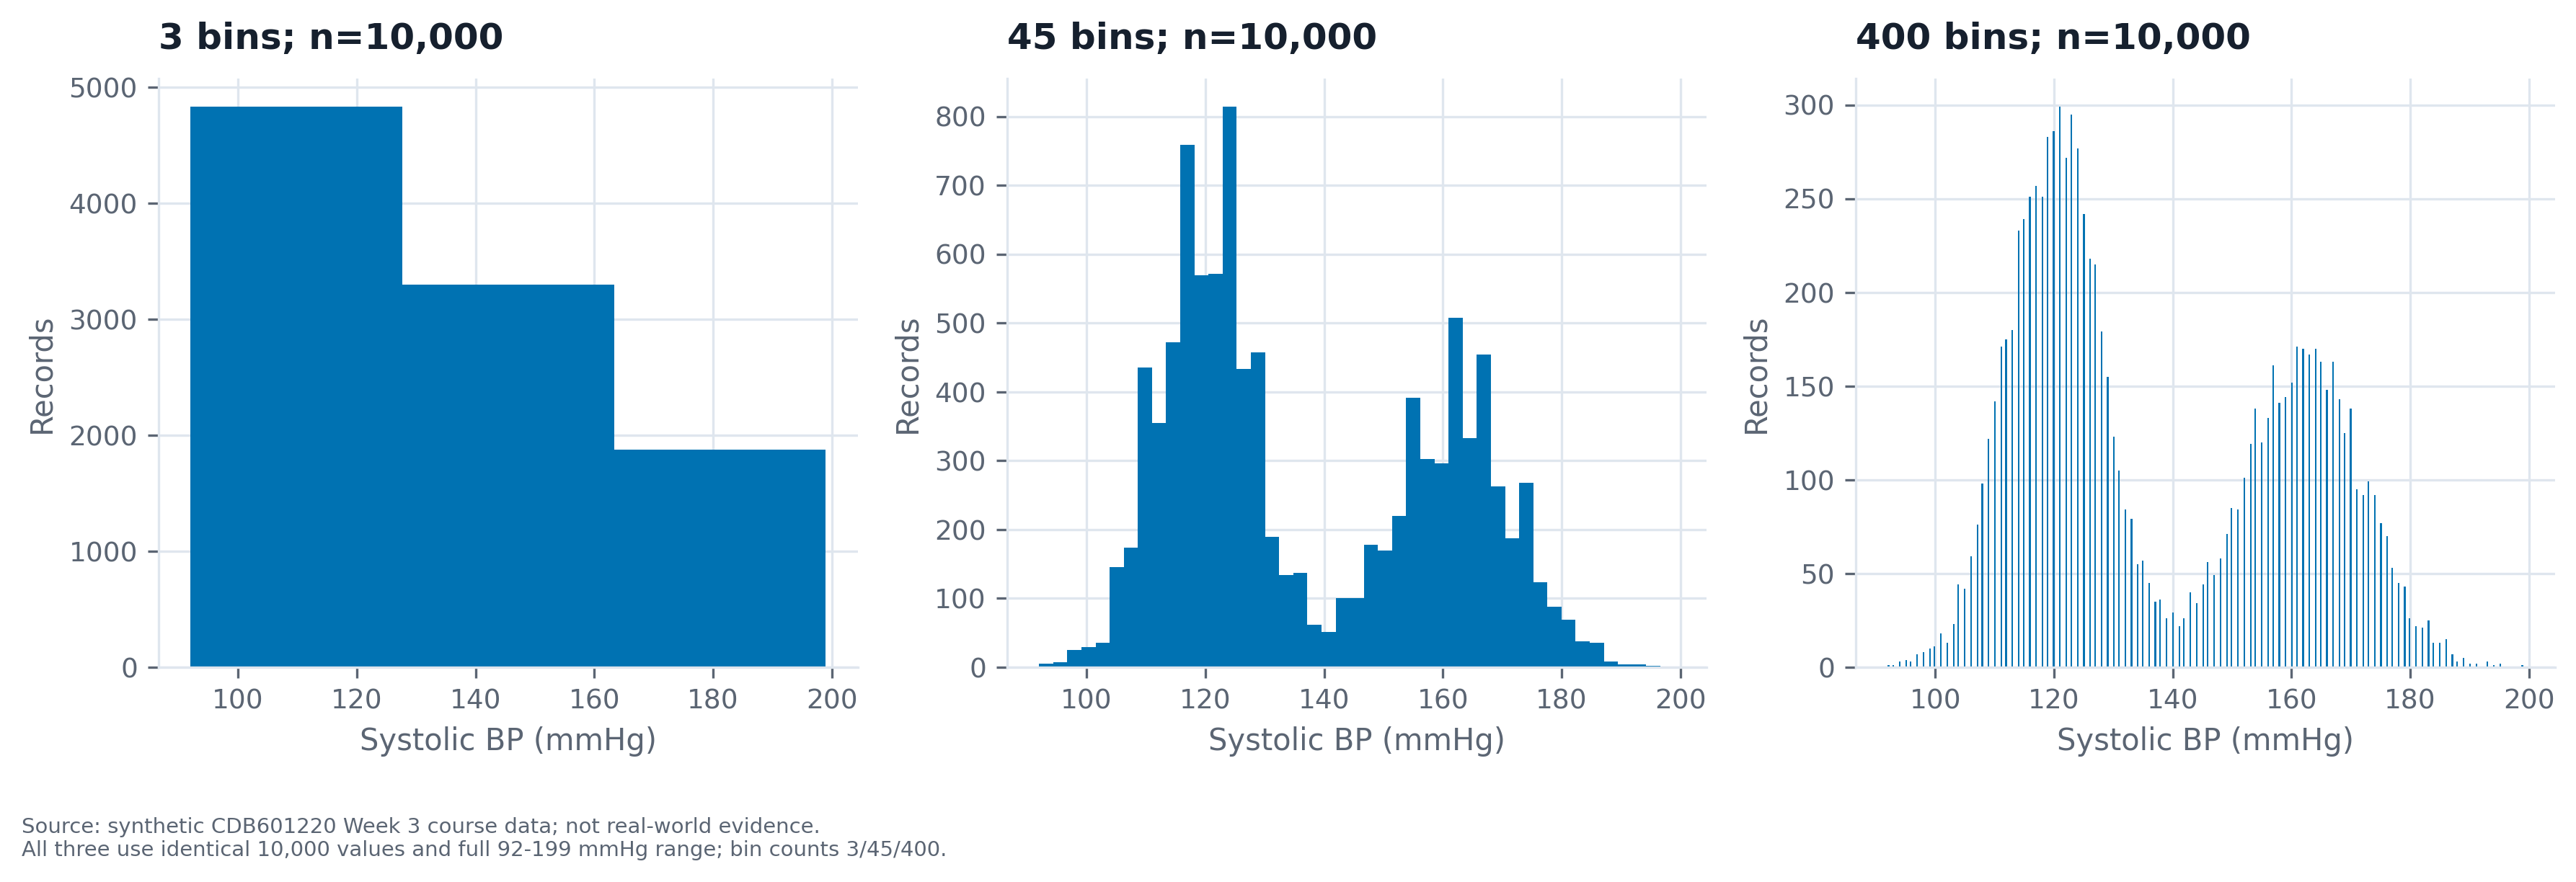

**Honest redesign**

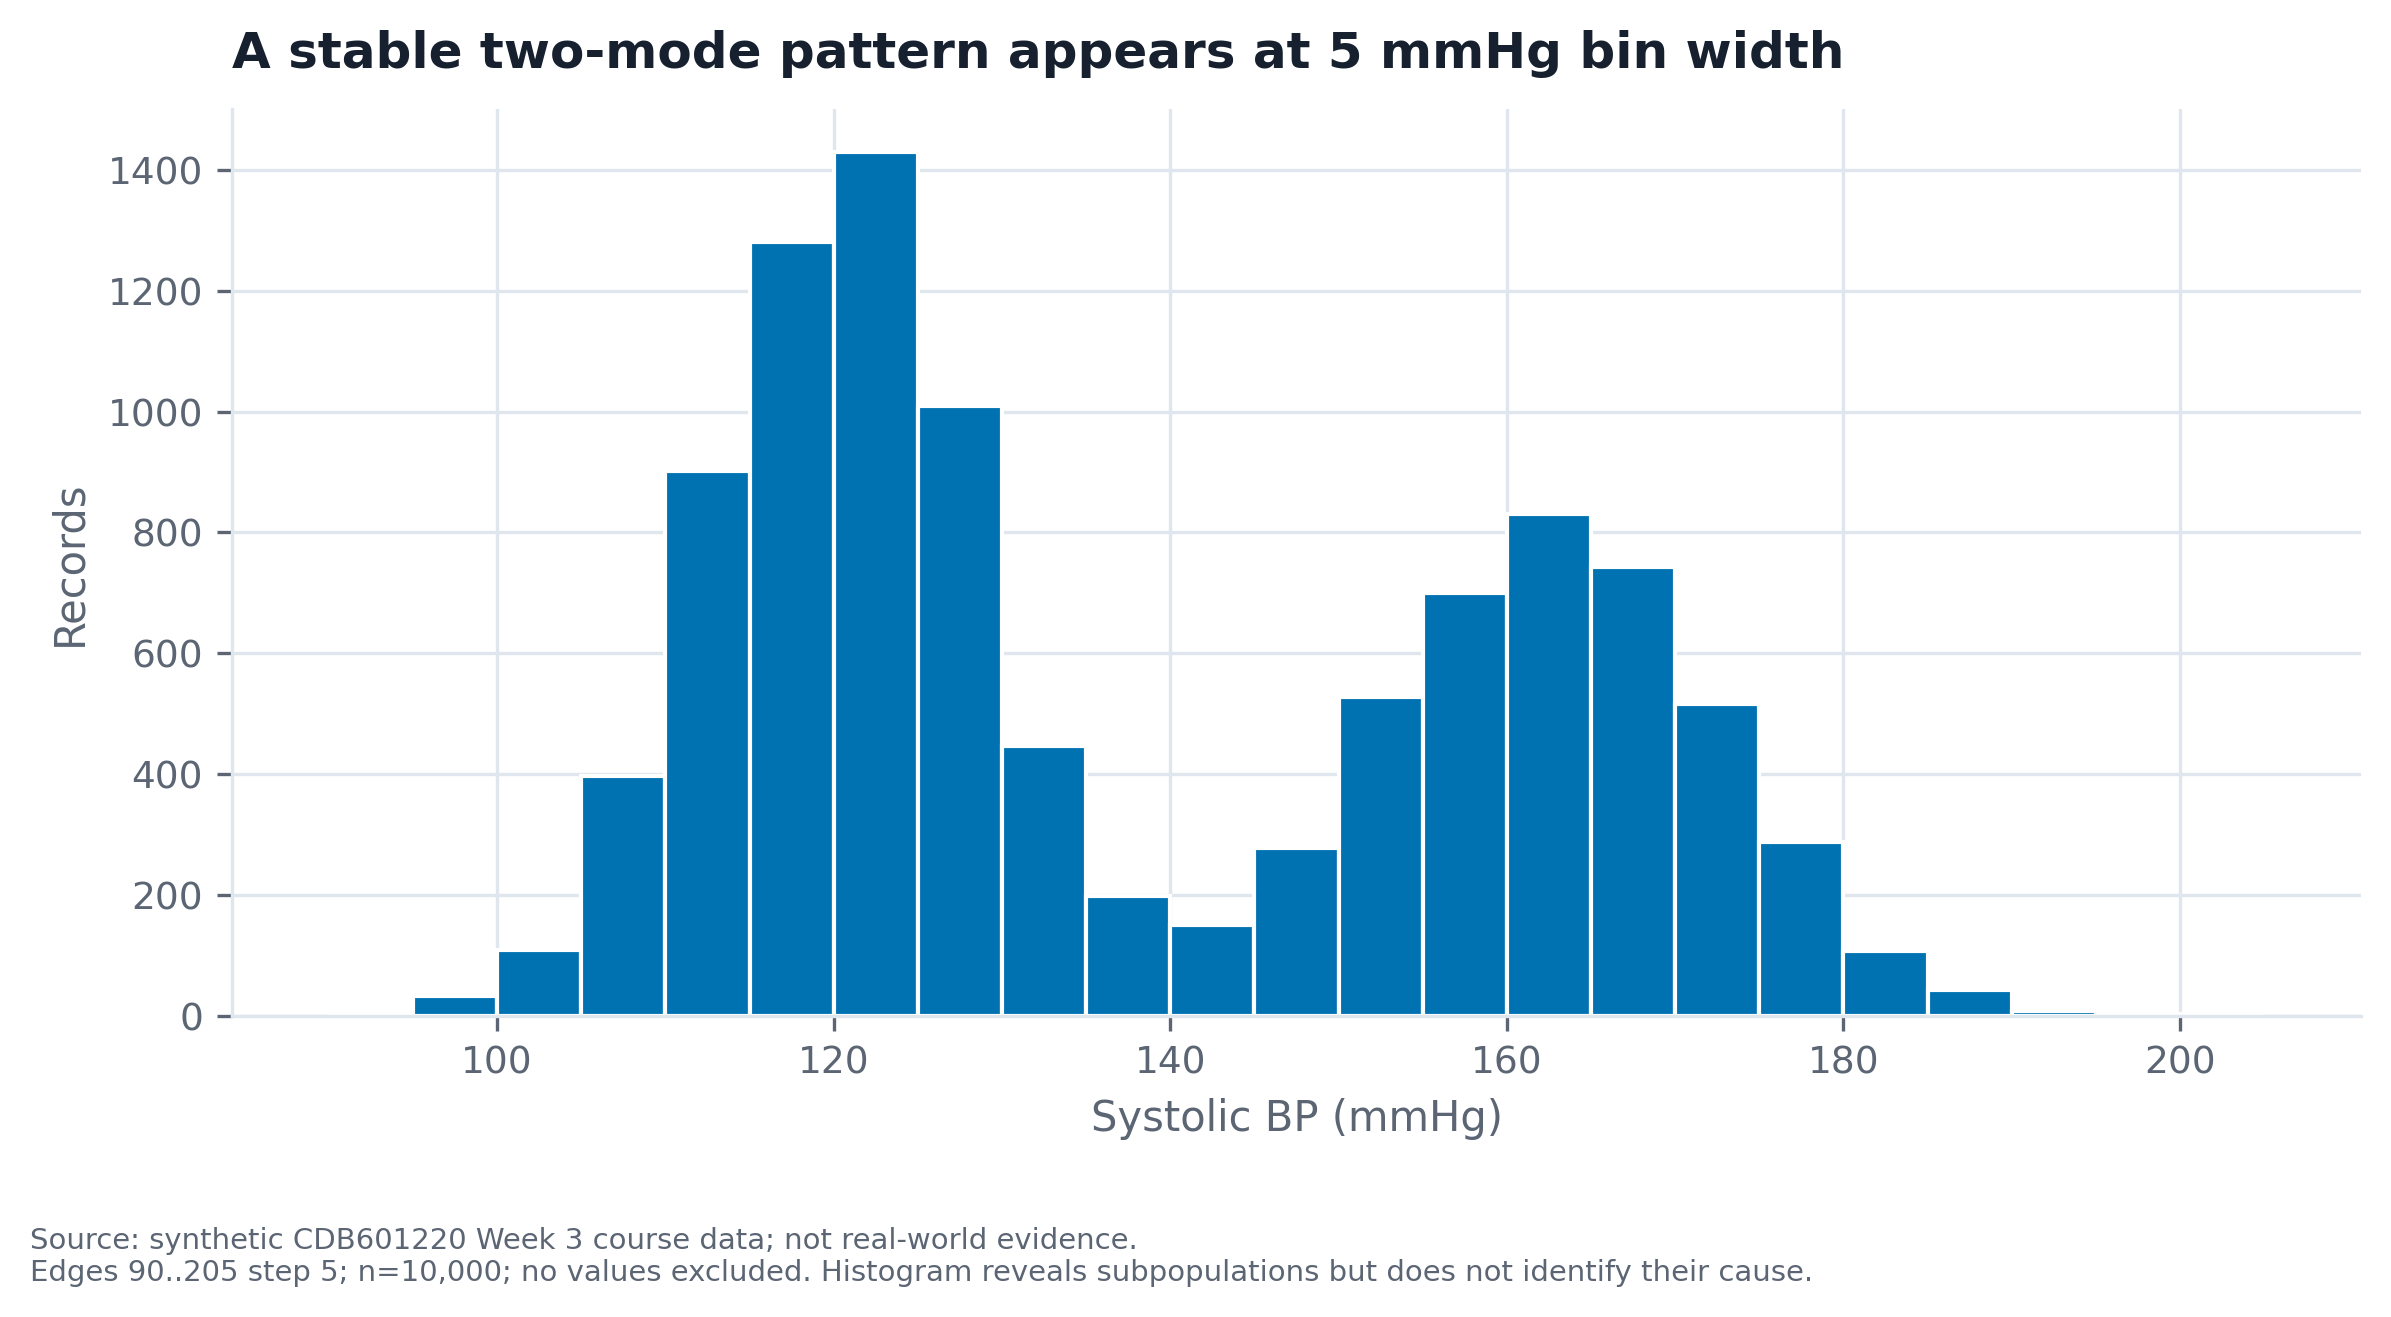

### Case 9: Kernel smoothing crosses a physical boundary

**Conclusion:** The curve invites believing some patients have saturation above 100%.

**Decoy:** No impossible source measurements: observed max is exactly 100, with zero rows above it.

**Mechanism:** Boundary bias from unbounded Gaussian kernels: Scott KDE bandwidth 0.3550 percentage point; integrated mass above 100 is 1.565%. The supplied 4.4% headline does not match this dataset under the specified default Scott bandwidth; the computed result is reported rather than fabricated. Simply setting cut=0 or clip=(0,100) hides the tail but does not correct the estimator or restore its integral.

**Redesign:** Plot empirical discrete probabilities on the bounded integer support; a truncated display of an ordinary Gaussian KDE is not a boundary correction.

**Required reconstruction**

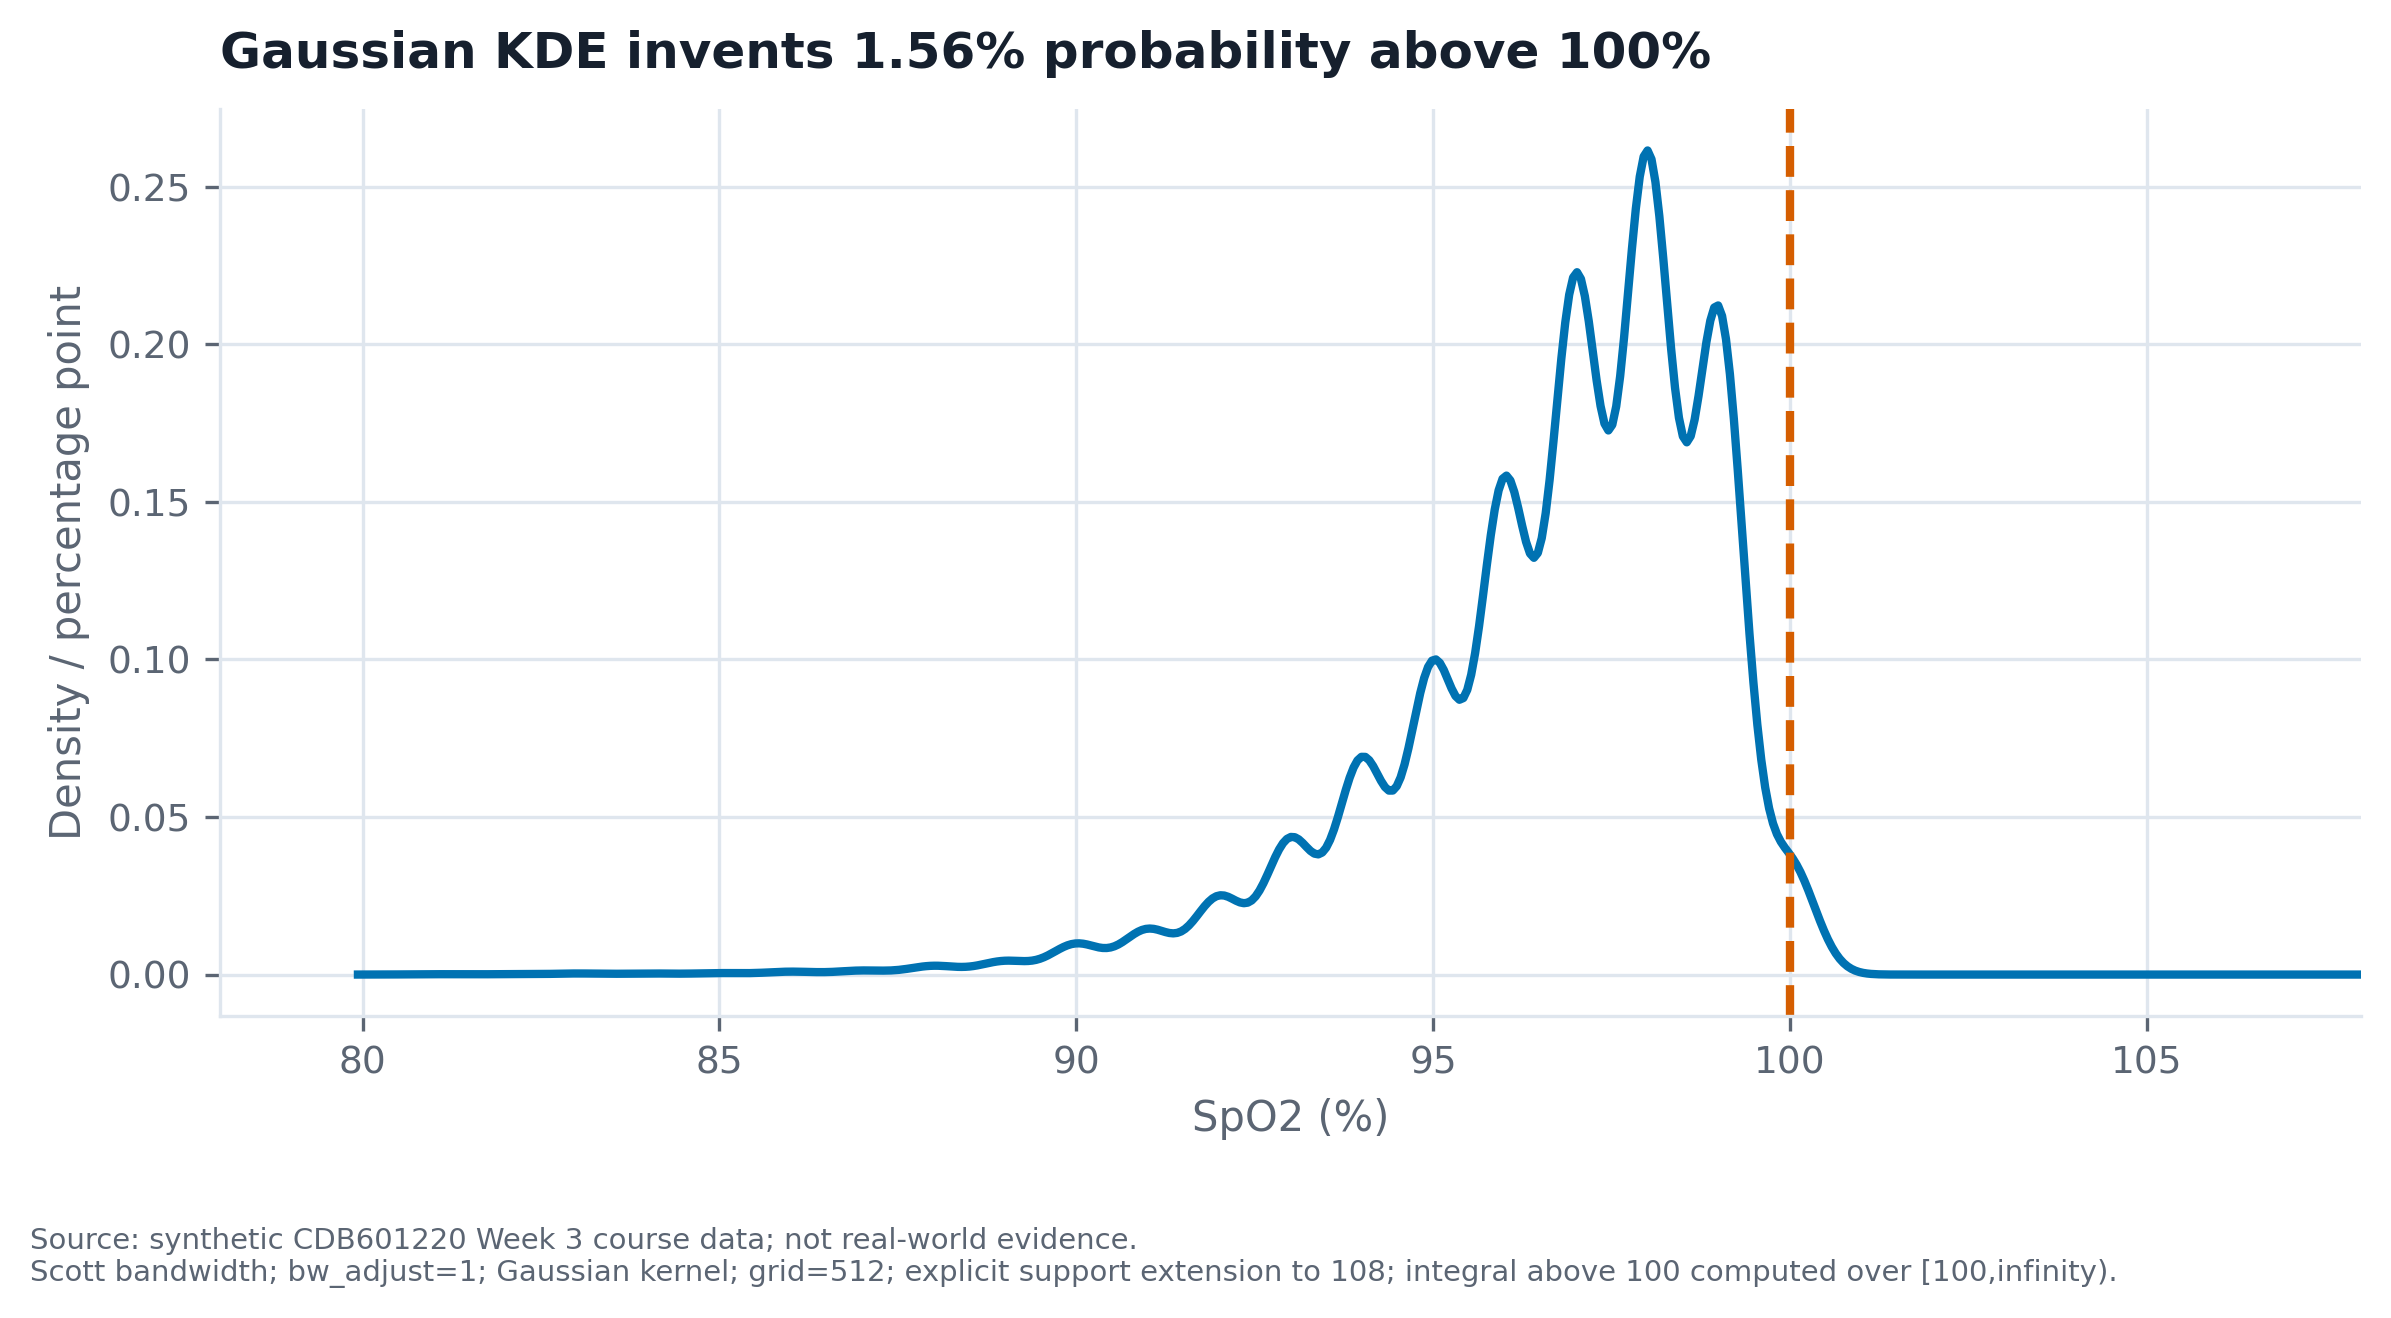

**Honest redesign**

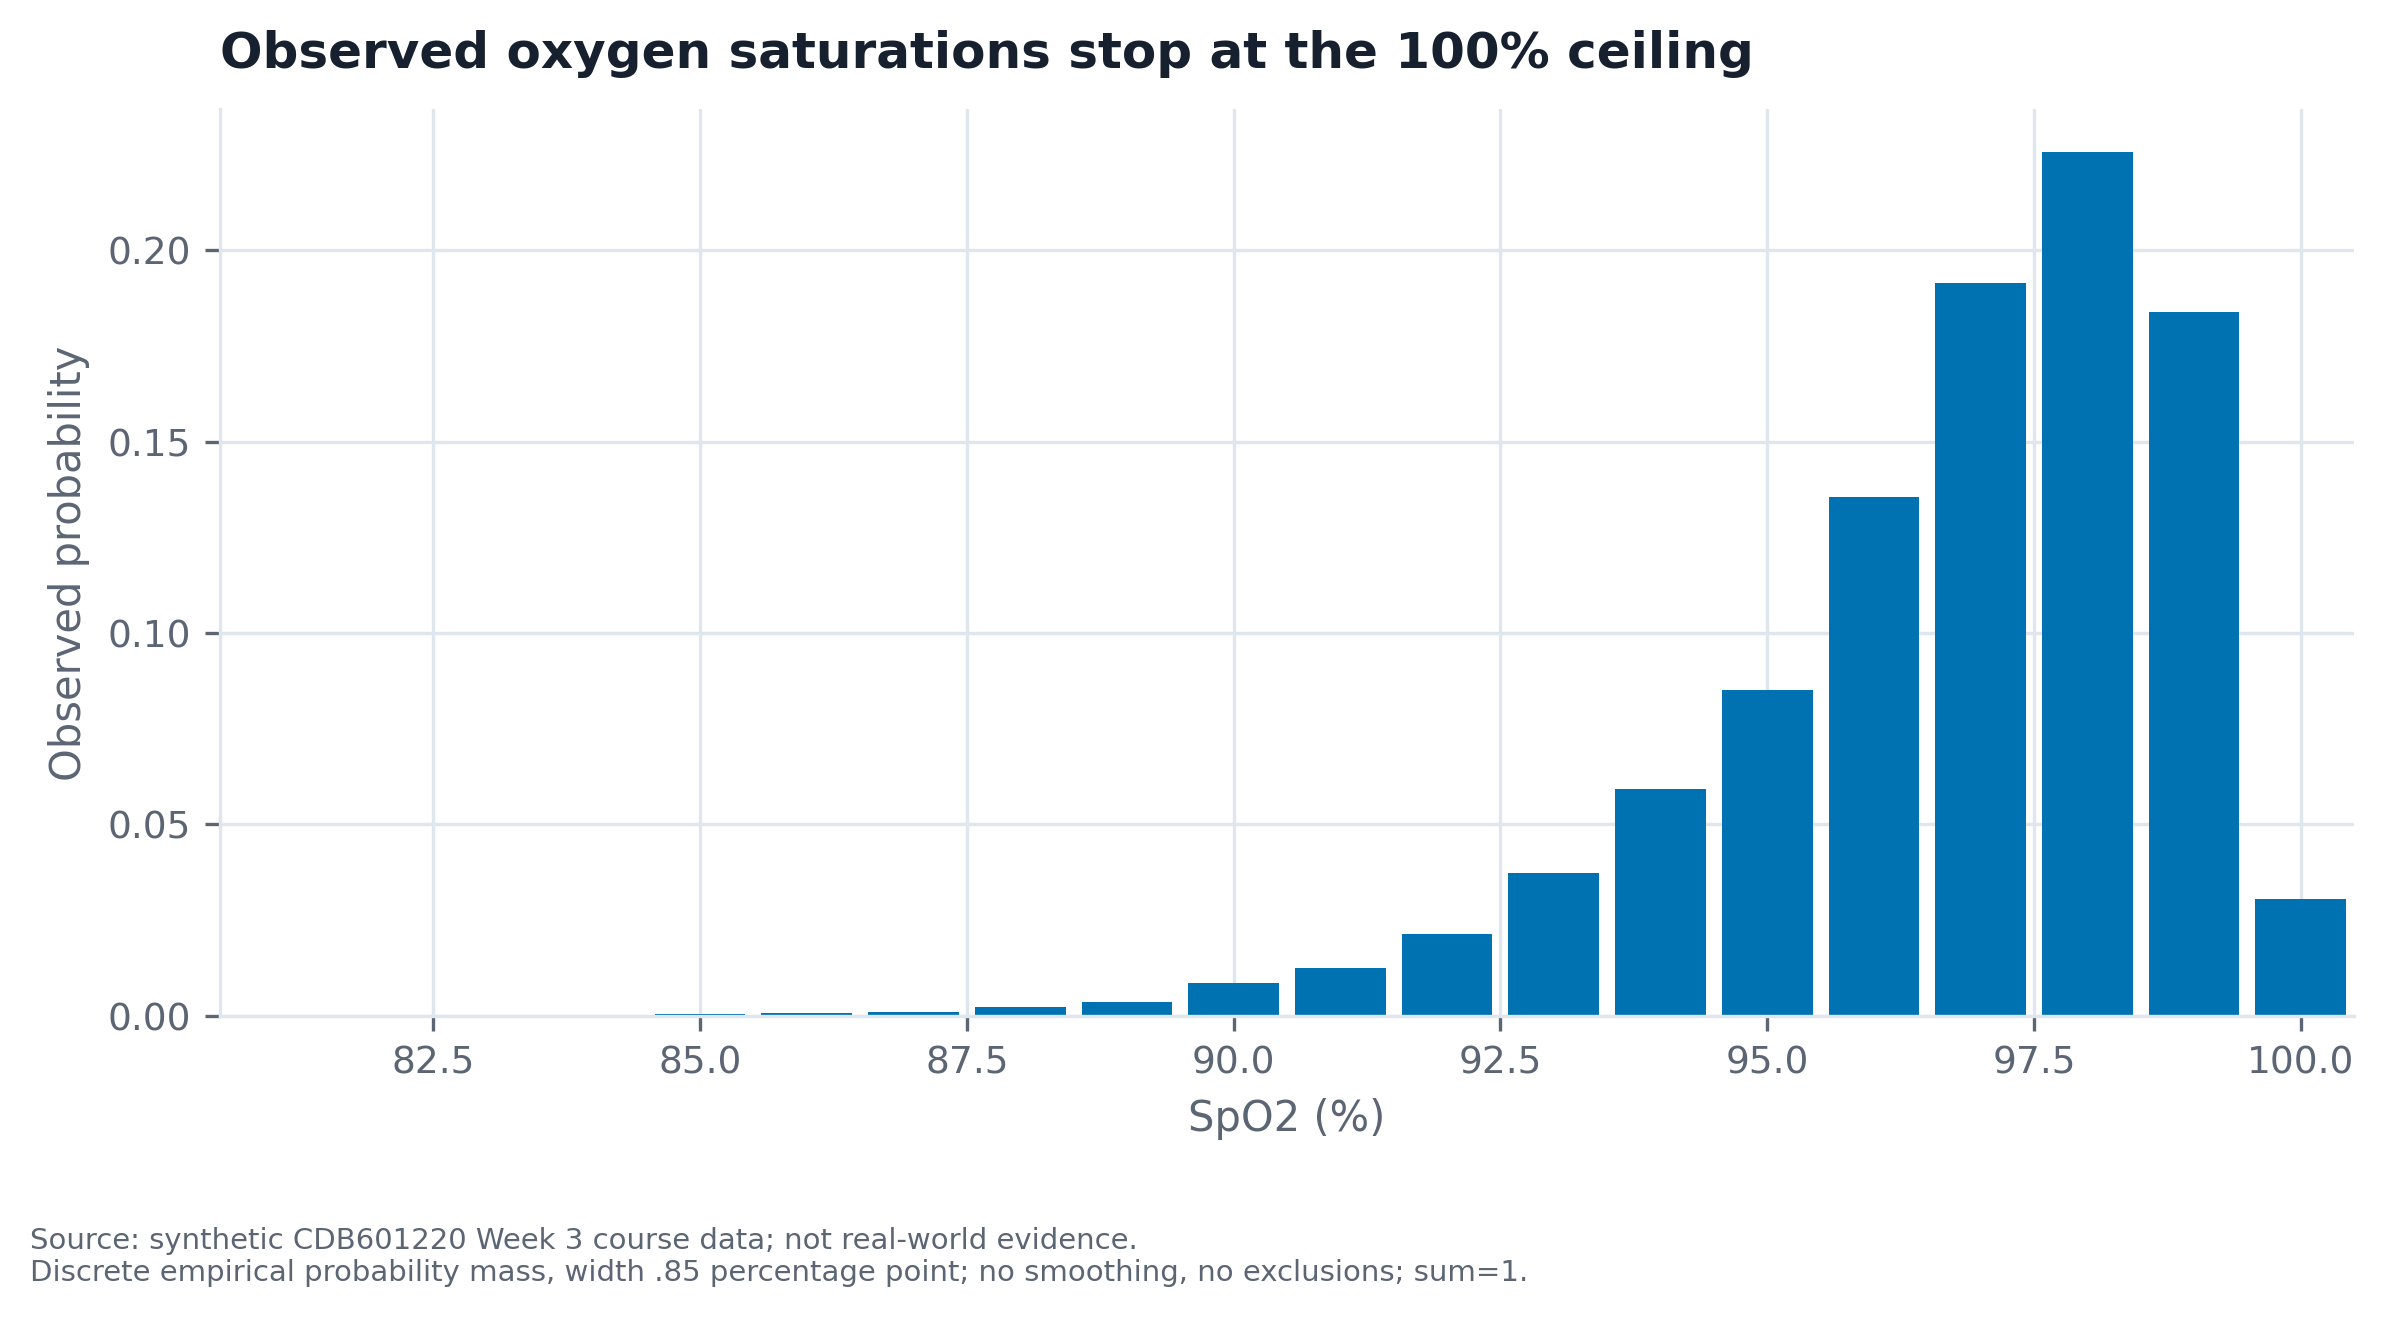

In [4]:
for row in DIAGNOSES:
    k = row['case']
    display(Markdown(f"### Case {k}: {row['title']}"))
    for field in ['conclusion','decoy','mechanism','redesign']:
        display(Markdown(f"**{field.title()}:** {row[field]}"))
    display(Markdown('**Required reconstruction**'))
    display(Image(filename=str(OUT / f'A{k:02d}_original.png'), width=1000))
    display(Markdown('**Honest redesign**'))
    display(Image(filename=str(OUT / f'A{k:02d}_redesign.png'), width=1100))

## Part B - Lie Factor audit

All five factors are calculated with the provided `vizlib.lie_factor()`. Fractional effects, verdicts, area dimensions, understated distortion, and why chart F has no single meaningful crossing Lie Factor are addressed below.

In [5]:
from common import *
from vizlib import lie_factor,lie_verdict
EXPLANATION='''Only C is honest: zero-baseline bar lengths encode the 20% data increase exactly.
A encodes only tips above 29.6%: ink grows 500% for a 6.667% tax increase (LF=75).
B scales the coin in both dimensions: area grows 125% for a 50% increase (LF=2.5).
D ink grows 12.5% for a 50% increase (LF=.25), suppressing the apparent pollution increase; an authority or polluter wishing to downplay deterioration could benefit. Intent is not known.
E sets radius proportional to population: area grows 1500% for a 300% increase (LF=5).
B and E require ink_dimension=2. Using 1 reports both as honest (LF=1) by ignoring squared area growth.
F has no single Lie Factor for the alleged crossing: the formula assumes one comparable magnitude encoding and baseline for a data change. F mixes two unrelated affine coordinate mappings; the crossing is a relation between independently scaled series, not one graphic effect. A series-specific length audit would not quantify the false profit implication.
Actual revenue exceeds cost in all months: profit = 8,12,14,17,20,25 PKR million. Profit increased 212.5% from January to June.
'''
def main():
    d=read('case07_lie_factor');rows=[]
    for r in d.itertuples():
        lf,de,ge=lie_factor(r.value_start,r.value_end,r.ink_start,r.ink_end,ink_dimension=r.ink_dimension)
        rows.append({'chart':r.chart_id,'data_effect':de,'graphic_effect':ge,'lie_factor':lf,'verdict':lie_verdict(lf),'ink_dimension':r.ink_dimension})
    t=pd.DataFrame(rows);assert t.loc[t.verdict=='honest','chart'].tolist()==['C'];t.to_csv(ROOT/'outputs'/'partB_results.csv',index=False)
    text=t.to_string(index=False)+'\n\n'+EXPLANATION+SOURCE
    print(text);(ROOT/'outputs'/'partB_output.txt').write_text(text)
    return t
if __name__=='__main__':main()


chart  data_effect  graphic_effect  lie_factor            verdict  ink_dimension
    A     0.066667           5.000       75.00 exaggerates 75.00x              1
    B     0.500000           1.250        2.50  exaggerates 2.50x              2
    C     0.200000           0.200        1.00             honest              1
    D     0.500000           0.125        0.25 understates (0.25)              1
    E     3.000000          15.000        5.00  exaggerates 5.00x              2

Only C is honest: zero-baseline bar lengths encode the 20% data increase exactly.
A encodes only tips above 29.6%: ink grows 500% for a 6.667% tax increase (LF=75).
B scales the coin in both dimensions: area grows 125% for a 50% increase (LF=2.5).
D ink grows 12.5% for a 50% increase (LF=.25), suppressing the apparent pollution increase; an authority or polluter wishing to downplay deterioration could benefit. Intent is not known.
E sets radius proportional to population: area grows 1500% for a 300% increase

## Part C - Quantitative palette proof

Start with the first four tab10 colours as an unverified candidate. Compare normal, deutan, protan and tritan swatches against the supplied course palette. Report the closest pair in every simulation and its course-threshold verdict.

In [6]:
from common import *
from vizlib import simulate_cvd,worst_pair,verdict
MY_PALETTE=['#1F77B4','#FF7F0E','#2CA02C','#D62728']
COURSE=PALETTE['series']+[PALETTE['series_4th']]
KINDS=['normal','deutan','protan','tritan']
EXPLANATION='''Candidate: first four tab10 colours, selected for appearance without assuming safety.
The tab10 candidate fails: deutan S3/S4 DeltaE=4.06, protan S2/S3=.68, tritan S1/S3=6.72. The overall worst is protan S2/S3; normal-vision distance does not establish accessibility.
Course palette: the worst overall is deutan S3 (green)/S4 (purple), DeltaE=7.55. This is the course's 6-8 range: permitted only with a second channel. Protan and tritan minima exceed 8, but that does not cancel the deutan restriction.
For more than three categories, use direct labels, separated positions, distinct markers/line styles or hatches, or small multiples. Never introduce a fourth colour as the only category identifier. Under DeltaE<6, change the palette rather than merely trusting a label.
Simulations are severity-1.0 Machado matrices in linear RGB; distances are OKLab x100. These are the course's heuristic thresholds, not a universal clinical guarantee of readability.
'''
def main():
    fig,axes=plt.subplots(2,4,figsize=(12,4.8));rows=[]
    for row,(label,pal) in enumerate([('Candidate: tab10 first four',MY_PALETTE),('Course: three plus fourth slot',COURSE)]):
        for col,kind in enumerate(KINDS):
            ax=axes[row,col];shown=pal if kind=='normal' else simulate_cvd(pal,kind)
            for i,h in enumerate(shown):
                ax.add_patch(plt.Rectangle((i,0),.9,1,color=h));ax.text(i+.45,-.15,f'S{i+1}',ha='center',fontsize=9)
            ax.set(xlim=(-.1,4),ylim=(-.35,1.25),title=kind);ax.axis('off')
            if col==0:ax.text(0,1.45,label,fontsize=10)
            i,j,a,b,de=worst_pair(pal,kind);rows.append({'palette':label,'vision':kind,'pair':f'S{i}/S{j}','delta_e':de,'verdict':verdict(de)})
    fig.suptitle('The fourth course colour needs a second encoding channel')
    finish(fig,'partC_palette','Machado et al. (2009), severity=1; linear RGB; OKLab distances. Slots are explicitly labelled.')
    t=pd.DataFrame(rows);t.to_csv(ROOT/'outputs'/'partC_results.csv',index=False);text=t.to_string(index=False)+'\n\n'+EXPLANATION
    (ROOT/'outputs'/'partC_output.txt').write_text(text);print(text);return t
if __name__=='__main__':main()


                       palette vision  pair   delta_e                verdict
   Candidate: tab10 first four normal S2/S4 18.597645                  clear
   Candidate: tab10 first four deutan S3/S4  4.058730    FAILS — same colour
   Candidate: tab10 first four protan S2/S3  0.681177    FAILS — same colour
   Candidate: tab10 first four tritan S1/S3  6.721180 needs a second channel
Course: three plus fourth slot normal S2/S4 16.419658                  clear
Course: three plus fourth slot deutan S3/S4  7.546638 needs a second channel
Course: three plus fourth slot protan S1/S4  9.494498                     ok
Course: three plus fourth slot tritan S1/S3  8.372201                     ok

Candidate: first four tab10 colours, selected for appearance without assuming safety.
The tab10 candidate fails: deutan S3/S4 DeltaE=4.06, protan S2/S3=.68, tritan S1/S3=6.72. The overall worst is protan S2/S3; normal-vision distance does not establish accessibility.
Course palette: the worst overall is d

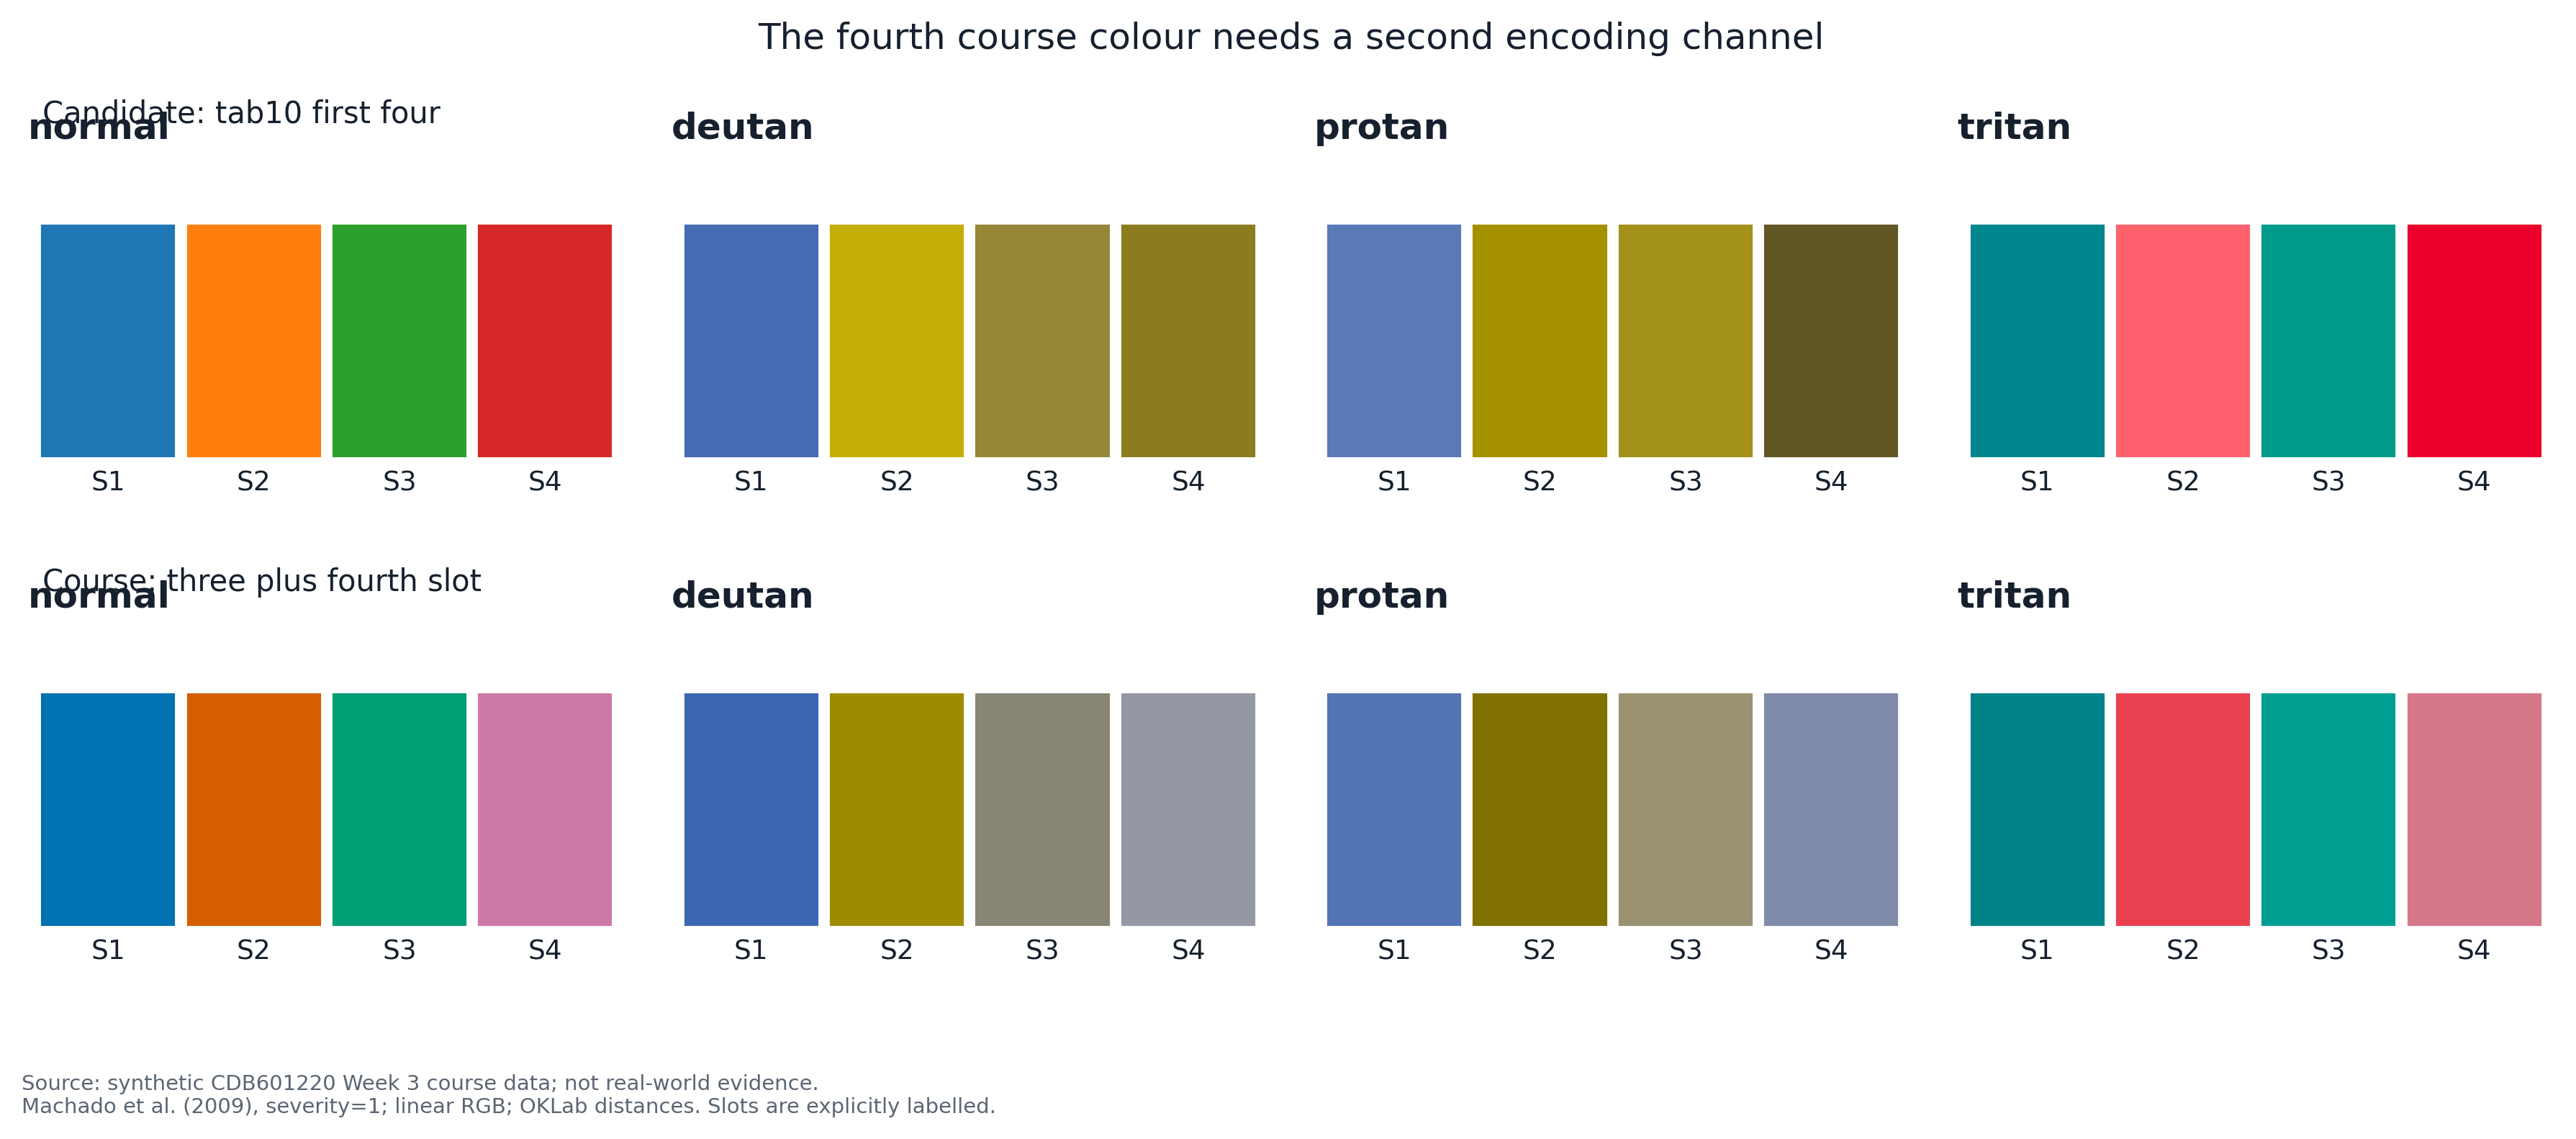

In [7]:
display(Image(filename=str(OUT / 'partC_palette.png'), width=1100))

## Part D - Inspect first, clean explicitly, build the 2 x 2 figure

The first four inspection calls occur in the required order. Corrections retain every patient row and invalidate only faulty cells. Two zero-day stays are omitted only from the logarithmic box plot. The original mixed-format date and ward columns remain for audit.

The heatmap excludes MAP, patient identifiers, category codes and the risk ratio. It uses nine measured quantities and pairwise-complete Pearson correlation. A saved sample-size matrix accompanies it. The strongest remaining pair is systolic/diastolic pressure; age/cholesterol is weaker and is acknowledged. Neither is described as proof of causation.

The wide LOS file is melted and validated against the ward counts/medians of the ID-linked source. Padding blanks are not patients. Appendix figures explicitly show what the HR/BMI exclusions change.

In [8]:
from common import *
import json
COLS=['age','systolic','diastolic','heart_rate','spo2','bmi','chol_mmol_l','glucose_mmol_l','los_days']
LABELS=['Age','SBP','DBP','HR','SpO2','BMI','Chol','Glucose','LOS']
WARD_MAP={'general medicine':'General Medicine','gen medicine':'General Medicine','cardiology':'Cardiology','cardio':'Cardiology','day surgery':'Day Surgery','day-surgery':'Day Surgery','intensive care':'ICU','icu':'ICU','i.c.u':'ICU'}
def inspect(df):
    df.info()
    print(df.describe().T)
    print(df.ward.value_counts())
    print(df.admit_date.head(20).tolist())
def clean(raw):
    d=raw.copy();log=[]
    def entry(rule,count,before,after):log.append({'rule':rule,'count':int(count),'before':str(before),'after':str(after)})
    d['ward_clean']=d.ward.str.strip().str.lower().map(WARD_MAP);assert d.ward_clean.notna().all() and d.ward_clean.nunique()==4
    entry('Normalize whitespace/case and explicit ward aliases; no rows removed',sum(d.ward!=d.ward_clean),raw.ward.nunique(),d.ward_clean.nunique())
    dt=pd.Series(pd.NaT,index=d.index,dtype='datetime64[ns]')
    for fmt in ['%Y-%m-%d','%d/%m/%Y','%d-%b-%Y']:dt=dt.fillna(pd.to_datetime(d.admit_date,format=fmt,errors='coerce'))
    d['admit_dt']=dt;assert dt.notna().all();entry('Parse ISO, day/month/year and day-abbreviated-month-year explicitly',len(d),'10000 text dates',f'{dt.notna().sum()} valid datetimes; 0 failures')
    bad_bmi=d.bmi.isin([0,999]);before=d.bmi.mean();d.loc[bad_bmi,'bmi']=np.nan
    entry('BMI 0 or 999 are missing-value sentinels; invalidate cells, retain rows',sum(bad_bmi),f'mean {before:.5f} kg/m2',f'mean {d.bmi.mean():.5f} kg/m2')
    bad_hr=(d.heart_rate==0)|(d.heart_rate>250);before=d.heart_rate.mean();d.loc[bad_hr,'heart_rate']=np.nan
    entry('HR >250 device faults (29) or 0 no valid resting reading (8); invalidate cells, retain other measurements',sum(bad_hr),f'mean {before:.5f} bpm',f'mean {d.heart_rate.mean():.5f} bpm')
    entry('Exclude derived MAP from inferential heatmap; no rows removed',0,f'max formula rounding error {np.abs(d.map_mmhg-(d.systolic+2*d.diastolic)/3).max():.4f} mmHg','9 independently recorded numeric measures in heatmap')
    zero=d.los_days==0;entry('Zero-day stays retained as possible same-day stays; omit only from log-LOS box plot',sum(zero),f'mean LOS {d.los_days.mean():.6f}',f'positive-only mean LOS {d.loc[~zero,"los_days"].mean():.6f}')
    entry('Retain long stays; do not hide fliers; do not impose normality',0,f'LOS skewness {d.los_days.skew():.3f}',f'LOS median {d.los_days.median():.3f}; max {d.los_days.max():.2f}')
    entry('SpO2 empirical bounded support; no ordinary unbounded KDE',0,f'max {d.spo2.max()}%',f'{sum(d.spo2>100)} readings above 100%')
    entry('Systolic bimodality inspected with 3,45,400 bins; use 5 mmHg width',0,'range 92-199 mmHg','all 10000 observations retained')
    # Rounded risk_score does not provide exact event numerator; do not invent it.
    approx=(d.risk_score*d.los_days).sum()/d.los_days.sum()
    entry('Risk is a per-row ratio; exclude it from heatmap and do not call its mean an overall event rate',0,f'unweighted mean {d.risk_score.mean():.6f}',f'LOS-weighted approximation {approx:.6f} events/day; exact numerator unavailable')
    entry('Duplicate IDs and missingness checked; no whole rows deleted',0,f'duplicate IDs {d.patient_id.duplicated().sum()}',f'{len(d)} rows retained; BMI invalid {bad_bmi.sum()}, HR invalid {bad_hr.sum()}')
    t=pd.DataFrame(log);t.to_csv(ROOT/'outputs'/'cleaning_log.csv',index=False);print(t.to_string(index=False));return d,t

def build_figure(d,name='partD_figure',sensitivity=False):
    corr=d[COLS].corr(method='pearson',min_periods=3)
    ranked=corr.where(np.tril(np.ones_like(corr,dtype=bool),-1)).stack().abs().sort_values(ascending=False)
    y,x=ranked.index[0];r=corr.loc[x,y]
    fig,axes=plt.subplots(2,2,figsize=(15,11))
    ax=axes[0,0];ax.hist(d.systolic,bins=np.arange(90,206,5),color=C[0],edgecolor='white');ax.set(title='Systolic pressure contains two visible modes',xlabel='Systolic blood pressure (mmHg)',ylabel='Records');ax.text(.03,.93,'Bin width = 5 mmHg; n = 10,000',transform=ax.transAxes,va='top',fontsize=9)
    positive=d[d.los_days>0];order=positive.groupby('ward_clean').los_days.median().sort_values().index.tolist()
    ax=axes[0,1];sns.boxplot(data=positive,x='ward_clean',y='los_days',order=order,color=C[0],showfliers=True,whis=1.5,width=.6,fliersize=2,linewidth=1,ax=ax);ax.set_yscale('log');ax.set(title='ICU stays are longest; long-stay outliers remain visible',xlabel='Ward (ordered by median)',ylabel='Length of stay (days; log scale)');ax.tick_params(axis='x',labelsize=8)
    # One common colour and explicit positions avoid requiring four distinguishable colours.
    for i,w in enumerate(order):ax.text(i,.99,f'median {positive.loc[positive.ward_clean==w,"los_days"].median():.2f}',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=8)
    ax=axes[1,0];pairs=d[[x,y]].dropna();sample=pairs.sample(n=min(2000,len(pairs)),random_state=220)
    ax.scatter(sample[x],sample[y],s=10,alpha=.18,color=C[0],edgecolors='none');units={'systolic':'Systolic blood pressure (mmHg)','diastolic':'Diastolic blood pressure (mmHg)'}
    ax.set(title=f'Independent BP readings track together: r = {r:.2f}',xlabel=units.get(x,x),ylabel=units.get(y,y));ax.text(.03,.95,'2,000 points; seed=220; alpha=.18\nr uses all valid pairs',transform=ax.transAxes,va='top',fontsize=9)
    ax=axes[1,1];mask=np.triu(np.ones_like(corr,dtype=bool),k=0);sns.heatmap(corr,mask=mask,cmap='RdBu_r',vmin=-1,vmax=1,center=0,annot=True,fmt='.2f',xticklabels=LABELS,yticklabels=LABELS,annot_kws={'fontsize':8},linewidths=.3,cbar_kws={'label':'Pearson r','shrink':.8},ax=ax);ax.set_title('BP has the strongest independent pair; age-cholesterol is weaker');ax.tick_params(axis='x',rotation=45);ax.tick_params(axis='y',rotation=0)
    fig.suptitle('Clinical review: pressure subgroups and long stays require separate attention'+(' | no HR/BMI exclusions' if sensitivity else ''),fontsize=14)
    note='10,000 records retained. Primary: 486 BMI sentinel cells and 37 HR fault cells set missing; pairwise-complete correlation.\nLog LOS omits 2 zero-day records only; 9,998 positive stays, fliers shown. No MAP/risk-score correlation. Histogram width=5; scatter n=2,000, seed=220, alpha=.18.\nHeatmap: lower triangle, RdBu_r [-1,1], center=0; Pearson r; 300 dpi. '+('Sensitivity uses original HR/BMI cells.' if sensitivity else 'All other measurements retained.')
    finish(fig,name,note)
    corr.to_csv(ROOT/'outputs'/f'{name}_correlation.csv')
    # Pairwise denominators are explicit, rather than one misleading n for the whole matrix.
    valid=d[COLS].notna().astype(int);(valid.T@valid).to_csv(ROOT/'outputs'/f'{name}_pairwise_n.csv')
    return corr

def main():
    raw=read('vitals_10k');inspect(raw);d,log=clean(raw)
    d.to_csv(ROOT/'outputs'/'vitals_cleaned.csv',index=False)
    wide=read('ward_los_wide');long=wide.melt(var_name='ward',value_name='los_days');padding=long.los_days.isna().sum();long=long.dropna(subset=['los_days']);long['ward']=long.ward.replace({'Icu':'ICU'});long.to_csv(ROOT/'outputs'/'ward_los_long.csv',index=False)
    assert len(long)==10000
    print(f'Wide LOS: {len(wide)*len(wide.columns)} cells, {padding} padding blanks omitted by melt/dropna; {len(long)} observations. No patient observations lost.')
    # Wide export has no IDs; primary ward panel uses the ID-linked vitals source.
    check1=long.groupby('ward').los_days.agg(['count','median']);check2=d.groupby('ward_clean').los_days.agg(['count','median']);assert np.allclose(check1.sort_index(),check2.sort_index())
    check1.to_csv(ROOT/'outputs'/'ward_los_melt_check.csv');corr=build_figure(d)
    sensitivity=d.copy();sensitivity['heart_rate']=raw.heart_rate;sensitivity['bmi']=raw.bmi;build_figure(sensitivity,'partD_without_exclusion',True)
    fig,axes=plt.subplots(1,2,figsize=(10,4));bins=np.arange(0,441,10)
    axes[0].hist(raw.heart_rate,bins=bins,color=C[1]);axes[0].set(title='All readings include device faults',xlabel='Heart rate (bpm)',ylabel='Records');axes[1].hist(d.heart_rate.dropna(),bins=bins,color=C[0]);axes[1].set(title='37 invalid readings excluded explicitly',xlabel='Heart rate (bpm)',ylabel='Records');finish(fig,'partD_HR_exclusion_sensitivity','Before n=10000, mean=78.8331; after n=9963, mean=78.0469. Shared 0..440 edges, width=10 bpm. No hidden fliers.')
    skew=d[COLS].skew();skew.to_csv(ROOT/'outputs'/'skewness.csv');print('Skewness (non-normality screen, not proof):\n',skew)
    print('Strongest non-derived pair: systolic/diastolic',corr.loc['systolic','diastolic'],'; age/cholesterol',corr.loc['age','chol_mmol_l'])
    return d,log
if __name__=='__main__':main()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  object 
 1   admit_date      10000 non-null  object 
 2   ward            10000 non-null  object 
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  object 
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), object(4)
memory usage: 1.2+ MB
                  co

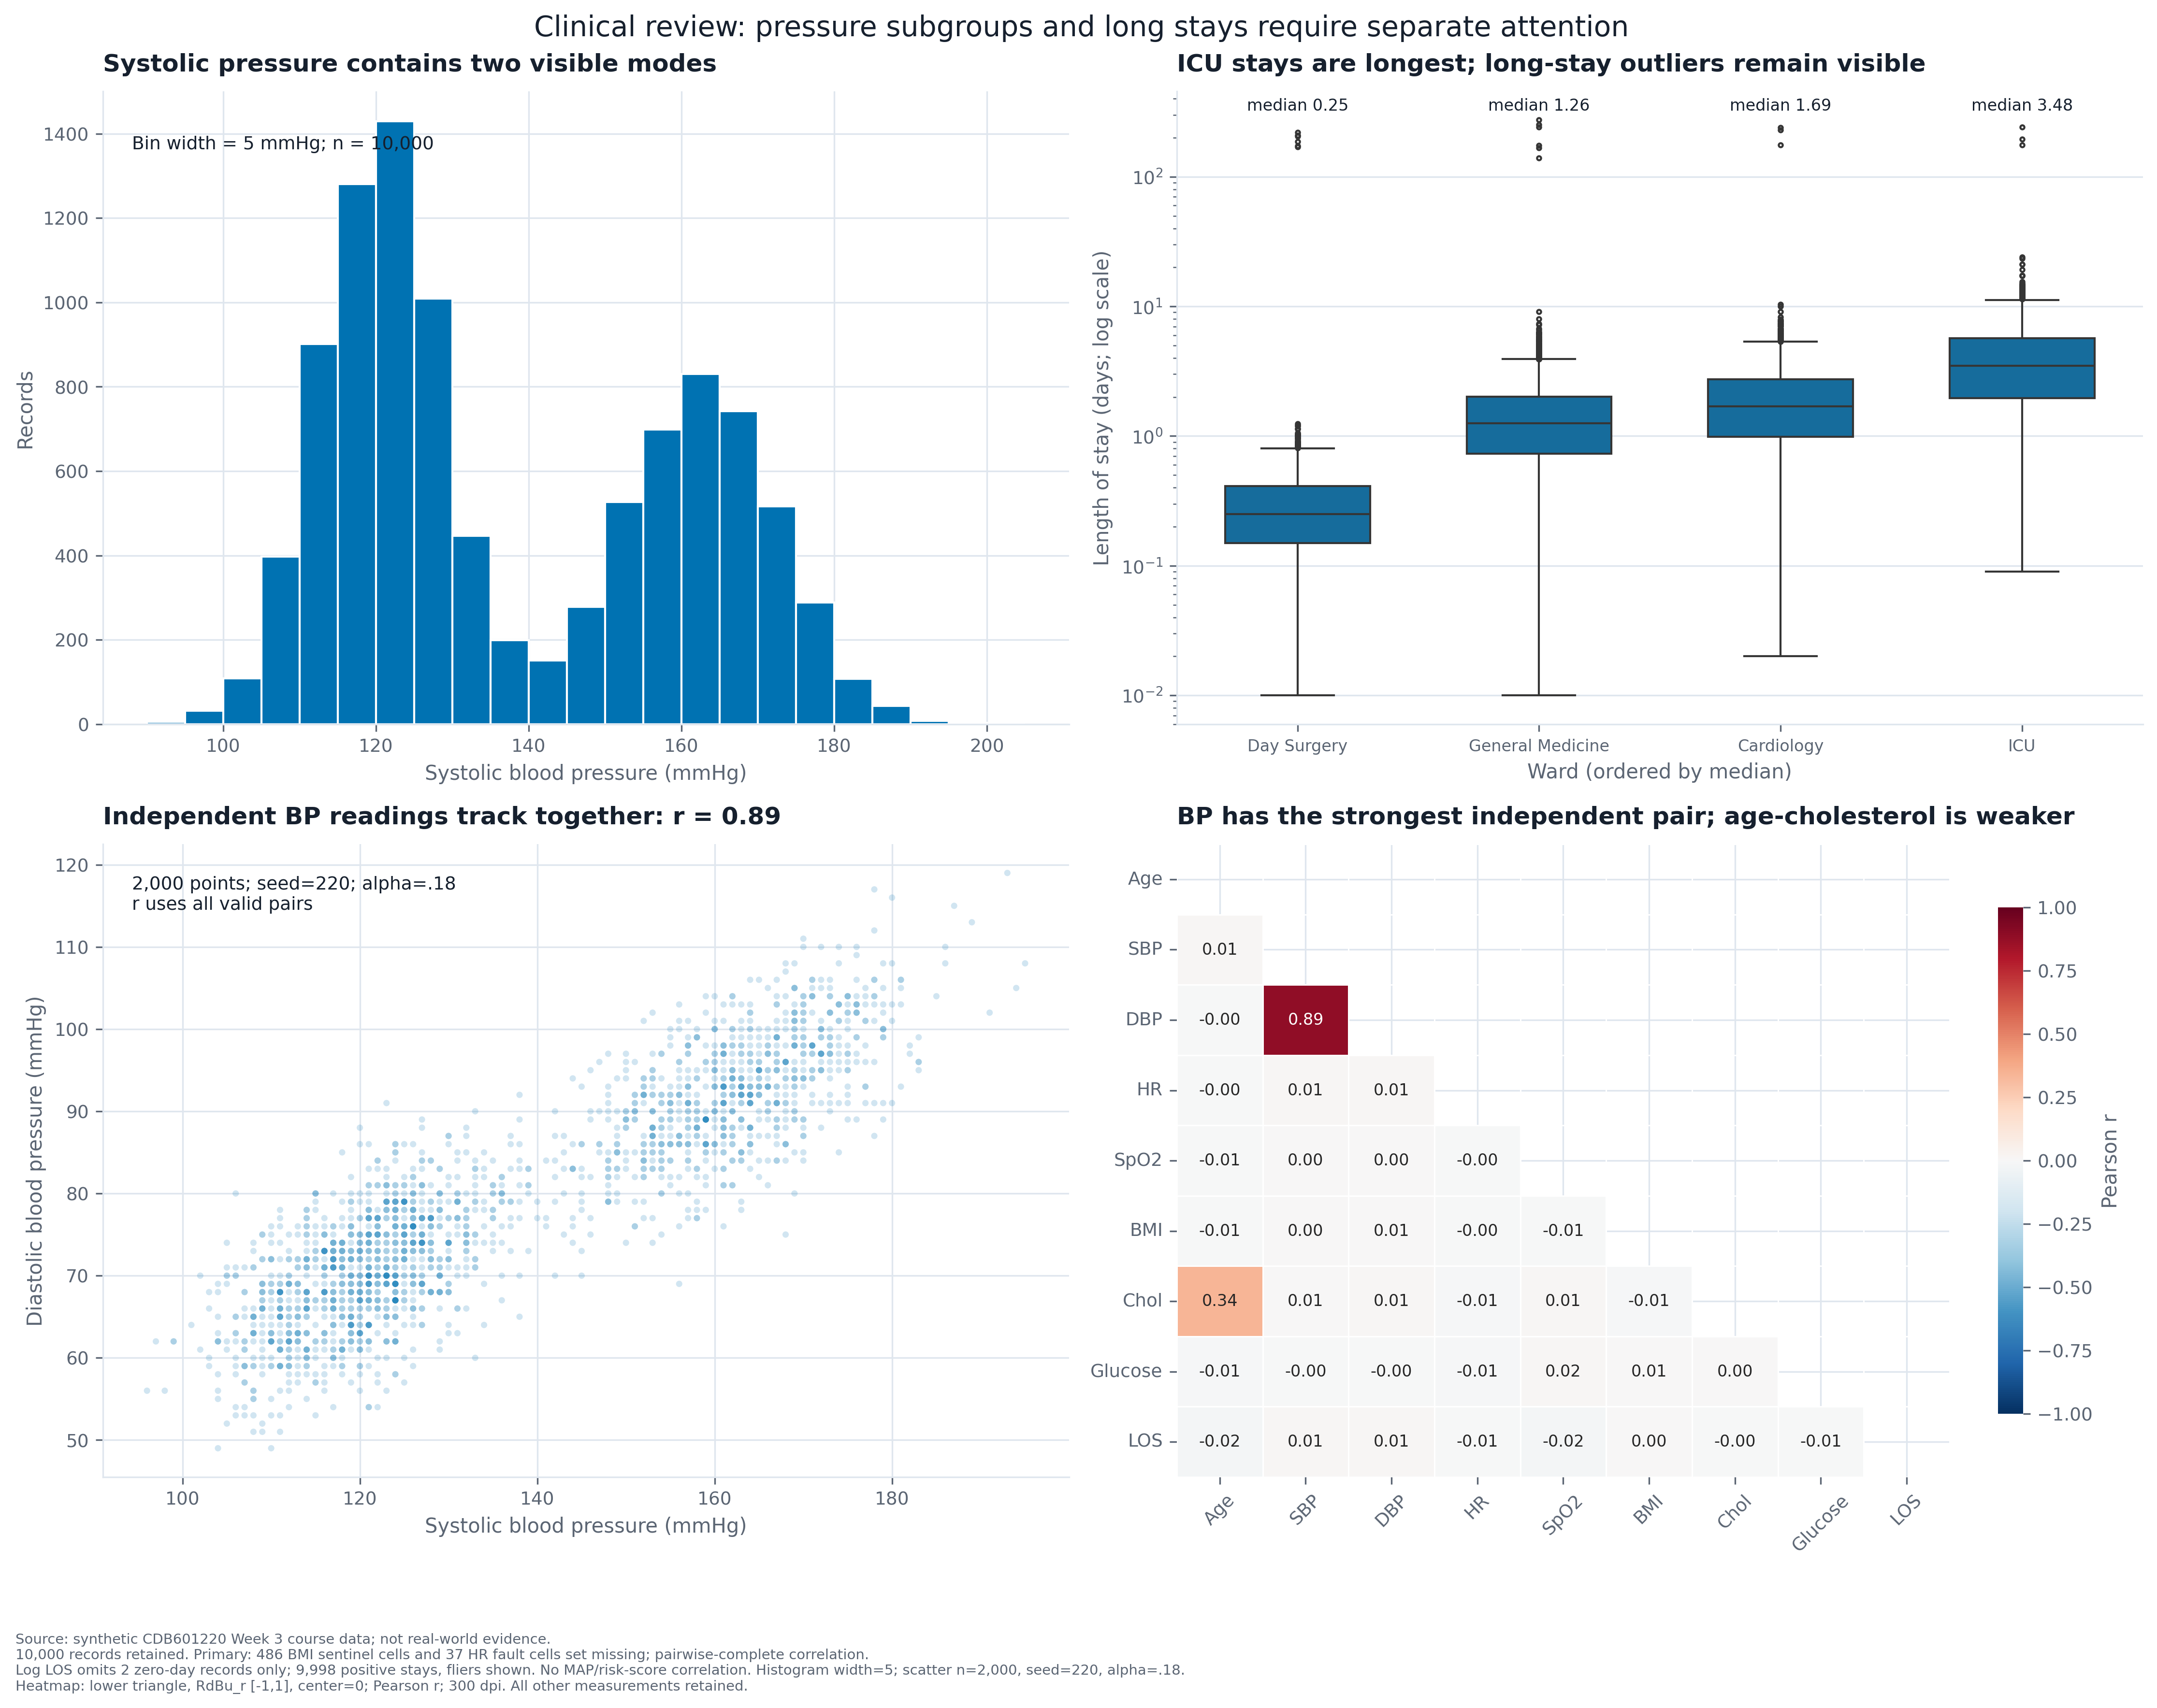

### Appendix: same clinical figure without HR/BMI exclusions

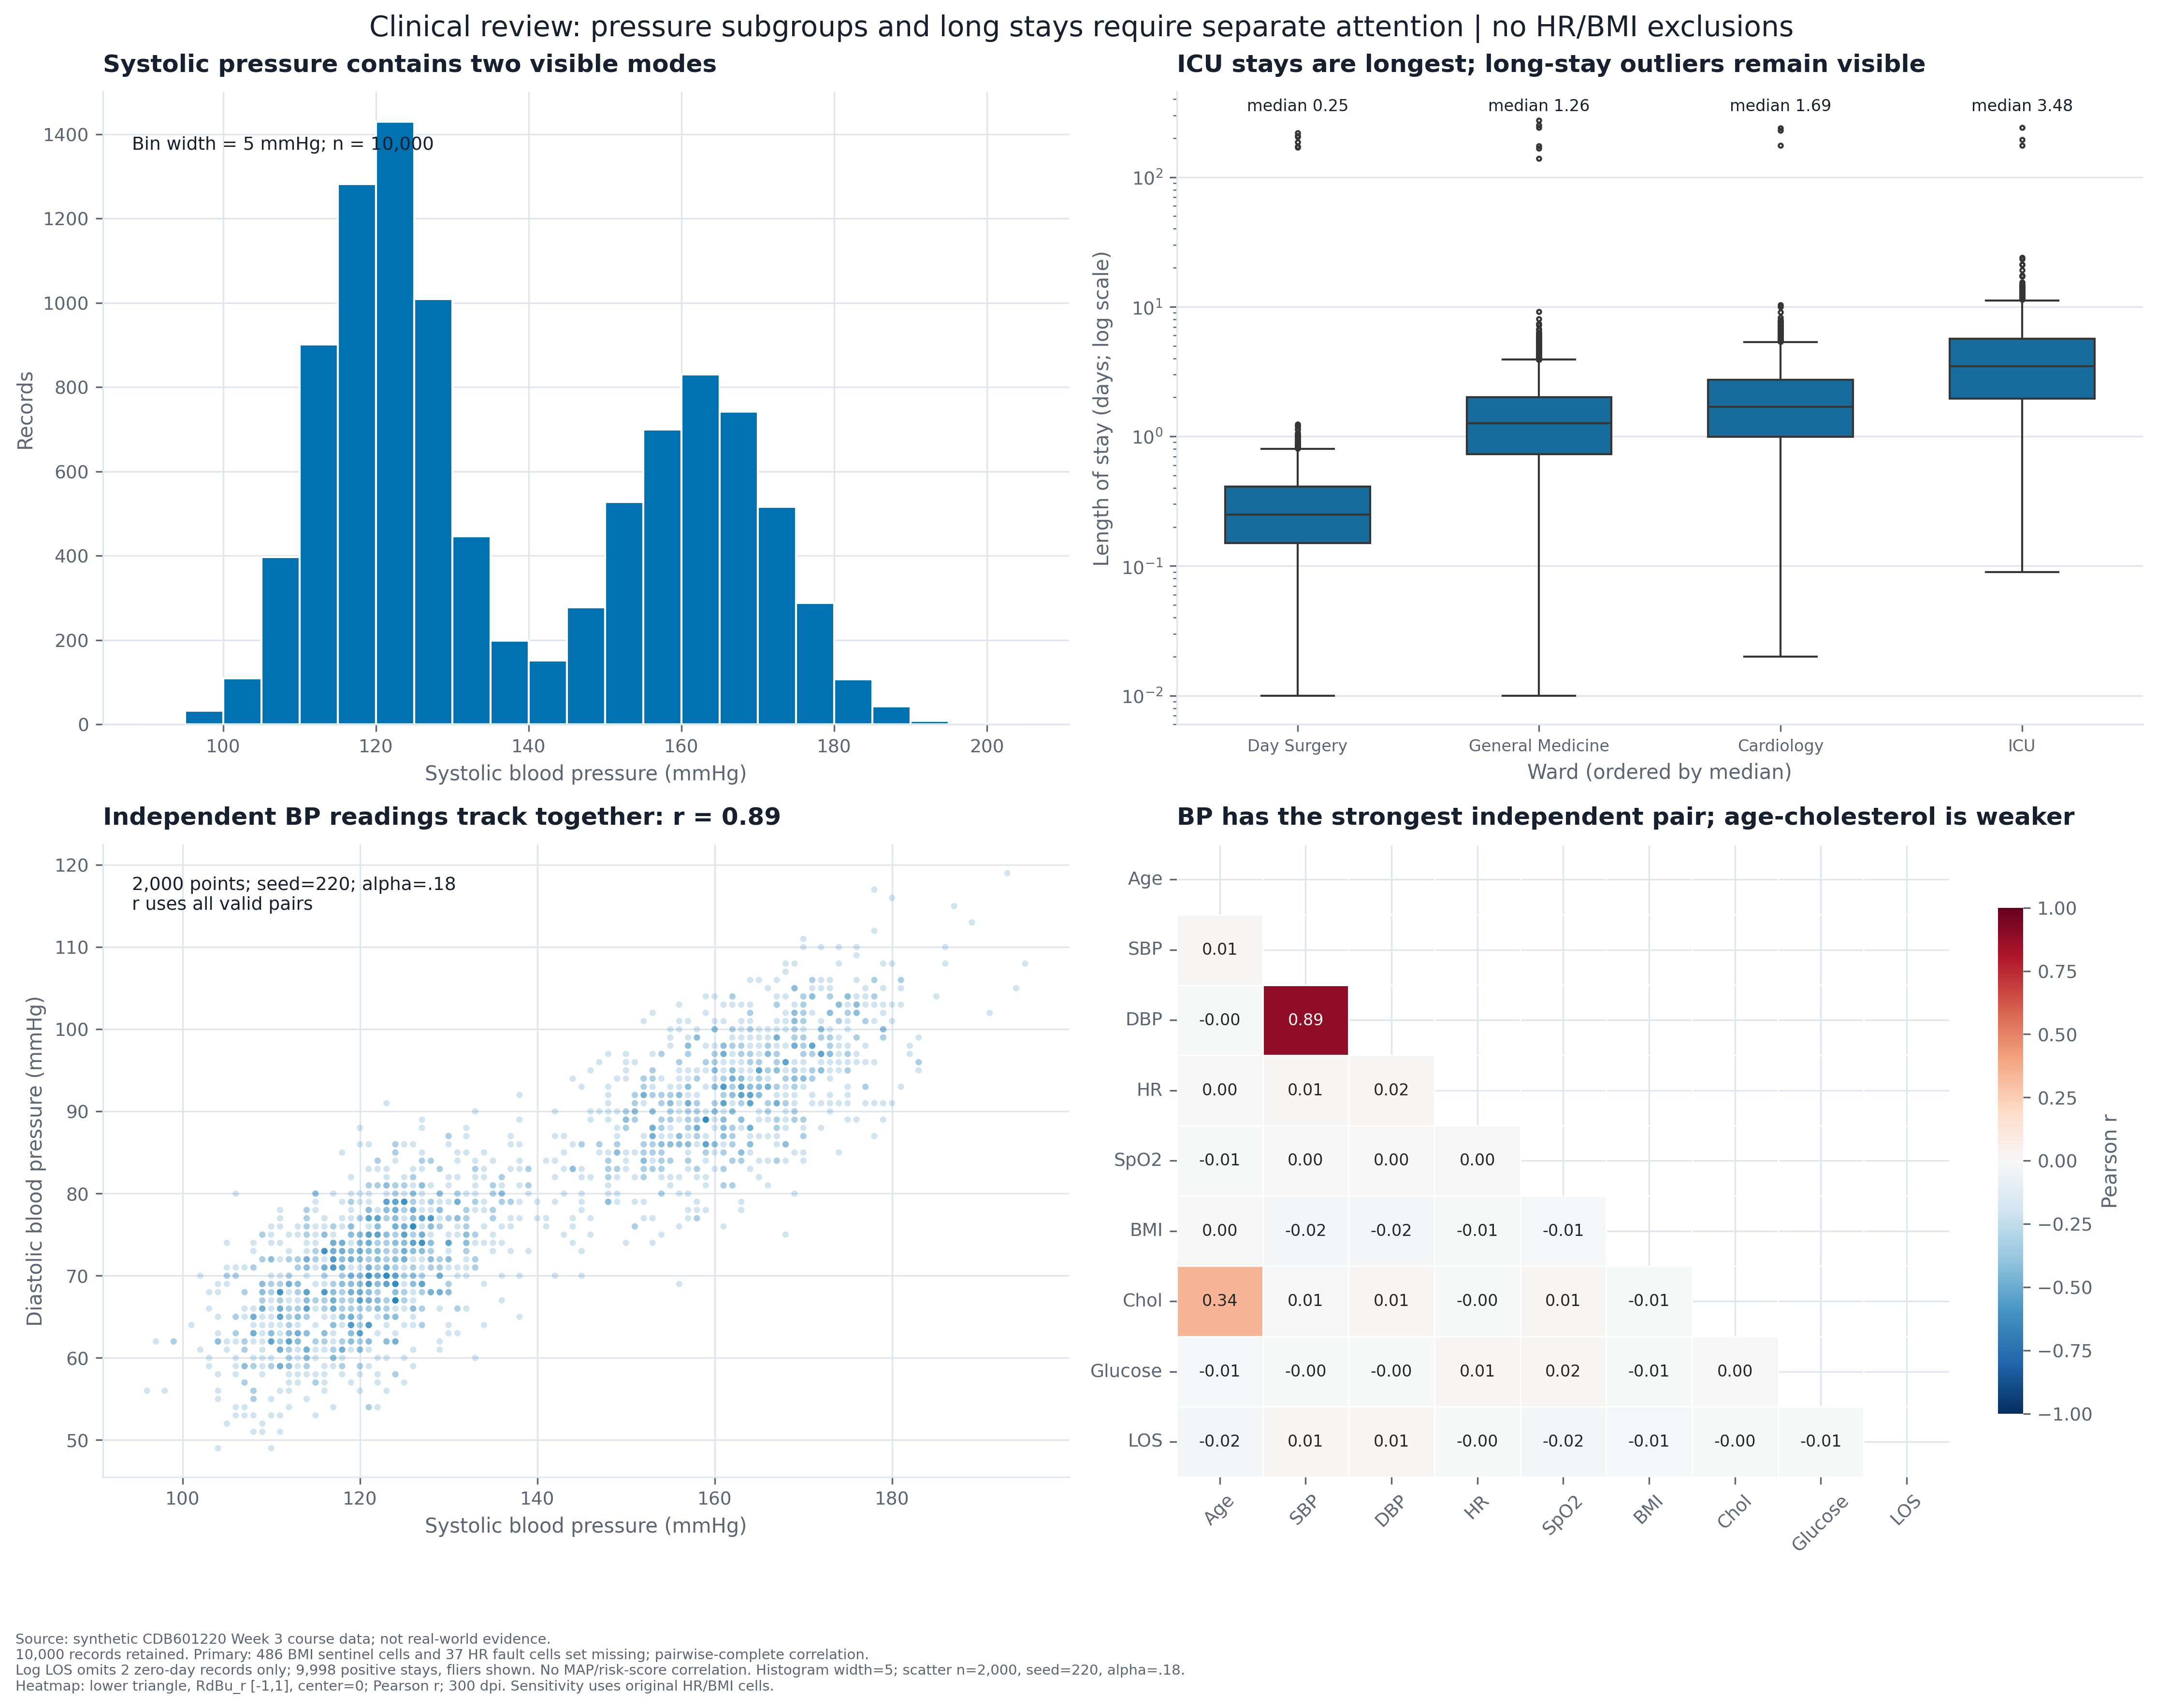

### Appendix: heart-rate exclusion sensitivity on common scales

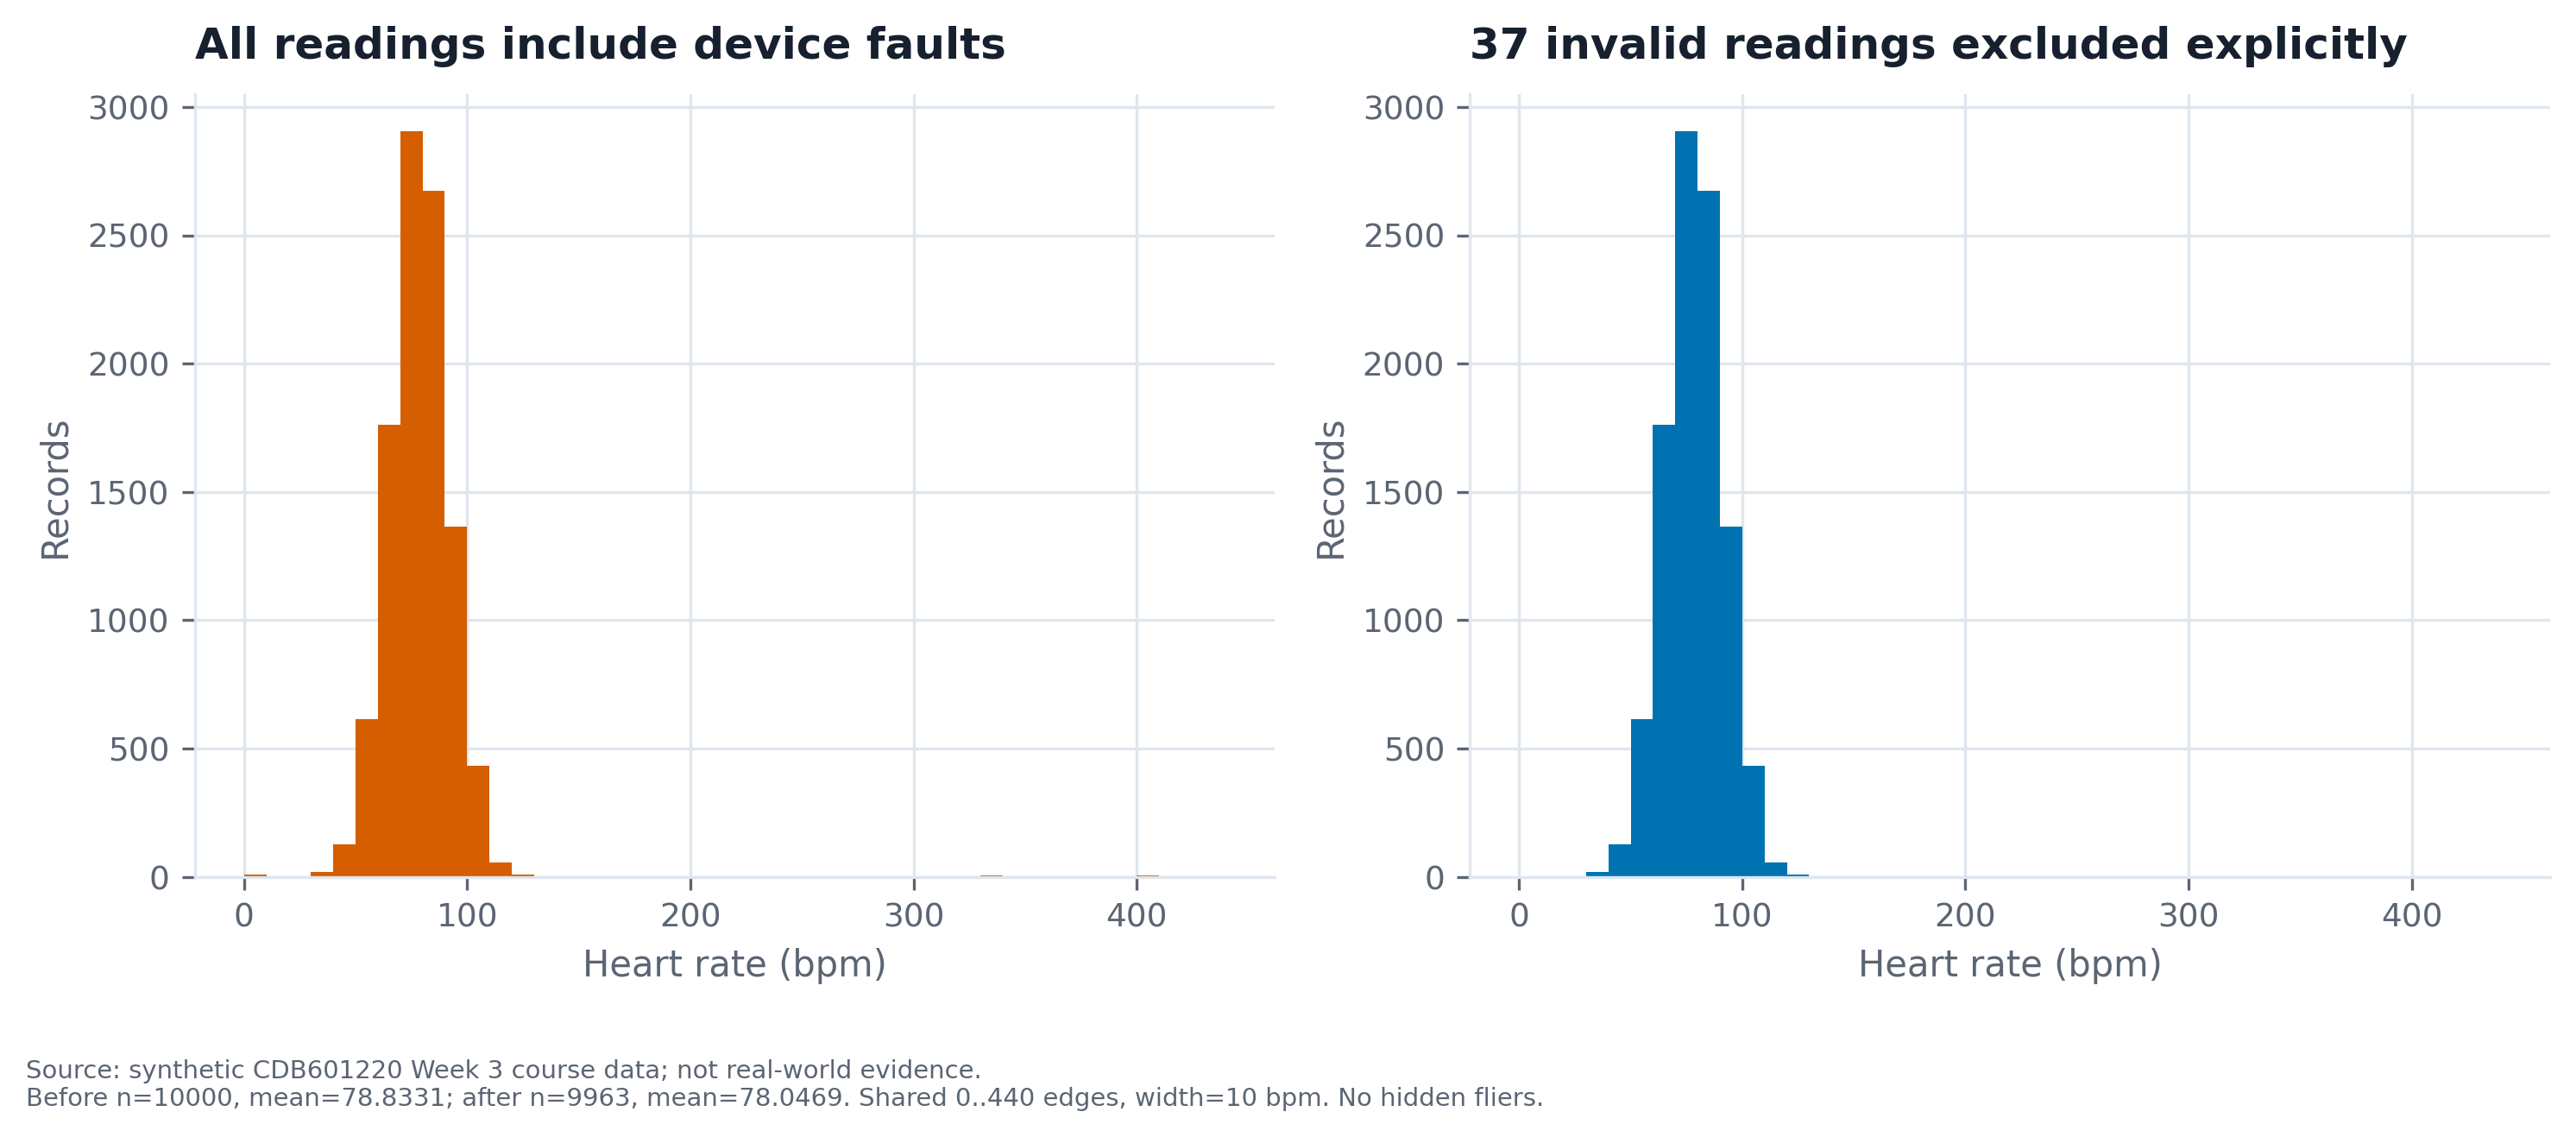

,rule,count,before,after
0,Normalize whitespace/case and explicit ward al...,6533,12,4
1,"Parse ISO, day/month/year and day-abbreviated-...",10000,10000 text dates,10000 valid datetimes; 0 failures
2,BMI 0 or 999 are missing-value sentinels; inva...,486,mean 66.17704 kg/m2,mean 27.34627 kg/m2
3,HR >250 device faults (29) or 0 no valid resti...,37,mean 78.83310 bpm,mean 78.04687 bpm
4,Exclude derived MAP from inferential heatmap; ...,0,max formula rounding error 0.0333 mmHg,9 independently recorded numeric measures in h...
5,Zero-day stays retained as possible same-day s...,2,mean LOS 2.309091,positive-only mean LOS 2.309553
6,Retain long stays; do not hide fliers; do not ...,0,LOS skewness 22.755,LOS median 1.380; max 273.65
7,SpO2 empirical bounded support; no ordinary un...,0,max 100%,0 readings above 100%
8,"Systolic bimodality inspected with 3,45,400 bi...",0,range 92-199 mmHg,all 10000 observations retained
9,Risk is a per-row ratio; exclude it from heatm...,0,unweighted mean 1.120877,LOS-weighted approximation 0.654373 events/day...


In [9]:
display(Image(filename=str(OUT / 'partD_figure.png'), width=1100))
display(Markdown('### Appendix: same clinical figure without HR/BMI exclusions'))
display(Image(filename=str(OUT / 'partD_without_exclusion.png'), width=1100))
display(Markdown('### Appendix: heart-rate exclusion sensitivity on common scales'))
display(Image(filename=str(OUT / 'partD_HR_exclusion_sensitivity.png'), width=1000))
display(pd.read_csv(ROOT / 'outputs' / 'cleaning_log.csv'))

## Part E - One-page written justification

The following reproducible report code generates the diagnosis PDF and the **one-page** justification PDF. All rules, parameters, before/after means, counts and the symmetry test are included. These PDFs accompany the notebook in the ZIP.

In [10]:
from pathlib import Path
import json
import pandas as pd
from PIL import Image as PILImage
from reportlab.platypus import SimpleDocTemplate,Paragraph,Spacer,Image,PageBreak,KeepTogether
from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4
from xml.sax.saxutils import escape
ROOT=BASE
styles=getSampleStyleSheet()
styles.add(ParagraphStyle(name='BodyCustom',fontName='Helvetica',fontSize=9,leading=12,spaceAfter=6,textColor=colors.HexColor('#16202E')))
styles.add(ParagraphStyle(name='SmallCustom',fontName='Helvetica',fontSize=8,leading=10,spaceAfter=4))
def para(s,style='BodyCustom'):return Paragraph(escape(s),styles[style])
def pic(path,maxw=6.7*inch,maxh=2.3*inch):
    w,h=PILImage.open(path).size;k=min(maxw/w,maxh/h);return Image(str(path),width=w*k,height=h*k)
def footer(canvas,doc):
    canvas.setFont('Helvetica',7);canvas.setFillColor(colors.HexColor('#5B6573'));canvas.drawString(35,20,'CDB601220 | Week 3 | All analysed data are synthetic course datasets');canvas.drawRightString(A4[0]-35,20,str(doc.page))
def main():
    diagnoses=json.loads((ROOT/'outputs'/'partA_diagnoses.json').read_text());story=[]
    for row in diagnoses:
        k=row['case'];story.append(para(f"Case {k}: {row['title']}",'Heading2'))
        for field in ['conclusion','decoy','mechanism','redesign']:story.append(para(field.title()+': '+row[field]))
        if k==6:
            story.append(para('Redesign and disclosed influence sensitivity','SmallCustom'));story.append(pic(ROOT/'figures'/f'A{k:02d}_redesign.png',maxh=2.8*inch));story.append(PageBreak());story.append(para('Case 6: required original 20 x 20 matrix','Heading2'));story.append(pic(ROOT/'figures'/f'A{k:02d}_original.png',maxh=8.6*inch))
        else:
            story.append(para('Required reconstruction (or summary table)','SmallCustom'));story.append(pic(ROOT/'figures'/f'A{k:02d}_original.png'));story.append(Spacer(1,5));story.append(para('Honest redesign','SmallCustom'));story.append(pic(ROOT/'figures'/f'A{k:02d}_redesign.png'))
        if k!=9:story.append(PageBreak())
    SimpleDocTemplate(str(ROOT/'partA_diagnosis.pdf'),pagesize=A4,rightMargin=35,leftMargin=35,topMargin=28,bottomMargin=32).build(story,onFirstPage=footer,onLaterPages=footer)
    log=pd.read_csv(ROOT/'outputs'/'cleaning_log.csv');skew=pd.read_csv(ROOT/'outputs'/'skewness.csv',index_col=0)
    text=[
      ('Part E - Clinical figure justification','Heading2'),
      ('Panel 1 asks whether systolic pressure has one population or multiple modes. A 5 mmHg histogram exposes two modes; aligned position and bar length encode quantitative counts on a common zero baseline. I compared 3, 45 and 400 bins first. Bin edges 90-205 cover every value (n=10,000); the two-mode shape is not evidence identifying a specific clinical subgroup.','BodyCustom'),
      ('Panel 2 asks which wards have longer and more variable stays. A box plot compares median, IQR and tails. Ward order is ascending median; all four use the same blue because labelled positions identify category. Log10 y preserves the 273.65-day maximum while separating typical stays (overall median 1.38 days; skewness 22.755). Whiskers=1.5 IQR, width=.6, linewidth=1, fliersize=2; showfliers=True retains unusual observations.','BodyCustom'),
      ('Panel 3 asks how the strongest independently recorded pair behaves. Panel 4 screens all nine measurements: systolic/diastolic is strongest after excluding derived MAP. Scatter uses aligned x/y position, not area, to show association; it is not a novel causal discovery. A uniform sample of 2,000 valid pairs, seed=220, size=10 points squared, alpha=.18 and no point edges controls overlap. Pearson r uses all valid pairs. Age/cholesterol is a weaker additional association.','BodyCustom'),
      ('Panel 4 asks which independently recorded indicators correlate. Pearson correlation uses pairwise-complete data (minimum 3 pairs); sample-size matrix is exported. Lower triangle excludes diagonal and duplication; RdBu_r, vmin=-1, vmax=1 and center=0 preserve sign and comparability. Two-decimal annotations provide exact readings; cell linewidth=.3 and colourbar shrink=.8 improve legibility. MAP is arithmetic, and risk_score is a ratio, so neither enters the matrix.','BodyCustom'),
      ('Cleaning and exclusions: all 10,000 patient rows remain. Normalize 12 ward spellings to 4 (6,533 labels changed); parse three explicit date formats, including day-first slashes (10,000 successful; 0 failures). BMI 0 (84) and 999 (402) are missing sentinels: 486 cells set missing; mean 66.17704 to 27.34627 kg/m2. Heart-rate readings above 250 bpm were excluded as device faults (n=29), plus 8 zero readings invalidated. Mean HR moves from 78.83310 to 78.04687 bpm (n=9,963). The figure was also produced without the HR/BMI exclusions; it and the shared-scale HR sensitivity histogram are in the appendix.','BodyCustom'),
      ('Two zero-day LOS rows are omitted only from the log box plot (10,000 to 9,998; mean 2.309091 to 2.309553 days). Possible same-day stays and every long stay remain in the source and other analyses; no arbitrary upper LOS cutoff is imposed. Wide LOS is melted: 6,072 padding cells, not patient records, are omitted; 10,000 observations match ID-linked ward medians/counts. No other rows are deleted. The Scott SpO2 KDE leaks beyond 100%, so bounded empirical probabilities are used in Part A; vitals normality is not assumed.','BodyCustom'),
      ('Risk-score mean 1.120877 is not an aggregate event rate. Weighting by LOS gives only an approximation (.654373 events/day) because the exact event numerator is absent and the supplied ratio is rounded; no exact rate is claimed. These choices precede outcome interpretation and would remain if they weakened the finding (symmetry test). Figure: 15 x 11 inches, font DejaVu Sans, message titles, labelled units, top/right spines removed, tight layout, white background, 300 dpi and tight bounding box; source and sample rules accompany the export.','BodyCustom'),
      ('Source: supplied DATA_DICTIONARY.md, TASKS.md and vizlib.py; synthetic CDB601220 Week 3 data. No patient-risk prediction or real-world policy conclusion is claimed.','SmallCustom')]
    (ROOT/'outputs'/'partE_justification.txt').write_text('\n\n'.join(s for s,_ in text))
    SimpleDocTemplate(str(ROOT/'partE_justification.pdf'),pagesize=A4,rightMargin=35,leftMargin=35,topMargin=28,bottomMargin=30).build([para(s,st) for s,st in text],onFirstPage=footer,onLaterPages=footer)
if __name__=='__main__':main()


In [11]:
display(Markdown((ROOT / 'outputs' / 'partE_justification.txt').read_text()))
import shutil
for name in ['partC_palette','partD_figure']:
    shutil.copy2(OUT / f'{name}.png', ROOT / f'{name}.png')

Part E - Clinical figure justification

Panel 1 asks whether systolic pressure has one population or multiple modes. A 5 mmHg histogram exposes two modes; aligned position and bar length encode quantitative counts on a common zero baseline. I compared 3, 45 and 400 bins first. Bin edges 90-205 cover every value (n=10,000); the two-mode shape is not evidence identifying a specific clinical subgroup.

Panel 2 asks which wards have longer and more variable stays. A box plot compares median, IQR and tails. Ward order is ascending median; all four use the same blue because labelled positions identify category. Log10 y preserves the 273.65-day maximum while separating typical stays (overall median 1.38 days; skewness 22.755). Whiskers=1.5 IQR, width=.6, linewidth=1, fliersize=2; showfliers=True retains unusual observations.

Panel 3 asks how the strongest independently recorded pair behaves. Panel 4 screens all nine measurements: systolic/diastolic is strongest after excluding derived MAP. Scatter uses aligned x/y position, not area, to show association; it is not a novel causal discovery. A uniform sample of 2,000 valid pairs, seed=220, size=10 points squared, alpha=.18 and no point edges controls overlap. Pearson r uses all valid pairs. Age/cholesterol is a weaker additional association.

Panel 4 asks which independently recorded indicators correlate. Pearson correlation uses pairwise-complete data (minimum 3 pairs); sample-size matrix is exported. Lower triangle excludes diagonal and duplication; RdBu_r, vmin=-1, vmax=1 and center=0 preserve sign and comparability. Two-decimal annotations provide exact readings; cell linewidth=.3 and colourbar shrink=.8 improve legibility. MAP is arithmetic, and risk_score is a ratio, so neither enters the matrix.

Cleaning and exclusions: all 10,000 patient rows remain. Normalize 12 ward spellings to 4 (6,533 labels changed); parse three explicit date formats, including day-first slashes (10,000 successful; 0 failures). BMI 0 (84) and 999 (402) are missing sentinels: 486 cells set missing; mean 66.17704 to 27.34627 kg/m2. Heart-rate readings above 250 bpm were excluded as device faults (n=29), plus 8 zero readings invalidated. Mean HR moves from 78.83310 to 78.04687 bpm (n=9,963). The figure was also produced without the HR/BMI exclusions; it and the shared-scale HR sensitivity histogram are in the appendix.

Two zero-day LOS rows are omitted only from the log box plot (10,000 to 9,998; mean 2.309091 to 2.309553 days). Possible same-day stays and every long stay remain in the source and other analyses; no arbitrary upper LOS cutoff is imposed. Wide LOS is melted: 6,072 padding cells, not patient records, are omitted; 10,000 observations match ID-linked ward medians/counts. No other rows are deleted. The Scott SpO2 KDE leaks beyond 100%, so bounded empirical probabilities are used in Part A; vitals normality is not assumed.

Risk-score mean 1.120877 is not an aggregate event rate. Weighting by LOS gives only an approximation (.654373 events/day) because the exact event numerator is absent and the supplied ratio is rounded; no exact rate is claimed. These choices precede outcome interpretation and would remain if they weakened the finding (symmetry test). Figure: 15 x 11 inches, font DejaVu Sans, message titles, labelled units, top/right spines removed, tight layout, white background, 300 dpi and tight bounding box; source and sample rules accompany the export.

Source: supplied DATA_DICTIONARY.md, TASKS.md and vizlib.py; synthetic CDB601220 Week 3 data. No patient-risk prediction or real-world policy conclusion is claimed.

## Final verification and sources

Actual sources: supplied `TASKS.md`, `data/DATA_DICTIONARY.md`, CSV data, `vizlib.py` and starter code. Toolkit provenance: Machado et al. (2009) simulation matrices and OKLab colour distances; Anscombe (1973) and Matejka & Fitzmaurice (2017) are named by the assignment for the summary-statistics cases. No external data or invented bonus results are used.

In [12]:
import json
import pandas as pd
from pypdf import PdfReader
assert len(json.loads((ROOT/'outputs'/'partA_diagnoses.json').read_text())) == 9
assert len(pd.read_csv(ROOT/'outputs'/'vitals_cleaned.csv')) == 10000
assert len(pd.read_csv(ROOT/'outputs'/'ward_los_long.csv')) == 10000
assert len(PdfReader(ROOT/'partE_justification.pdf').pages) == 1
assert pd.read_csv(ROOT/'outputs'/'partB_results.csv').query("verdict == 'honest'")['chart'].tolist() == ['C']
for k in range(1,10):
    for kind in ['original','redesign']:
        assert (OUT/f'A{k:02d}_{kind}.png').exists()
print('Verified: all A-E outputs, nine reconstructions/redesigns, 10,000 retained patients, one-page Part E, and one honest Lie Factor (C).')

Verified: all A-E outputs, nine reconstructions/redesigns, 10,000 retained patients, one-page Part E, and one honest Lie Factor (C).
